### *EDDY MonIToring and Characterization from High rEsoLution alTimetry*

In [6]:
path_root='/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/'
import glob
import time
import sys
sys.path.append( path_root + '_Modules/' )
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.path import Path
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from datetime import datetime,date,timedelta
from netCDF4 import Dataset
from skimage.restoration import inpaint_biharmonic
from scipy.interpolate import griddata
from py_eddy_tracker.tracking import Correspondances
from py_eddy_tracker.observations.tracking import TrackEddiesObservations
from py_eddy_tracker import data
from py_eddy_tracker.dataset.grid import RegularGridDataset
from py_eddy_tracker.dataset.grid import UnRegularGridDataset
from swot_functions import *
from detection_functions import *



#read topo
import rasterio
from rasterio.plot import show
import datetime
import geopy.distance


'''
fp = r'/Users/cdemarez/Documents/5_SECTION19/DATA/etopo/topoNA_LR.tiff'
img = rasterio.open(fp)
topo=img.read()[0][::-1,:]
topo=topo[::4,::4]
lontopo=np.linspace(-100,60,topo.shape[1])
lattopo=np.linspace(50,85,topo.shape[0])
topo_land=np.where(topo<0,np.nan,topo)
topo=np.where(topo>0,np.nan,topo)
lontopo,lattopo=np.meshgrid(lontopo,lattopo)
'''

"\nfp = r'/Users/cdemarez/Documents/5_SECTION19/DATA/etopo/topoNA_LR.tiff'\nimg = rasterio.open(fp)\ntopo=img.read()[0][::-1,:]\ntopo=topo[::4,::4]\nlontopo=np.linspace(-100,60,topo.shape[1])\nlattopo=np.linspace(50,85,topo.shape[0])\ntopo_land=np.where(topo<0,np.nan,topo)\ntopo=np.where(topo>0,np.nan,topo)\nlontopo,lattopo=np.meshgrid(lontopo,lattopo)\n"

In [7]:
nc=Dataset('/Users/cdemarez/Documents/5_SECTION19/DATA/etopo/ETOPO_2022_v1_60s_N90W180_bed.nc')
print(nc.variables.keys())
iy_cut_topo=8300
iy2_cut_topo=-500
n_cut_topo=10
n_cut2_topo=100

lontopo=nc['lon'][::n_cut2_topo]
lattopo=nc['lat'][iy_cut_topo:iy2_cut_topo:n_cut_topo]
topo=nc['z'][iy_cut_topo:iy2_cut_topo:n_cut_topo,::n_cut2_topo]



topo_land=np.where(topo<0,np.nan,topo)
topo=np.where(topo>0,np.nan,topo)
lontopo,lattopo=np.meshgrid(lontopo,lattopo)

dict_keys(['crs', 'lat', 'lon', 'z'])


In [8]:
#load sea ice
#load sea ice
nc=Dataset(r'/Users/cdemarez/Documents/5_SECTION19/DATA/sea_ice/osisaf_obs-si_glo_phy-sic-north_nrt_amsr2_l4_P1D-m_ice_conc_180.00W-179.90E_50.00N-84.90N_2023-11-01-2025-11-30.nc')
print(nc.variables.keys())
lon_ice=nc['longitude'][:]
lat_ice=nc['latitude'][:]
ice_conc=nc['ice_conc'][:]
time_ice=nc['time'][:]
nc.close()
lon_ice,lat_ice=np.meshgrid(lon_ice,lat_ice)

REFERENCE_TIME=datetime.datetime(1978,1,1)
datetime_ice=[REFERENCE_TIME+datetime.timedelta(seconds=i) for i in time_ice]
juld_ice=np.array([i.toordinal()+ 1721424.5 for i in datetime_ice])

import scipy.io
mat = scipy.io.loadmat('/Users/cdemarez/Documents/5_SECTION19/DATA/global_Rossby_radius.mat')
lon_Rd=mat['lon_Rd'][:]
lat_Rd=mat['lat_Rd'][:]
Rd_Chelton=mat['Rd_Chelton'][:]

dict_keys(['ice_conc', 'latitude', 'longitude', 'time'])


In [9]:
#try the nearest interpolation without griddata :
def superfast_griddata_1D_nearest(x,y,data,xi,yi):
    from scipy.spatial import cKDTree
    pts_grid = np.column_stack((np.ravel(x),np.ravel(y)))
    tree = cKDTree(pts_grid)
    pts = np.column_stack((xi,yi))
    _, idx = tree.query(pts, k=1)
    datai = data .ravel()[idx]
    return datai

def superfast_griddata_1D_nearest_with_time(x,y,t,data,xi,yi,ti):
    from scipy.spatial import cKDTree
   
    ny, nx = x.shape
    nt_grid = data.shape[0]
    xx = np.tile(x.ravel(), nt_grid)
    yy = np.tile(y.ravel(), nt_grid)
    tt = np.repeat(t, ny*nx)  # time_grid is array of times for each layer
    pts_grid = np.column_stack((xx, yy, tt))
    pts_query = np.column_stack((xi, yi, ti))  # shape (N, 3)
    tree = cKDTree(pts_grid)
    _, idx = tree.query(pts_query, k=1)
    datai = data.ravel()[idx] 
    return datai


# Load SWOT detection


In [10]:
###**********************************###
###**********************************###

version_dwnld_code=5
###**********************************###
###**********************************###
perc_thr=40
central_tol=0.6
Rmin=5
Amin=0.01
shape_err=85

# remove duplicates

Norwegian-2425-v3_0
load detection
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Norwegian-2425-v3_0/00_detection2_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Norwegian-2425-v3_0/01_detection2_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Norwegian-2425-v3_0/02_detection2_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Norwegian-2425-v3_0/03_detection2_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Norwegian-2425-v3_0/04_detection2_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detectio

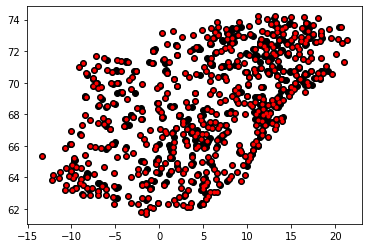

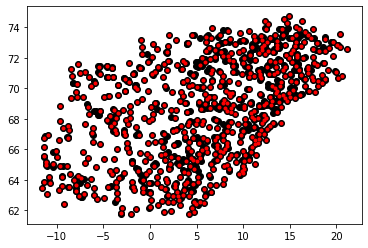

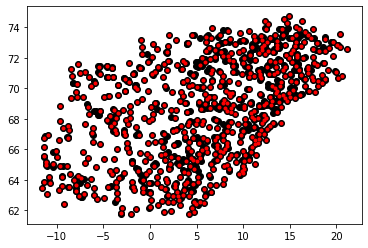

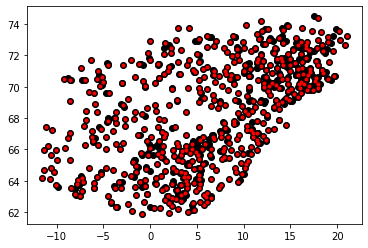

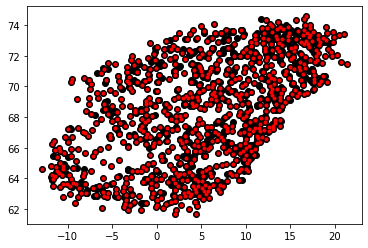

...

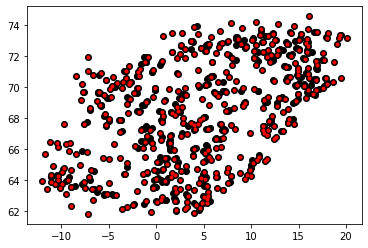

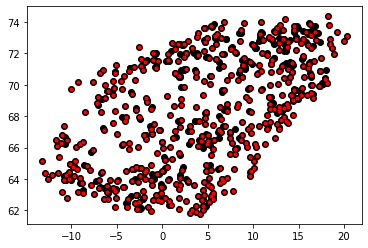

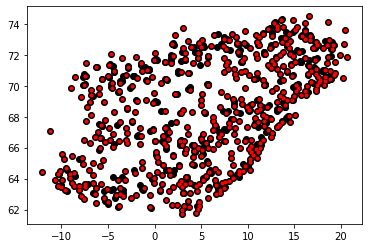

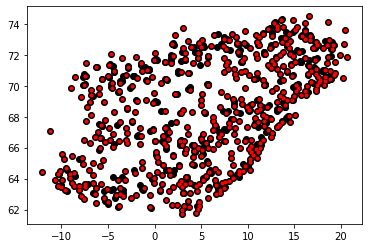

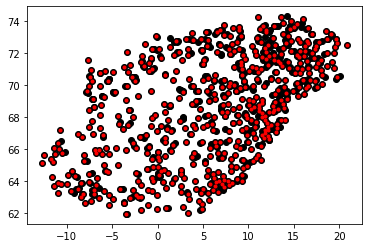

cleaning
interpolating
SAVE !!!!
cleaning
NA-2425-v3_0
load detection
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_NA-2425-v3_0/00_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_NA-2425-v3_0/01_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_NA-2425-v3_0/02_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_NA-2425-v3_0/03_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_NA-2425-v3_0/04_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detectio

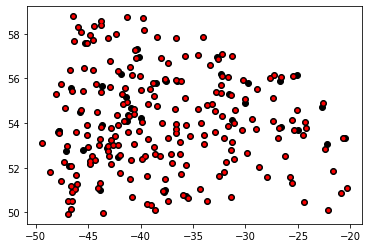

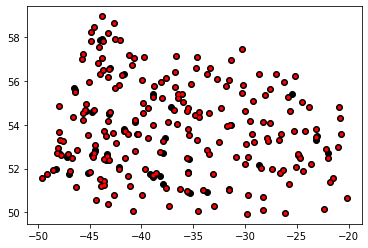

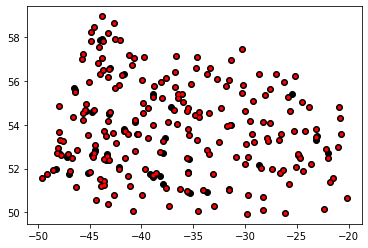

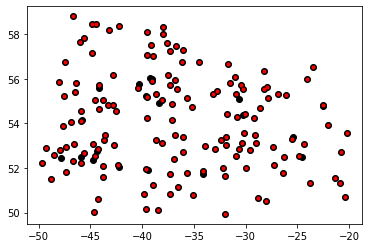

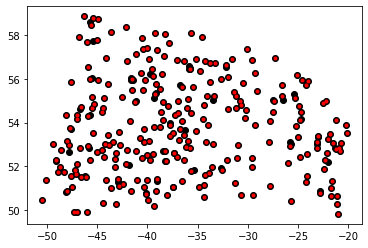

...

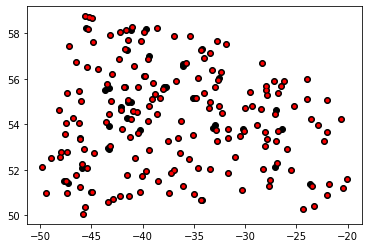

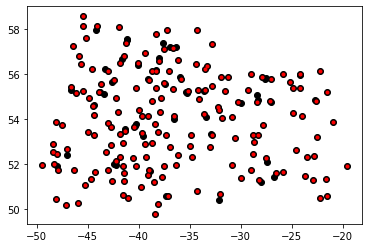

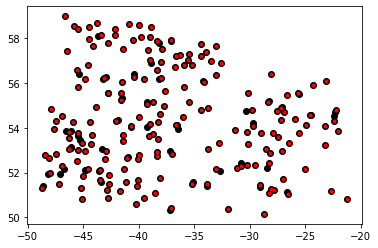

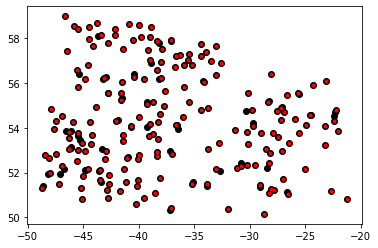

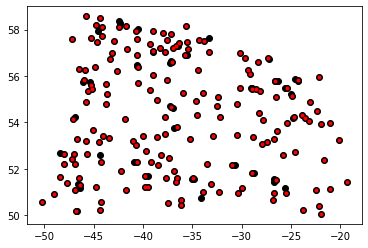

cleaning
interpolating
SAVE !!!!
cleaning
Pacific3bis-2425-v3_0
load detection
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific3bis-2425-v3_0/00_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific3bis-2425-v3_0/01_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific3bis-2425-v3_0/02_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific3bis-2425-v3_0/03_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific3bis-2425-v3_0/04_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SEC

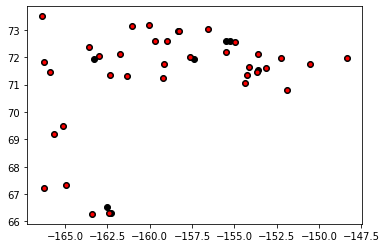

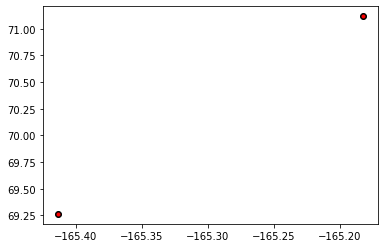

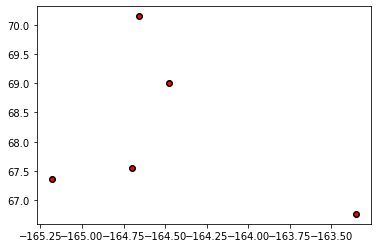

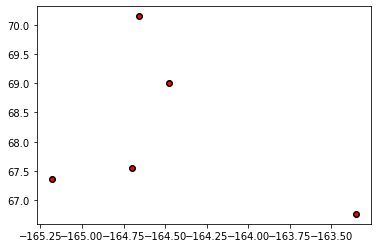

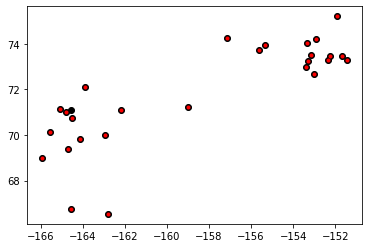

...

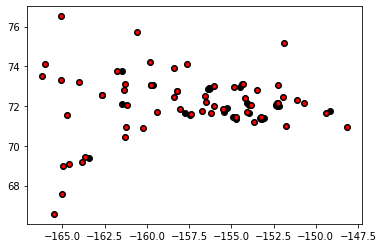

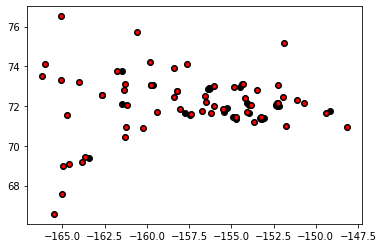

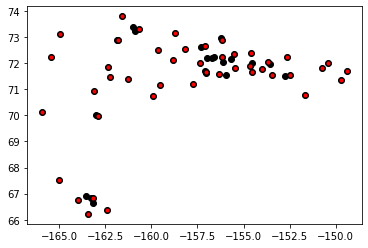

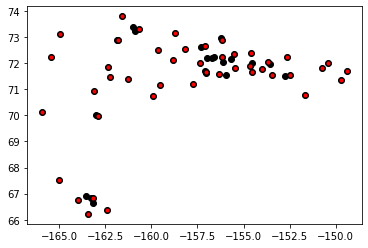

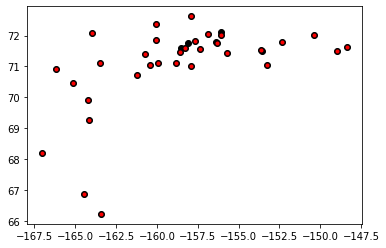

cleaning
interpolating
SAVE !!!!
cleaning
Pacific4-2425-v3_0
load detection
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific4-2425-v3_0/00_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific4-2425-v3_0/01_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific4-2425-v3_0/02_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific4-2425-v3_0/03_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/detection_on_SLA_Pacific4-2425-v3_0/04_detection3_pt_40_ct_0.6_Rmin_05_Amin_0.01_shapeerror_85.nc
/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/S

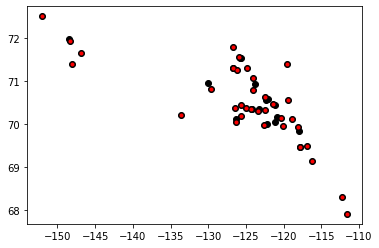

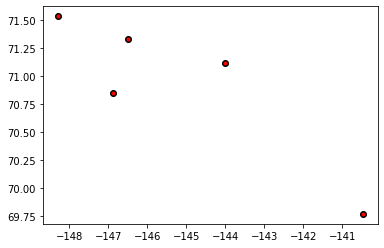

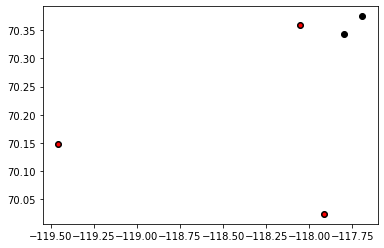

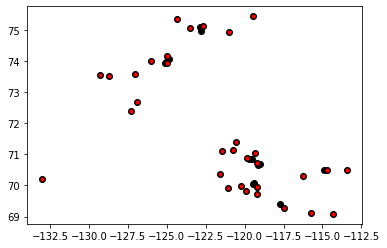

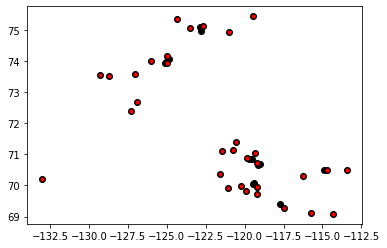

...

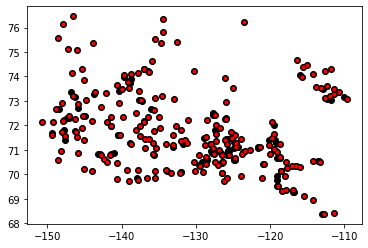

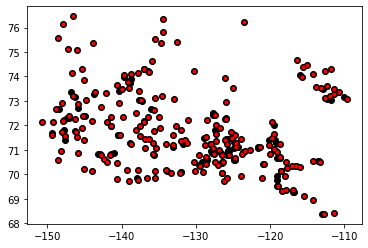

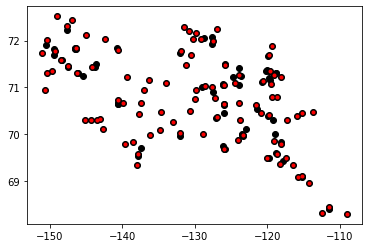

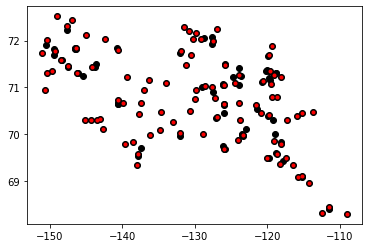

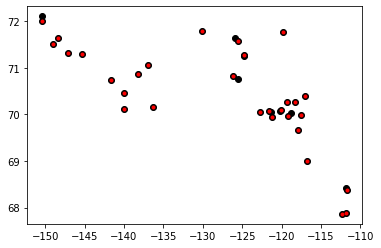

cleaning
interpolating
SAVE !!!!
cleaning


In [13]:
extraction_names=['Labrador-2425-v3_0',
                  'Irminger-2425-v3_0',
                  'Greenland-2425-v3_0',
                  'Baffin-2425-v3_0',
                  'Iceland-2425-v3_0',
                  'Norwegian-2425-v3_0',
                  'NA-2425-v3_0',
                  'Pacific3bis-2425-v3_0',
                  'Pacific4-2425-v3_0',]


run_on='SLA'
filtering=''




for extraction_name in extraction_names:
    print(extraction_name)

    
    name_case=filtering+run_on
    path_root='/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/'
    path_save=path_root+'detection_on_'+run_on+'_'+extraction_name+'/'
    namefile2='post-proc-data-detection_'+'pt_'+str(perc_thr).zfill(2)+'_ct_'+str(central_tol).zfill(3)+'_Rmin_'+str(Rmin).zfill(2)+'_Amin_'+str(Amin).zfill(2)+'_shapeerror_'+str(shape_err).zfill(2)+'.nc'
    
    
    if True:#len(glob.glob(path_save+namefile2))==0:



        print('load detection')


        #loop because of the chunks

        if extraction_name=='Norwegian-2425-v3_0':
            namefiles=glob.glob(path_save+'*detection2_*.nc');namefiles.sort()
        else:
            namefiles=glob.glob(path_save+'*detection3_*.nc');namefiles.sort()
        lon_all=[]
        lat_all=[]
        juld_all=[]
        cycle_all=[]
        r_all=[]
        v_all=[]
        a_all=[]
        perc_gaps_all=[]
        pol_all=[]
        contour_lon_all=[]
        contour_lat_all=[]
        ipass_all=[]
        cycles_avail=[]


        for namefile in namefiles:
            print(namefile)
            nc=Dataset(namefile)
            lon_all.append(nc['lon'][:])
            lat_all.append(nc['lat'][:])
            juld_all.append(nc['juld'][:])
            cycle_all.append(nc['cycle'][:])
            r_all.append(nc['r'][:])
            v_all.append(nc['v'][:])
            a_all.append(nc['a'][:])
            perc_gaps_all.append(nc['perc_gaps'][:])
            pol_all.append(nc['pol'][:])
            contour_lon_all.append(nc['clon'][:])
            contour_lat_all.append(nc['clat'][:])
            ipass_all.append(nc['ipass'][:])
            cycles_avail.append(np.unique(nc['cycle'][:]))
            nc.close()

        lon_all=np.concatenate(lon_all,axis=0)
        lat_all=np.concatenate(lat_all,axis=0)
        juld_all=np.concatenate(juld_all,axis=0)
        cycle_all=np.concatenate(cycle_all,axis=0)
        r_all=np.concatenate(r_all,axis=0)
        v_all=np.concatenate(v_all,axis=0)
        a_all=np.concatenate(a_all,axis=0)
        perc_gaps_all=np.concatenate(perc_gaps_all,axis=0)
        pol_all=np.concatenate(pol_all,axis=0)
        contour_lon_all=np.concatenate(contour_lon_all,axis=0)
        contour_lat_all=np.concatenate(contour_lat_all,axis=0)
        ipass_all=np.concatenate(ipass_all,axis=0)
        cycles_avail=np.concatenate(cycles_avail,axis=0)


        lon_all=np.where(lon_all>180,lon_all-360,lon_all)

        lon_all_ok=[]
        lat_all_ok=[]
        contour_lon_all_ok=[]
        contour_lat_all_ok=[]
        ipass_all_ok=[]
        pol_all_ok=[]
        juld_all_ok=[]
        cycle_all_ok=[]
        r_all_ok=[]
        v_all_ok=[]
        a_all_ok=[]
        perc_gaps_all_ok=[]








        for icycle in range(len(cycles_avail)):
            take_cycle=cycle_all==cycles_avail[icycle]

            #first version, the threshold is just a fix number
            #unique_positions, unique_indices =\
            #remove_duplicate_eddies(np.array([lon_all[take_cycle],lat_all[take_cycle]]).T,
            #                        threshold_km=20)
            #second version: the threshold is added to the radius of eddies
            unique_positions, unique_indices =\
            remove_duplicate_eddies2(np.array([lon_all[take_cycle],lat_all[take_cycle]]).T,
                                    r_all[take_cycle],
                                    threshold_km=10)


            lon_all_ok.append(lon_all[take_cycle][unique_indices])
            lat_all_ok.append(lat_all[take_cycle][unique_indices])
            contour_lon_all_ok.append(contour_lon_all[take_cycle][unique_indices])
            contour_lat_all_ok.append(contour_lat_all[take_cycle][unique_indices])
            ipass_all_ok.append(ipass_all[take_cycle][unique_indices])
            pol_all_ok.append(pol_all[take_cycle][unique_indices])

            juld_all_ok.append(juld_all[take_cycle][unique_indices])
            cycle_all_ok.append(cycle_all[take_cycle][unique_indices])
            r_all_ok.append(r_all[take_cycle][unique_indices])
            v_all_ok.append(v_all[take_cycle][unique_indices])
            a_all_ok.append(a_all[take_cycle][unique_indices])
            perc_gaps_all_ok.append(perc_gaps_all[take_cycle][unique_indices])


            plt.plot(lon_all[take_cycle],lat_all[take_cycle],'ok')
            plt.plot(np.array(unique_positions).T[0],np.array(unique_positions).T[1],'.r')
            plt.show()

        lon_all_ok=np.concatenate(lon_all_ok)
        lat_all_ok=np.concatenate(lat_all_ok)
        contour_lon_all_ok=np.concatenate(contour_lon_all_ok)
        contour_lat_all_ok=np.concatenate(contour_lat_all_ok)
        ipass_all_ok=np.concatenate(ipass_all_ok)
        pol_all_ok=np.concatenate(pol_all_ok)
        juld_all_ok=np.concatenate(juld_all_ok)
        cycle_all_ok=np.concatenate(cycle_all_ok)
        r_all_ok=np.concatenate(r_all_ok)
        v_all_ok=np.concatenate(v_all_ok)
        a_all_ok=np.concatenate(a_all_ok)
        perc_gaps_all_ok=np.concatenate(perc_gaps_all_ok)

        print('cleaning')
        lon_all=[]
        lat_all=[]
        juld_all=[]
        cycle_all=[]
        r_all=[]
        v_all=[]
        a_all=[]
        perc_gaps_all=[]
        pol_all=[]
        contour_lon_all=[]
        contour_lat_all=[]
        ipass_all=[]
        cycles_avail=[]


        print('interpolating')
        #Rd_all_ok = superfast_griddata_1D_nearest(lon_Rd,lat_Rd,Rd_Chelton,
        #                                         lon_all_ok,lat_all_ok)
        #depth_all_ok = superfast_griddata_1D_nearest(lontopo,lattopo,topo,
        #                                         lon_all_ok,lat_all_ok)
        #ice_all_ok = superfast_griddata_1D_nearest_with_time(lon_ice,lat_ice,juld_ice,ice_conc,
        #                                         lon_all_ok,lat_all_ok,juld_all_ok)




        #save this just for latter
        print('SAVE !!!!')
        nc_save=Dataset(path_save+namefile2, 'w',  format='NETCDF4_CLASSIC')
        nc_save.createDimension('eddies_dim',v_all_ok.shape[0])
        nc_save.createDimension('cont_dim',contour_lon_all_ok.shape[1])
        lon_var=nc_save.createVariable('lon', np.float32, ('eddies_dim',))
        lat_var=nc_save.createVariable('lat', np.float32, ('eddies_dim',))
        clon_var=nc_save.createVariable('clon', np.float32, ('eddies_dim','cont_dim'))
        clat_var=nc_save.createVariable('clat', np.float32, ('eddies_dim','cont_dim'))
        r_var=nc_save.createVariable('r', np.float32, ('eddies_dim',))
        v_var=nc_save.createVariable('v', np.float32, ('eddies_dim',))
        a_var=nc_save.createVariable('a', np.float32, ('eddies_dim',))
        pol_var=nc_save.createVariable('pol', np.float32, ('eddies_dim',))
        cycle_var=nc_save.createVariable('cycle', np.float32, ('eddies_dim',))
        juld_var=nc_save.createVariable('juld', np.float32, ('eddies_dim',))
        ipass_var=nc_save.createVariable('ipass', np.float32, ('eddies_dim',))
        ice_var=nc_save.createVariable('ice_conc', np.float32, ('eddies_dim',))
        depth_var=nc_save.createVariable('depth', np.float32, ('eddies_dim',))
        Rd_var=nc_save.createVariable('Rd', np.float32, ('eddies_dim',))
        lon_var[:]=lon_all_ok
        lat_var[:]=lat_all_ok
        clon_var[:]=contour_lon_all_ok
        clat_var[:]=contour_lat_all_ok
        r_var[:]=r_all_ok
        v_var[:]=v_all_ok
        ipass_var[:]=ipass_all_ok
        a_var[:]=a_all_ok
        pol_var[:]=pol_all_ok
        juld_var[:]=juld_all_ok
        cycle_var[:]=cycle_all_ok

        #ice_var[:]=ice_all_ok
        #depth_var[:]=depth_all_ok
        #Rd_var[:]=Rd_all_ok

        nc_save.close()

        

        print('cleaning')
        lon_all_ok=[]
        lat_all_ok=[]
        contour_lon_all_ok=[]
        contour_lat_all_ok=[]
        ipass_all_ok=[]
        pol_all_ok=[]
        juld_all_ok=[]
        cycle_all_ok=[]
        r_all_ok=[]
        v_all_ok=[]
        a_all_ok=[]
        perc_gaps_all_ok=[]


    

In [14]:
# do the saving of ice-topo !!!

extraction_names=['Labrador-2425-v3_0',
                  'Irminger-2425-v3_0',
                  'Greenland-2425-v3_0',
                  'Baffin-2425-v3_0',
                  'Iceland-2425-v3_0',
                  'Norwegian-2425-v3_0',
                  'NA-2425-v3_0',
                  'Pacific3bis-2425-v3_0',
                  'Pacific4-2425-v3_0',]


#['Pacific1-2425-v3_0']

run_on='SLA'
filtering=''


lon_all_allareas={}
lat_all_allareas={}
contour_lon_all_allareas={}
contour_lat_all_allareas={}
ipass_all_allareas={}
pol_all_allareas={}
juld_all_allareas={}
cycle_all_allareas={}
r_all_allareas={}
v_all_allareas={}
a_all_allareas={}
perc_gaps_all_allareas={}

ice_all_allareas={}
Rd_all_allareas={}
depth_all_allareas={}

for extraction_name in extraction_names:
    print(extraction_name)

    
    name_case=filtering+run_on
    path_root='/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/'
    path_save=path_root+'detection_on_'+run_on+'_'+extraction_name+'/'
    namefile2='post-proc-data-detection_'+'pt_'+str(perc_thr).zfill(2)+'_ct_'+str(central_tol).zfill(3)+'_Rmin_'+str(Rmin).zfill(2)+'_Amin_'+str(Amin).zfill(2)+'_shapeerror_'+str(shape_err).zfill(2)+'.nc'
    namefile3='ice-topo-detection_'+'pt_'+str(perc_thr).zfill(2)+'_ct_'+str(central_tol).zfill(3)+'_Rmin_'+str(Rmin).zfill(2)+'_Amin_'+str(Amin).zfill(2)+'_shapeerror_'+str(shape_err).zfill(2)+'.nc'
    
    
    if True:#len(glob.glob(path_save+namefile3))==0:


        
        nc=Dataset(path_save+namefile2)
        lon_all_ok=nc['lon'][:]
        lat_all_ok=nc['lat'][:]
        juld_all_ok=nc['juld'][:]
        nc.close()


        Rd_all_ok = superfast_griddata_1D_nearest(lon_Rd,lat_Rd,Rd_Chelton,
                                                 lon_all_ok,lat_all_ok)
        depth_all_ok = superfast_griddata_1D_nearest(lontopo,lattopo,topo,
                                                 lon_all_ok,lat_all_ok)

        ice_all_ok = superfast_griddata_1D_nearest_with_time(lon_ice,lat_ice,juld_ice,ice_conc,
                                                 lon_all_ok,lat_all_ok,juld_all_ok)

        
        
        
        #save this just for latter
        print('SAVE !!!!')
        nc_save=Dataset(path_save+namefile3, 'w',  format='NETCDF4_CLASSIC')
        nc_save.createDimension('eddies_dim',ice_all_ok.shape[0])
        ice_var=nc_save.createVariable('ice_conc', np.float32, ('eddies_dim',))
        depth_var=nc_save.createVariable('depth', np.float32, ('eddies_dim',))
        Rd_var=nc_save.createVariable('Rd', np.float32, ('eddies_dim',))
        ice_var[:]=ice_all_ok
        depth_var[:]=depth_all_ok
        Rd_var[:]=Rd_all_ok
        nc_save.close()


        Rd_all_ok = []
        depth_all_ok = [] 

        ice_all_ok = []

Labrador-2425-v3_0
SAVE !!!!
Irminger-2425-v3_0
SAVE !!!!
Greenland-2425-v3_0
SAVE !!!!
Baffin-2425-v3_0
SAVE !!!!
Iceland-2425-v3_0
SAVE !!!!
Norwegian-2425-v3_0
SAVE !!!!
NA-2425-v3_0
SAVE !!!!
Pacific3bis-2425-v3_0
SAVE !!!!
Pacific4-2425-v3_0
SAVE !!!!


# read it

In [55]:
extraction_names=['Labrador-2425-v3_0',
                  'Irminger-2425-v3_0',
                  'Greenland-2425-v3_0',
                  'Baffin-2425-v3_0',
                  'Iceland-2425-v3_0',
                  'Norwegian-2425-v3_0',
                  'NA-2425-v3_0',
                  'Pacific3bis-2425-v3_0',
                  'Pacific4-2425-v3_0',]

#['Pacific1-2425-v3_0']

run_on='SLA'
filtering=''


lon_all_allareas={}
lat_all_allareas={}
contour_lon_all_allareas={}
contour_lat_all_allareas={}
ipass_all_allareas={}
pol_all_allareas={}
juld_all_allareas={}
cycle_all_allareas={}
r_all_allareas={}
v_all_allareas={}
a_all_allareas={}
perc_gaps_all_allareas={}

ice_all_allareas={}
Rd_all_allareas={}
depth_all_allareas={}

for extraction_name in extraction_names:
    print(extraction_name)

    
    name_case=filtering+run_on
    path_root='/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/Eddy_detection_v3/'
    path_save=path_root+'detection_on_'+run_on+'_'+extraction_name+'/'
    namefile2='post-proc-data-detection_'+'pt_'+str(perc_thr).zfill(2)+'_ct_'+str(central_tol).zfill(3)+'_Rmin_'+str(Rmin).zfill(2)+'_Amin_'+str(Amin).zfill(2)+'_shapeerror_'+str(shape_err).zfill(2)+'.nc'
    namefile3='ice-topo-detection_'+'pt_'+str(perc_thr).zfill(2)+'_ct_'+str(central_tol).zfill(3)+'_Rmin_'+str(Rmin).zfill(2)+'_Amin_'+str(Amin).zfill(2)+'_shapeerror_'+str(shape_err).zfill(2)+'.nc'
    

    nc=Dataset(path_save+namefile2)
    lon_all_allareas[extraction_name]=nc['lon'][:]
    lat_all_allareas[extraction_name]=nc['lat'][:]
    contour_lon_all_allareas[extraction_name]=nc['clon'][:] #need to save this one
    contour_lat_all_allareas[extraction_name]=nc['clat'][:]
    ipass_all_allareas[extraction_name]=nc['ipass'][:]
    pol_all_allareas[extraction_name]=nc['pol'][:]
    juld_all_allareas[extraction_name]=nc['juld'][:]
    cycle_all_allareas[extraction_name]=nc['cycle'][:]
    r_all_allareas[extraction_name]=nc['r'][:]
    v_all_allareas[extraction_name]=nc['v'][:]
    a_all_allareas[extraction_name]=nc['a'][:]
    nc.close()
    
    nc=Dataset(path_save+namefile3)
    ice_all_allareas[extraction_name]=nc['ice_conc'][:]
    depth_all_allareas[extraction_name]=nc['depth'][:]
    Rd_all_allareas[extraction_name]=nc['Rd'][:]
    nc.close()

    

Labrador-2425-v3_0
Irminger-2425-v3_0
Greenland-2425-v3_0
Baffin-2425-v3_0
Iceland-2425-v3_0
Norwegian-2425-v3_0
NA-2425-v3_0
Pacific3bis-2425-v3_0
Pacific4-2425-v3_0


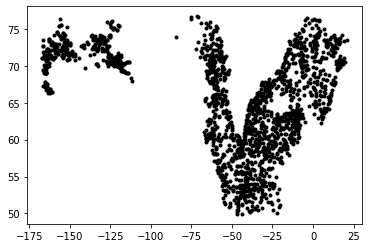

In [47]:
for extraction_name in extraction_names:


    for ieddy in range(200):
        plt.plot(lon_all_allareas[extraction_name][ieddy],lat_all_allareas[extraction_name][ieddy],'.k')
plt.show()

## Do some processing of the sea ice

In [48]:
#to sort eddies
min_depth=-500 #just the shelf
max_ice_conc=15


#il faut prendre 15%
#https://www.annualreviews.org/docserver/fulltext/marine/17/1/annurev-marine-121422-015323.pdf?expires=1762793062&id=id&accname=guest&checksum=94D7B0D777F47C0FA3A77B8A5F3F6B8C


In [51]:
cycles_avail=np.unique(cycle_all_ok)

In [62]:
cycles_avail=np.arange(cycle_all_allareas[extraction_names[0]][0],cycle_all_allareas[extraction_names[0]][-1]+1,1)

In [63]:
cycles_avail

array([ 6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16., 17., 18.,
       19., 20., 21., 22., 23., 24., 25., 26., 27., 28., 29., 30., 31.,
       32., 33., 34., 35., 36., 37., 38., 39., 40., 41.])

from 02/11/2023 to 23/11/2023


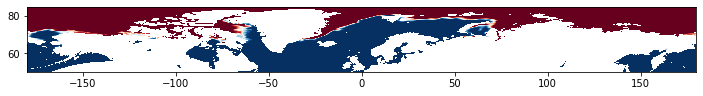

from 23/11/2023 to 13/12/2023


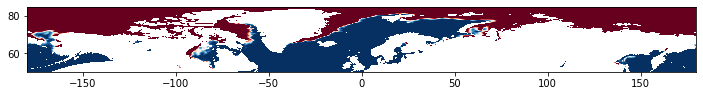

from 14/12/2023 to 03/01/2024


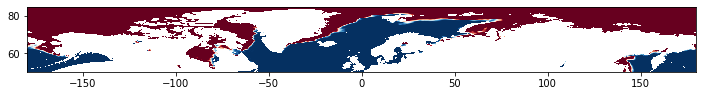

from 04/01/2024 to 24/01/2024


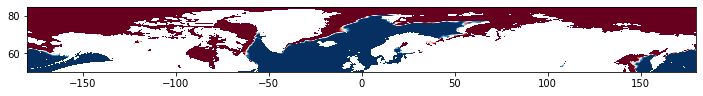

from 25/01/2024 to 14/02/2024


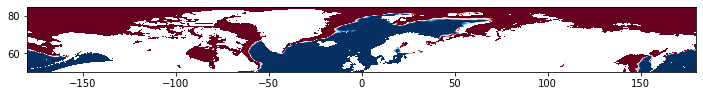

from 15/02/2024 to 06/03/2024


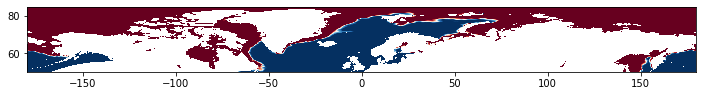

from 06/03/2024 to 27/03/2024


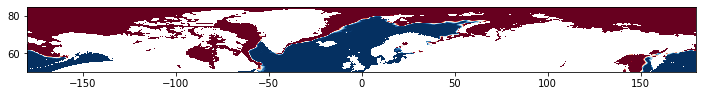

from 27/03/2024 to 16/04/2024


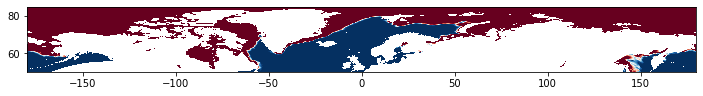

from 17/04/2024 to 07/05/2024


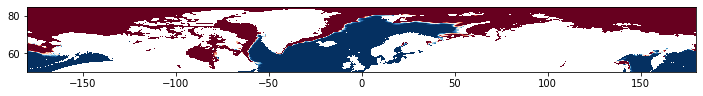

from 08/05/2024 to 28/05/2024


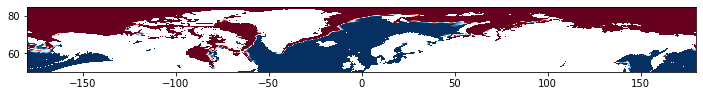

from 29/05/2024 to 18/06/2024


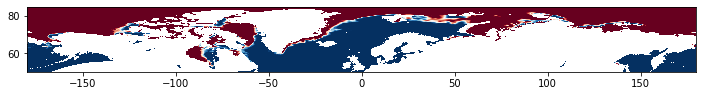

from 19/06/2024 to 09/07/2024


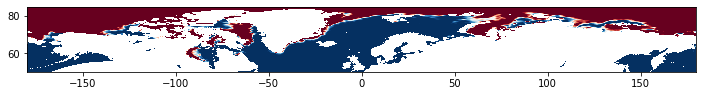

from 10/07/2024 to 30/07/2024


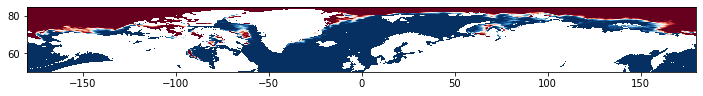

from 31/07/2024 to 20/08/2024


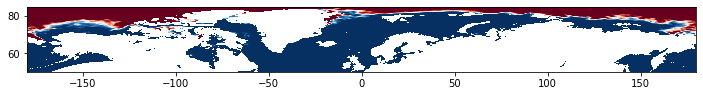

from 20/08/2024 to 10/09/2024


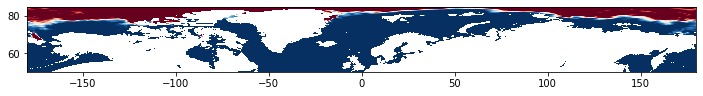

from 10/09/2024 to 30/09/2024


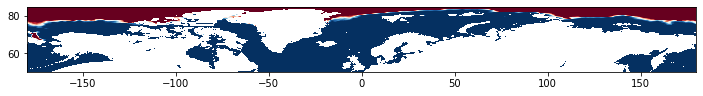

from 01/10/2024 to 21/10/2024


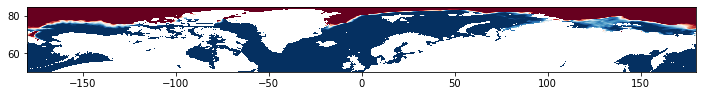

from 22/10/2024 to 11/11/2024


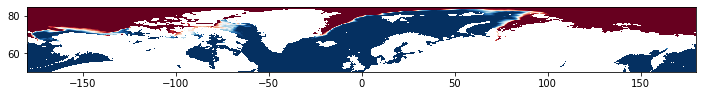

from 12/11/2024 to 02/12/2024


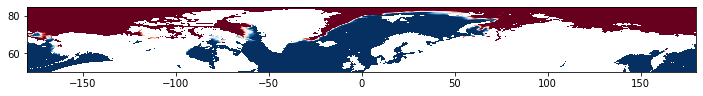

from 03/12/2024 to 23/12/2024


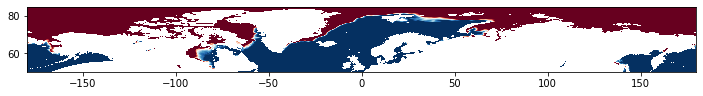

from 24/12/2024 to 10/01/2025


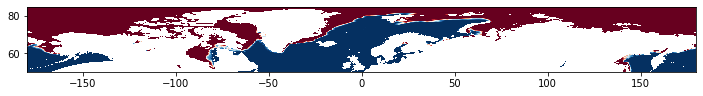

from 13/01/2025 to 02/02/2025


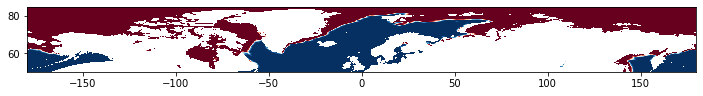

from 03/02/2025 to 24/02/2025


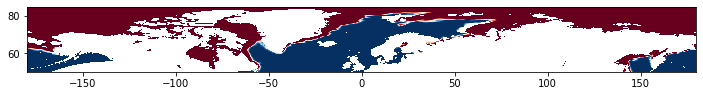

from 24/02/2025 to 16/03/2025


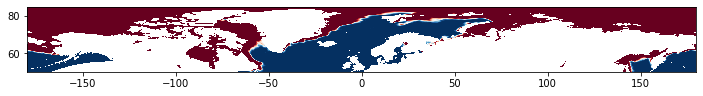

from 17/03/2025 to 06/04/2025


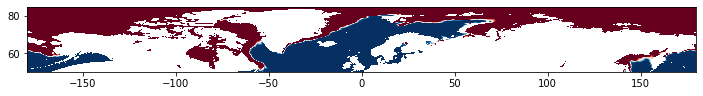

from 07/04/2025 to 27/04/2025


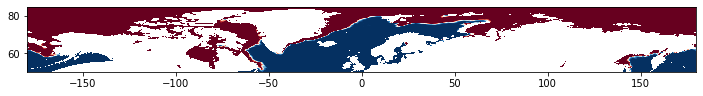

from 28/04/2025 to 01/05/2025


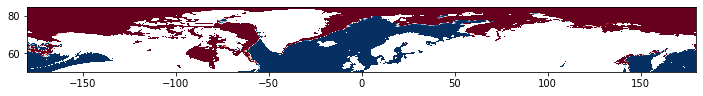

from 19/05/2025 to 08/06/2025


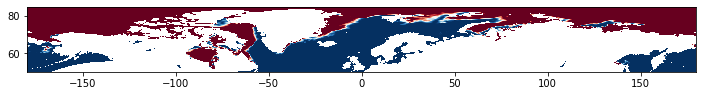

from 08/06/2025 to 29/06/2025


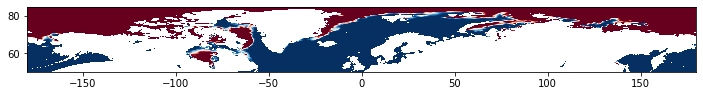

from 29/06/2025 to 20/07/2025


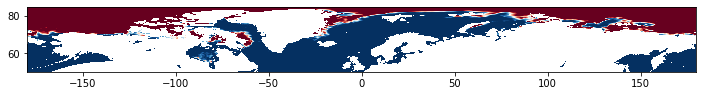

from 20/07/2025 to 09/08/2025


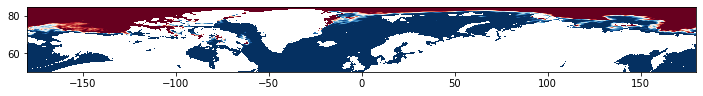

from 11/08/2025 to 30/08/2025


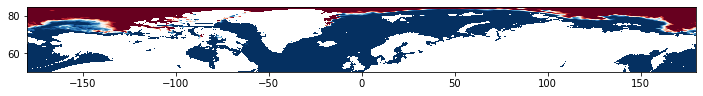

from 31/08/2025 to 20/09/2025


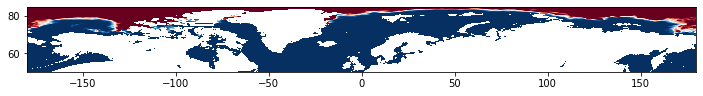

from 21/09/2025 to 11/10/2025


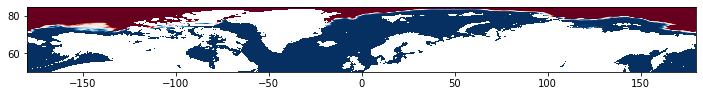

from 12/10/2025 to 01/11/2025


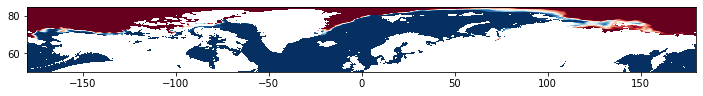

from 02/11/2025 to 22/11/2025


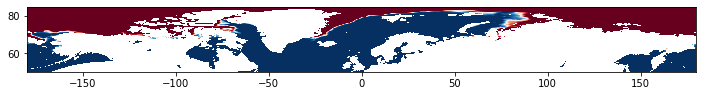

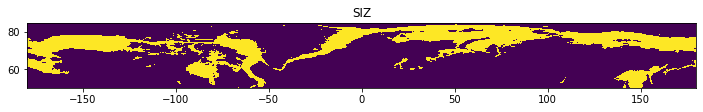

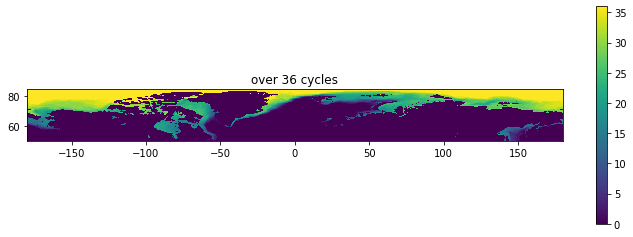

In [64]:


# do average of ice concentration for each cycle !!

extraction_name=extraction_names[0] #same for all

ice_mean_per_cycle=[]
for icycle in range(len(cycles_avail)):
    take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]

    minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
    maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

    print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

    take_period_ice=(juld_ice>minjuld)&(juld_ice<maxjuld)

    ice_mean_thiscycle=np.nanmean(ice_conc[take_period_ice,:,:],axis=0)

    plt.figure(figsize=(12,4))
    ax=plt.subplot(111,aspect='equal')
    plt.pcolormesh(lon_ice,lat_ice,ice_mean_thiscycle,vmin=0,vmax=50,cmap='RdBu_r')
    plt.show()


    ice_mean_per_cycle.append(ice_mean_thiscycle)
    
ice_mean_per_cycle=np.array(ice_mean_per_cycle)    
    


# Identify where ice exists seasonally : Seasonnal Ice Zone SIZ
#see
#https://www.annualreviews.org/docserver/fulltext/marine/17/1/annurev-marine-121422-015323.pdf?expires=1762793062&id=id&accname=guest&checksum=94D7B0D777F47C0FA3A77B8A5F3F6B8C
# marginal ice zone is between 15% and 80%, but taking eddies in this area is tricky !!! will be done in future work

ice_mask = ice_mean_per_cycle > max_ice_conc
ice_any = np.any(ice_mask, axis=0)
ice_all = np.all(ice_mask, axis=0)
seasonal_ice_covered_zone_mask = ice_any & (~ice_all)

n_cycles_ice_covered = np.sum(ice_mask, axis=0)


plt.figure(figsize=(12,4))
ax=plt.subplot(111,aspect='equal')
plt.title('SIZ')
plt.pcolormesh(lon_ice,lat_ice,seasonal_ice_covered_zone_mask)
plt.show()

plt.figure(figsize=(12,4))
ax=plt.subplot(111,aspect='equal')
plt.title('over {} cycles'.format(len(cycles_avail)))
plt.pcolormesh(lon_ice,lat_ice,n_cycles_ice_covered)
plt.colorbar()
plt.show()


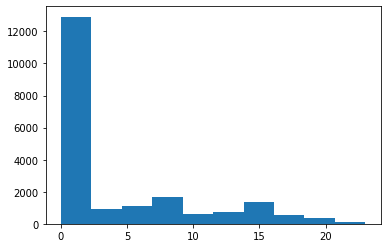

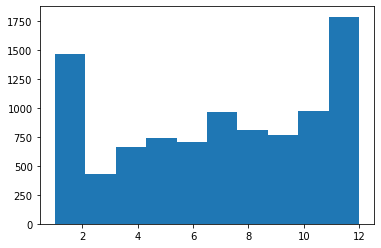

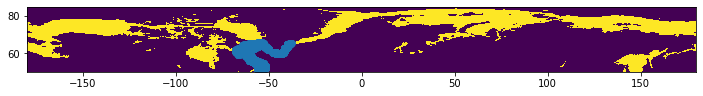

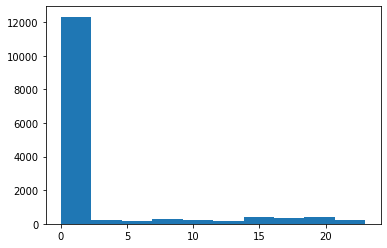

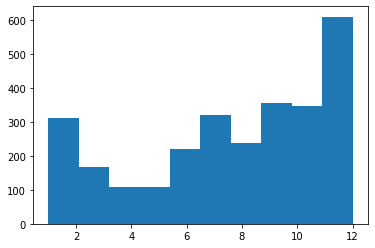

...

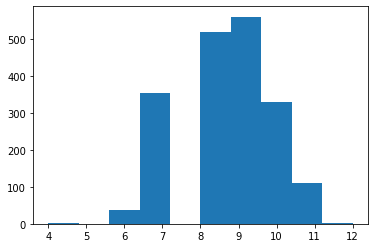

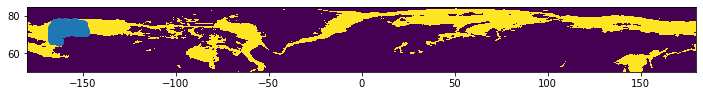

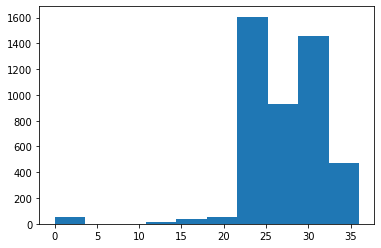

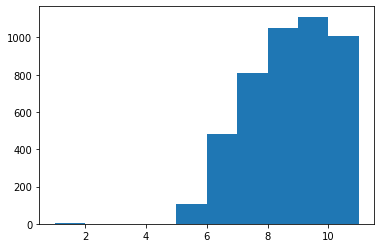

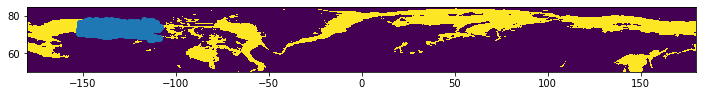

In [65]:
# Now extract eddies in the SIZ

n_ice_at_eddy_all_allareas={}
in_SIZ_all_allareas={}
month_in_SIZ_all_allareas={}

for extraction_name in extraction_names:


    

    from scipy.spatial import cKDTree

    pts_grid = np.column_stack((lon_ice.ravel(), lat_ice.ravel()))
    tree = cKDTree(pts_grid)


    pts_eddy = np.column_stack((lon_all_allareas[extraction_name], lat_all_allareas[extraction_name]))
    _, idx = tree.query(pts_eddy, k=1)
    #in_SIZ = seasonal_mask.ravel()[idx] #this is the mask for only eddies in the SIZ

    # the number of cycles covered by ice at the eddy location
    n_ice_at_eddy = n_cycles_ice_covered .ravel()[idx]
    in_SIZ=n_ice_at_eddy>0

    plt.hist(n_ice_at_eddy)
    plt.show()

    #month when detection :

    month_in_SIZ=np.array([OrdinalToDatetime(int(i-1721424.5)).month for i in juld_all_allareas[extraction_name][in_SIZ]])
    plt.hist(month_in_SIZ)
    plt.show()


    plt.figure(figsize=(12,4))
    ax=plt.subplot(111,aspect='equal')
    plt.pcolormesh(lon_ice,lat_ice,seasonal_ice_covered_zone_mask)
    plt.plot(lon_all_allareas[extraction_name][in_SIZ], lat_all_allareas[extraction_name][in_SIZ],'o')

    plt.show()
    
    
    n_ice_at_eddy_all_allareas[extraction_name]=np.copy(n_ice_at_eddy)
    in_SIZ_all_allareas[extraction_name]=np.copy(in_SIZ)
    month_in_SIZ_all_allareas[extraction_name]=np.copy(month_in_SIZ)

# start the good plots

In [417]:
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np


def make_curved_map_north(
    lat_min=50,central_longitude=0,
    figsize=(6, 6),
    lafont=14,facecol='w'
):

    fig = plt.figure(figsize=figsize)
    ax = plt.subplot(
        1, 1, 1,
        projection=ccrs.NorthPolarStereo(central_longitude=central_longitude),fc=facecol
    )

    # Geographic extent (North Hemisphere focus)
    ax.set_extent([-180, 180, lat_min, 90], crs=ccrs.PlateCarree())

    # Features
    ax.add_feature(cfeature.LAND, facecolor='grey', edgecolor='k', zorder=19)
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.2, zorder=20)

    # Gridlines
    
    gl = ax.gridlines(
        draw_labels=True,
        rotate_labels=False,
        x_inline=False,
        y_inline=False,
        linestyle='-',
        alpha=1#,zorder=1000
    )

    gl.xlabel_style = {'size': lafont}
    gl.ylabel_style = {'size': lafont}

    
    import matplotlib.ticker as mticker

    gl.xlocator = mticker.MultipleLocator(20)  # every 10° longitude
    #gl.ylocator = mticker.MultipleLocator(5)   # every 5° latitude


    # Circular boundary (same trick as south pole)
    theta = np.linspace(0, 2 * np.pi, 100)
    center, radius = [0.5, 0.5], 0.5
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    circle = mpath.Path(verts * radius + np.array(center))

    ax.set_boundary(circle, transform=ax.transAxes)
    
    for lat in [60, 70, 80]:
        ax.text(
            0, lat,               # lon=45°
            f"{lat}°N",
            transform=ccrs.PlateCarree(),
            fontsize=12,
            ha='left',
            va='center',
            rotation=-20,
            zorder=20000
        )

    return fig, ax

In [258]:
# areas 

pt_poly_all=[]

#Irminger
pt_poly=np.array([[-45,-34,-19,-40,-45],[59,57.5,64.5,68.5,59]])
pt_poly_all.append(pt_poly)

#Labrador
pt_poly=np.array([[-50,-60,-68,-38,-50],[50,52,64,68,50]])
pt_poly_all.append(pt_poly)

#Greenland
pt_poly=np.array([[-19,-40,-30,10,10,-8,-10,-19],[64.5,68.5,76,76,74,71,66,64.5]])
pt_poly_all.append(pt_poly)

#Baffin
pt_poly=np.array([[-68,-90,-50,-47,-68],[64,76,76,67.5,64]])
pt_poly_all.append(pt_poly)

#Norwegian
pt_poly=np.array([[10,-8,-10,-12,-5,10,20,20,10],[74,71,66,64,62,62,70,74,74]])
pt_poly_all.append(pt_poly)

#Iceland
pt_poly=np.array([[-5,-15,-19,-34,-22,-5],[62,65,64.5,57.5,56,62]])
pt_poly_all.append(pt_poly)

#North Atlantic
pt_poly=np.array([[-22,-34,-45,-50,-20,-22],[56,57.5,59,50,50,56]])
pt_poly_all.append(pt_poly)

#Pacific3bis
pt_poly=np.array([[-165,-160,-150,-150,-165,-165],[66,66,66,77,77,66]])
pt_poly_all.append(pt_poly)

#Pacific4
pt_poly=np.array([[-150,-110,-110,-150,-150],[66,66,77,77,66]])
pt_poly_all.append(pt_poly) 




# Plot the seasonally ice covered zone (SIZ)

color shows the number of cycle the area is covered by ice

https://www.annualreviews.org/docserver/fulltext/marine/17/1/annurev-marine-121422-015323.pdf?expires=1762793062&id=id&accname=guest&checksum=94D7B0D777F47C0FA3A77B8A5F3F6B8C


In [267]:
def clip_above_lat(ax, mappable, lat_cut=80):
    """
    Clip a plotted field so only lat >= lat_cut is visible.
    Continents and other map features are NOT affected.
    
    Parameters
    ----------
    ax : cartopy GeoAxes
    mappable : result of pcolormesh / contourf / imshow
    lat_cut : float
        Latitude cutoff (degrees North)
    """

    # Build polygon: whole world above lat_cut
    lons = np.linspace(-180, 180, 500)

    top = np.column_stack([lons, np.full_like(lons, 90)])
    bottom = np.column_stack([lons[::-1], np.full_like(lons, lat_cut)])

    verts = np.vstack([top, bottom])

    path = mpath.Path(verts)

    patch = mpatches.PathPatch(
        path,
        transform=ccrs.PlateCarree()
    )

    mappable.set_clip_path(patch)
    return mappable


def cut_the_map():
    import matplotlib.patches as mpatches
    lat_cut = 80
    lons = np.linspace(-180, 180, 400)
    lats = np.full_like(lons, lat_cut)
    # build the upper boundary (constant latitude circle)
    verts = np.column_stack([lons, lats])
    # close polygon by adding the pole loop
    pole = np.column_stack([lons[::-1], np.full_like(lons, 90)])

    poly = np.vstack([verts, pole])

    mask = mpatches.Polygon(
        poly,
        closed=True,
        facecolor='white',
        edgecolor='none',
        transform=ccrs.PlateCarree(),
        zorder=18
    )
    ax.add_patch(mask)
    
    # --- full figure overlay mask (hides EVERYTHING) ---
    top_mask = mpatches.Rectangle(
        (0, 0.515),   # figure coordinates
        1, 0.5,
        transform=fig.transFigure,  # IMPORTANT: figure space
        facecolor='white',
        edgecolor='none',
        zorder=10000
    )
    fig.add_artist(top_mask)

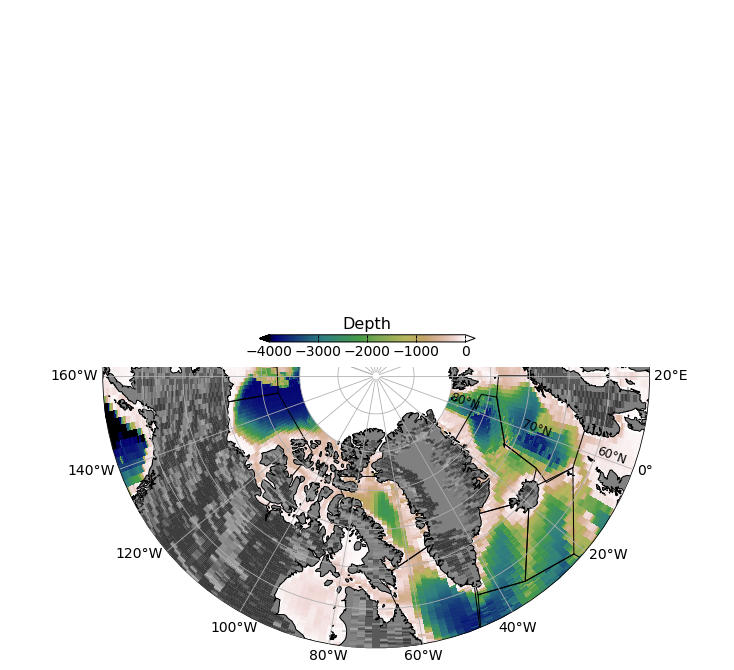

In [268]:


fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10))


for izone in range(len(pt_poly_all)):
    plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=1,zorder=10,
            transform=ccrs.PlateCarree())
from matplotlib.colors import LightSource
# Shade from the northwest, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=315, altdeg=45)
cmap = plt.cm.gist_earth
ve=[0.1, 1, 10]

plt.pcolormesh(lontopo,lattopo,ls.hillshade(topo_land, vert_exag=ve[0]), cmap='gray',alpha=0.3,zorder=101,
               transform=ccrs.PlateCarree())

pc1=plt.pcolormesh(lontopo,lattopo,topo,vmin=-4000,vmax=0,cmap='gist_earth',zorder=0,transform=ccrs.PlateCarree())
#plt.contour(lontopo,lattopo,topo,np.arange(-4000,100,100),colors='k',linewidths=0.5,linestyles=':',zorder=1,transform=ccrs.PlateCarree())


cut_the_map()






cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
cbar            = fig.colorbar( pc1 , cax=cbar_ax,extend='both',orientation='horizontal')#,ticks=np.arange(0,22,5))
plt.title( r'Depth',fontsize=16,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
cbar_ax.set_zorder(1e6)




plt.subplots_adjust(wspace=0.05) 
    
    




plt.show()

RuntimeError: Can not put single artist in more than one figure

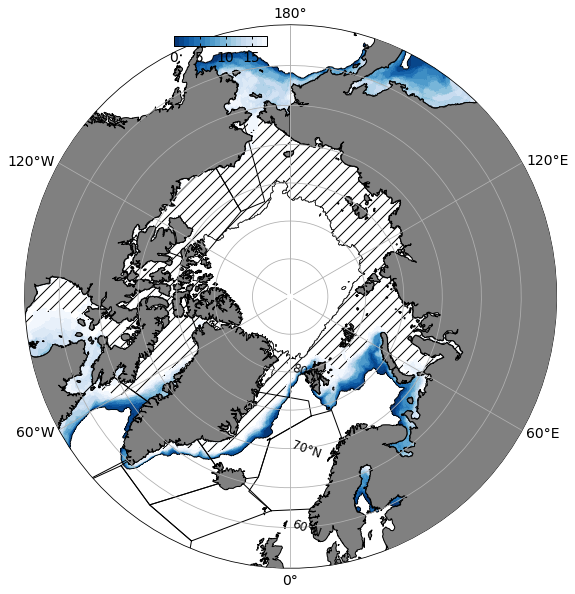

In [217]:


fig,ax=make_curved_map_north(lat_min=55,figsize=(10, 10))


for izone in range(len(pt_poly_all)):
    plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=1,zorder=10,
            transform=ccrs.PlateCarree())


plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
             colors='k',linestyle='-',linewidths=0.5,
             transform=ccrs.PlateCarree())
plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
             colors='none',
             hatches=['','//',],
             transform=ccrs.PlateCarree())

toplot=np.where(n_cycles_ice_covered==0,np.nan,n_cycles_ice_covered)
pc=plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,19,1),cmap='Blues_r',
             transform=ccrs.PlateCarree())



cut_the_map()
cbar_ax         = fig.add_axes( [0.35,0.85,0.13,0.015] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='both',orientation='horizontal',ticks=np.arange(0,25,5))
#plt.title( r'[]',fontsize=16,x=1 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
plt.subplots_adjust(wspace=0.05) 
    
    



plt.show()

# Show detection for one cycle

In [218]:
path_figs='./figs_all_north/'
#os.mkdir(path_figs)

from 02/11/2023 to 23/11/2023


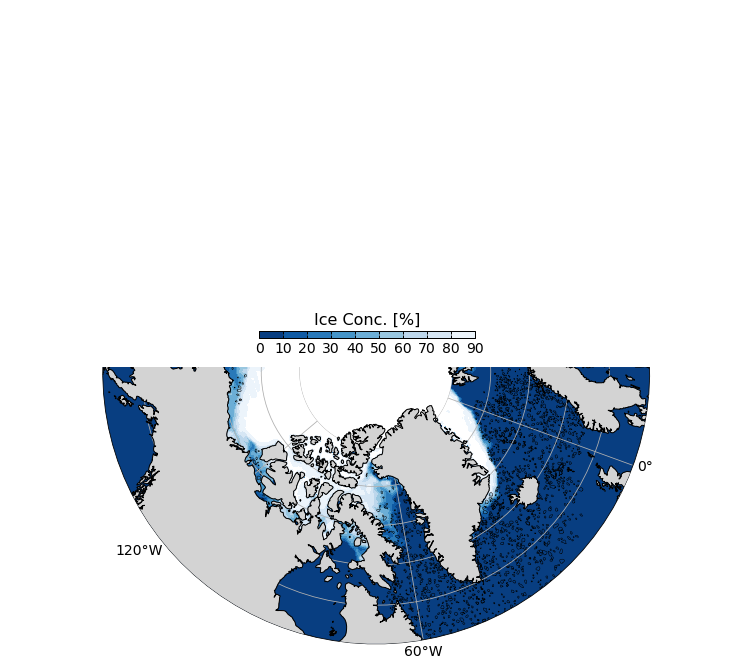

from 23/11/2023 to 13/12/2023


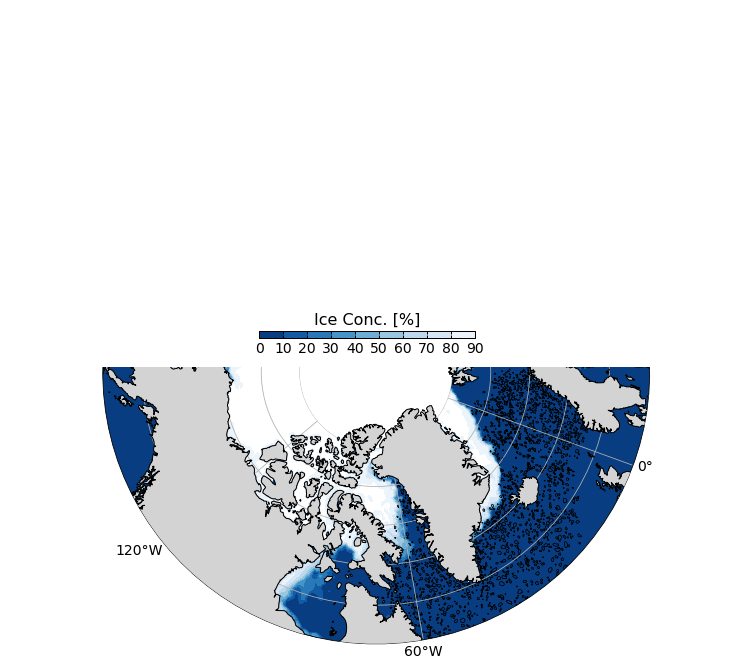

from 14/12/2023 to 03/01/2024


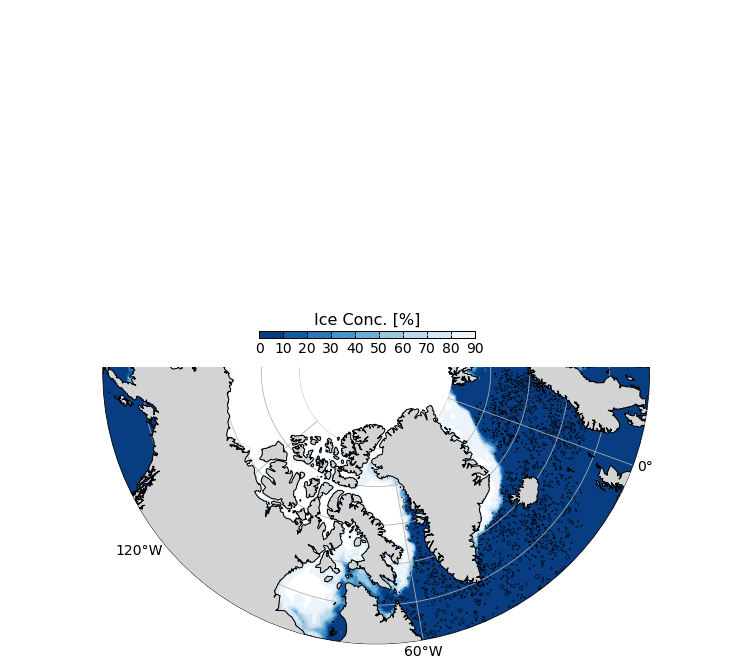

from 04/01/2024 to 24/01/2024


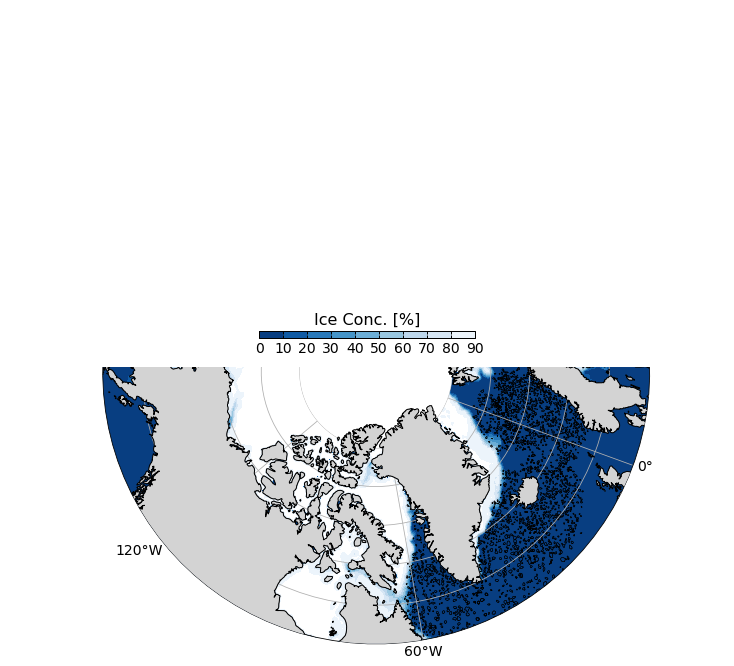

from 25/01/2024 to 14/02/2024


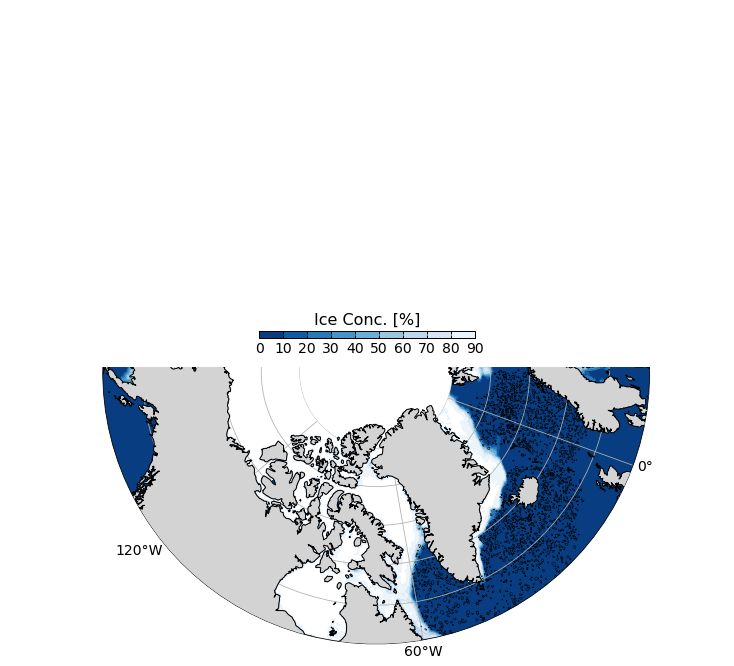

from 15/02/2024 to 06/03/2024


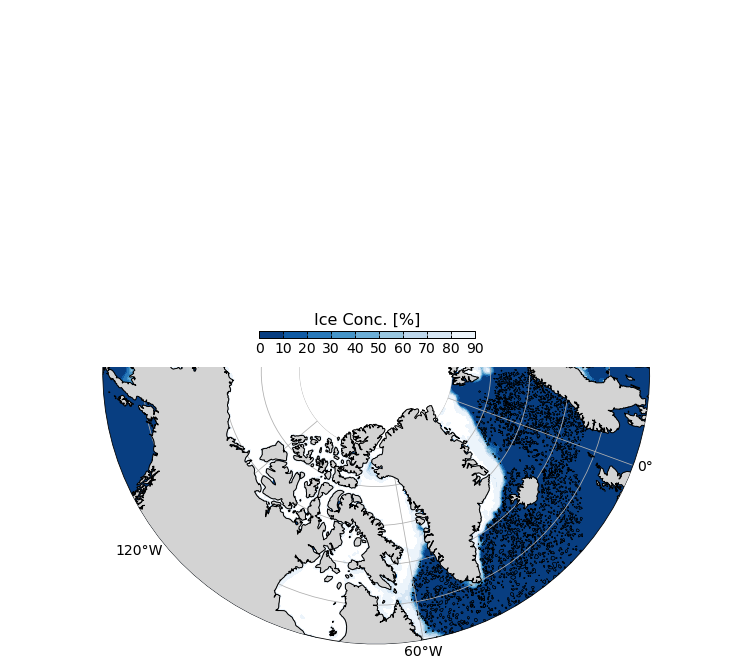

from 06/03/2024 to 27/03/2024


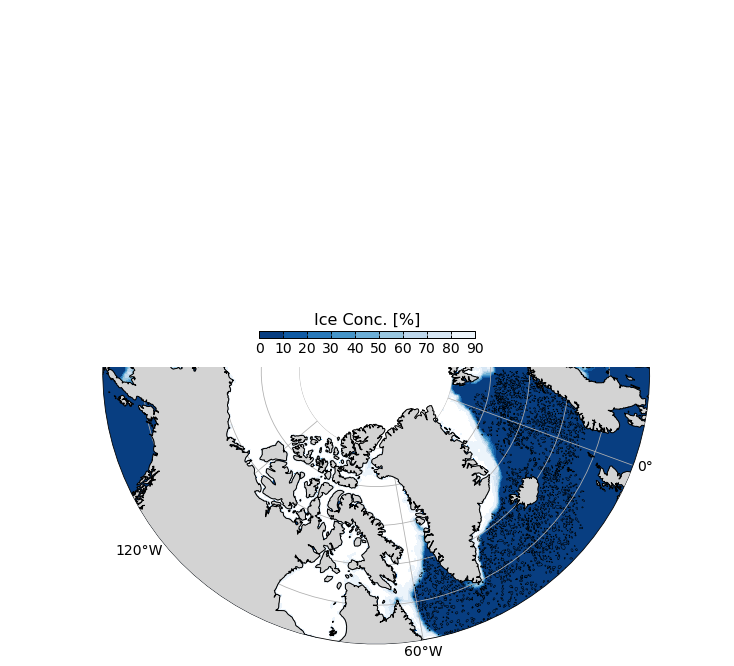

from 27/03/2024 to 16/04/2024


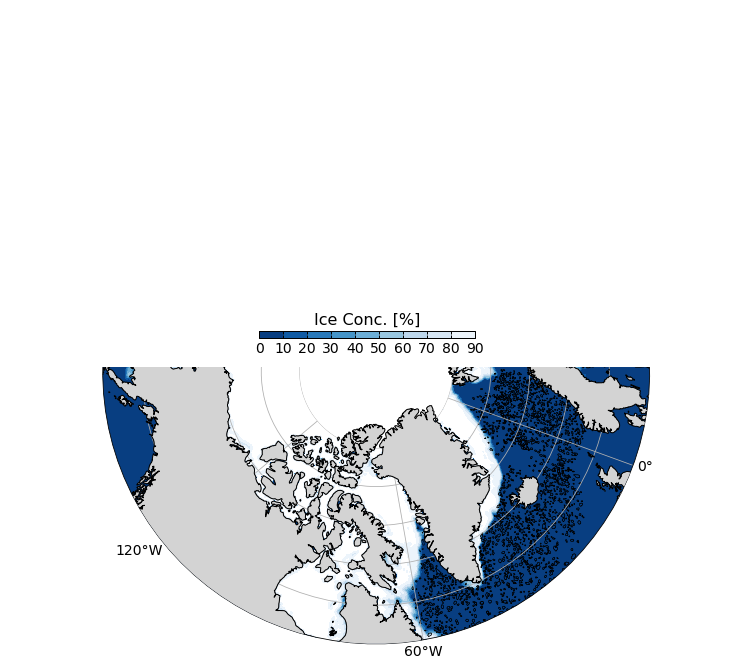

from 17/04/2024 to 07/05/2024


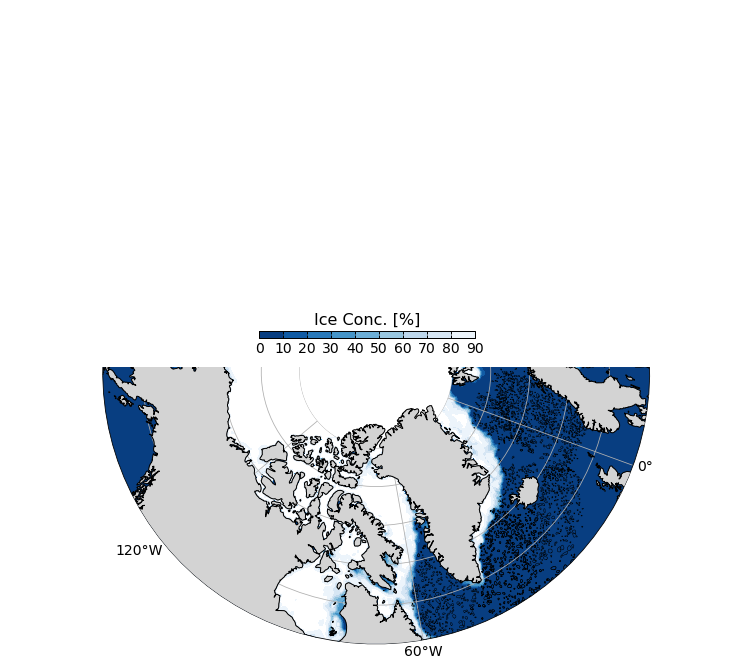

from 08/05/2024 to 28/05/2024


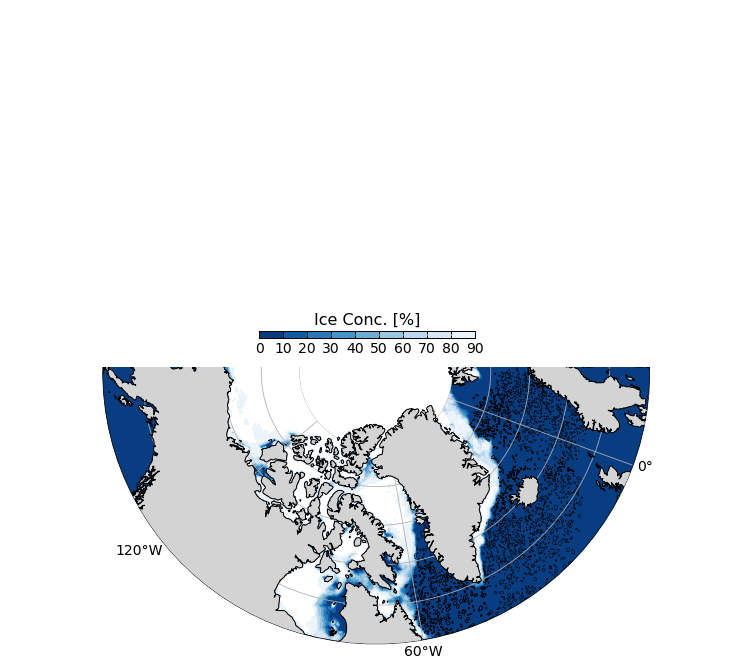

from 29/05/2024 to 18/06/2024


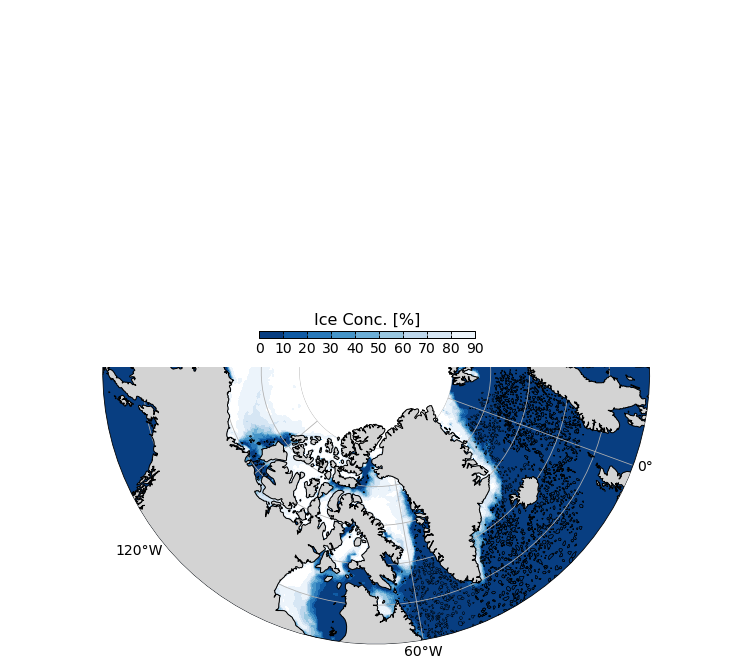

from 19/06/2024 to 09/07/2024


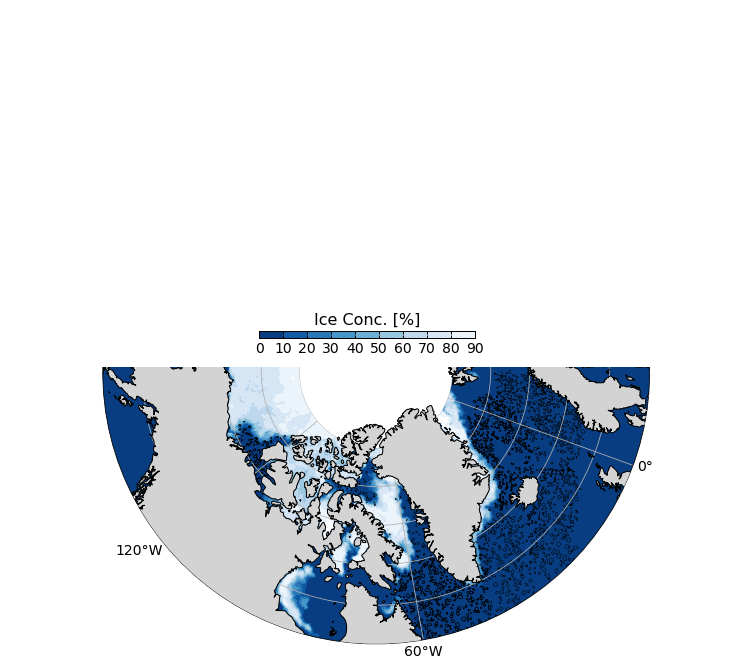

from 10/07/2024 to 30/07/2024


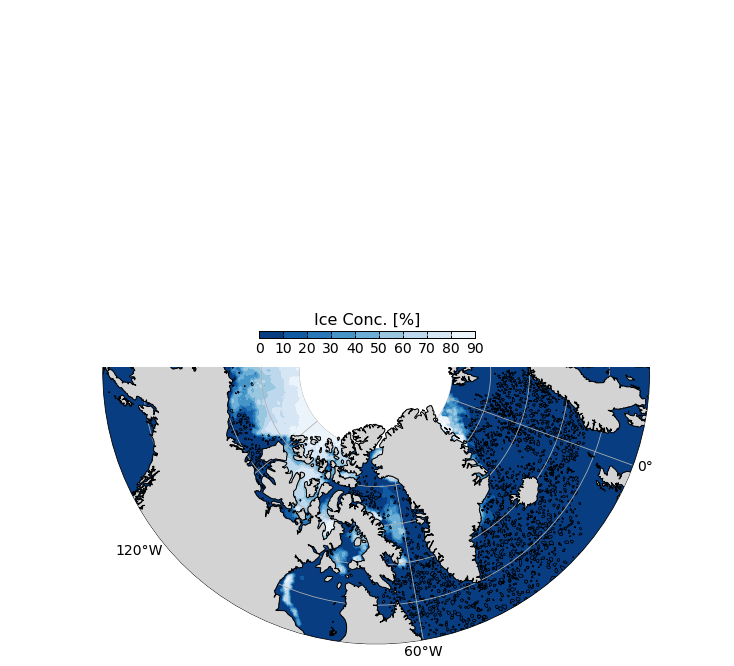

from 31/07/2024 to 20/08/2024


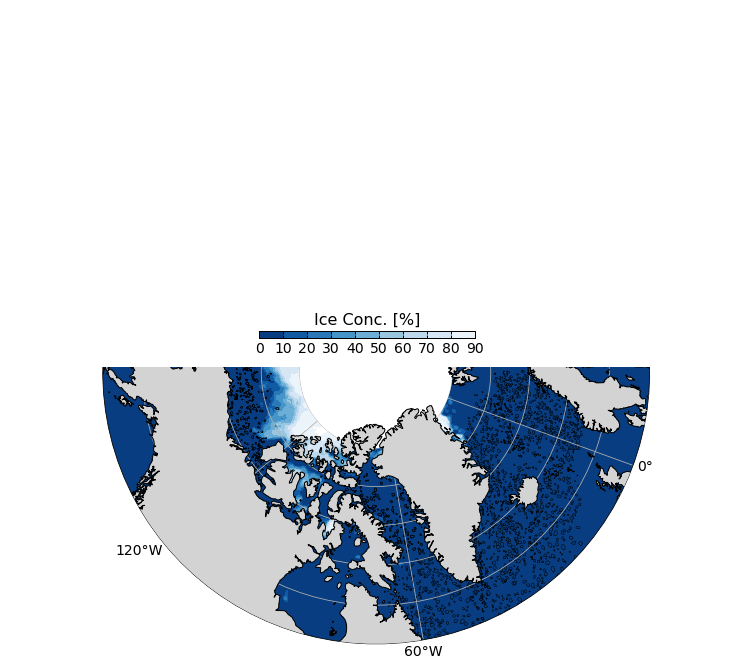

from 20/08/2024 to 10/09/2024


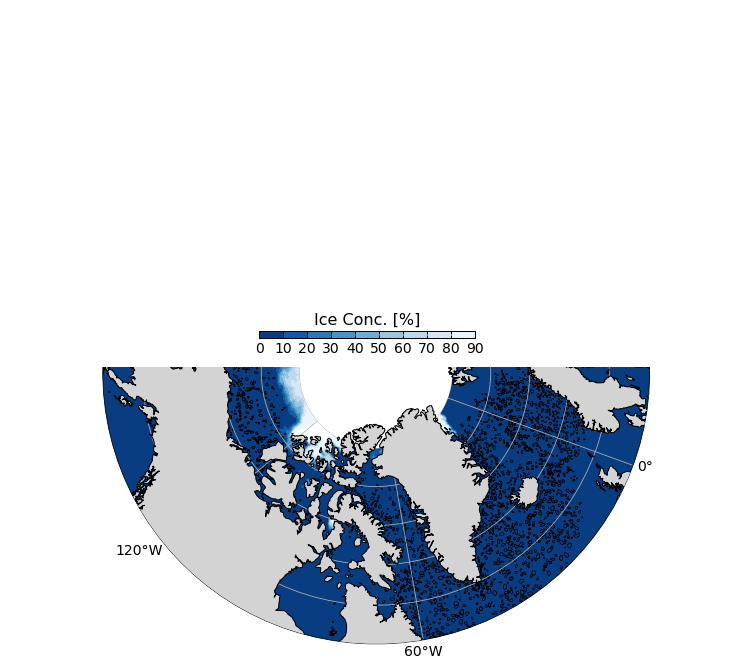

from 10/09/2024 to 30/09/2024


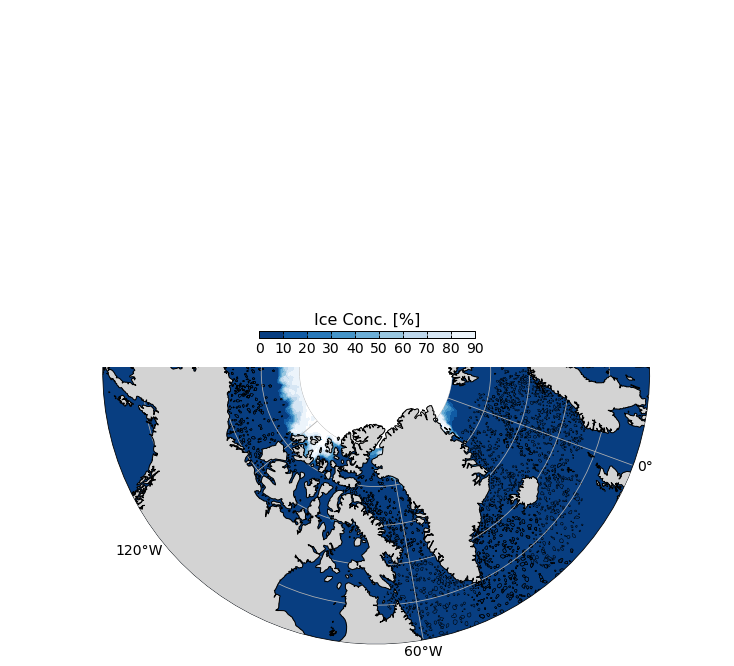

from 01/10/2024 to 21/10/2024


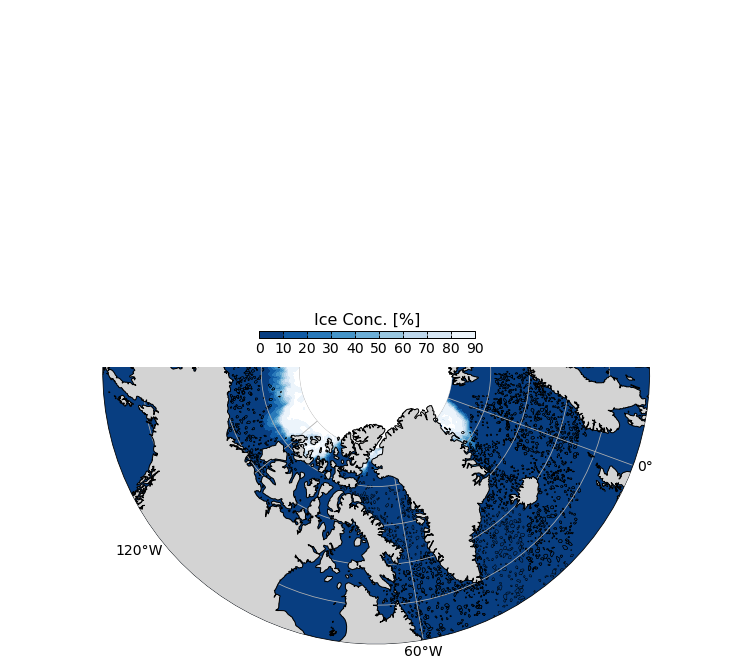

from 22/10/2024 to 11/11/2024


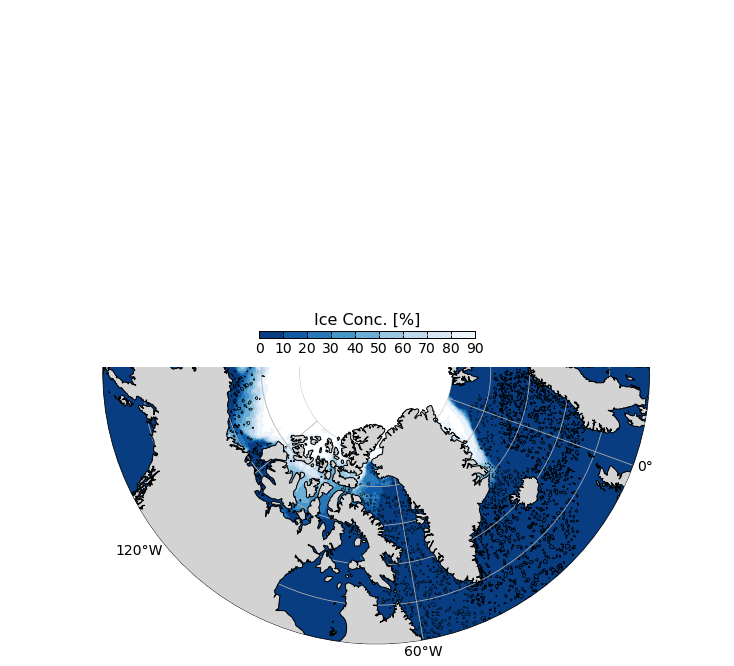

from 12/11/2024 to 02/12/2024


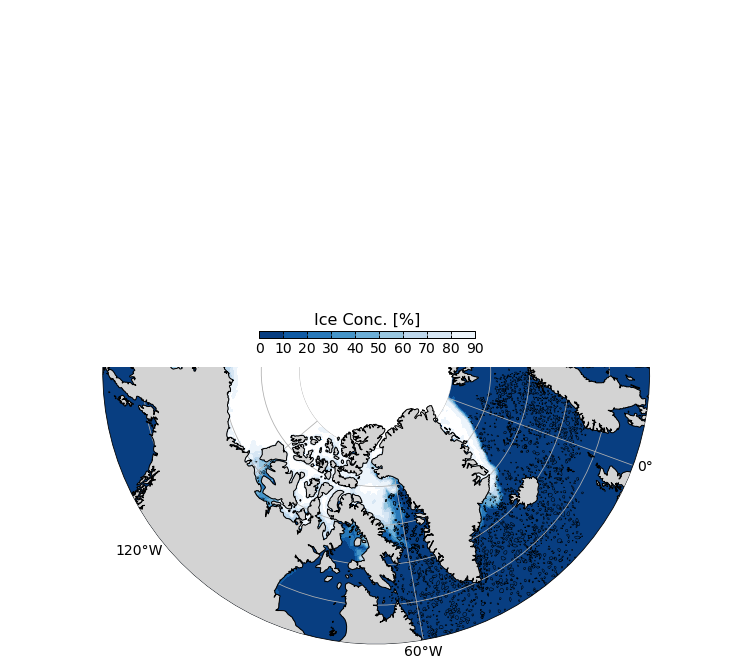

from 03/12/2024 to 23/12/2024


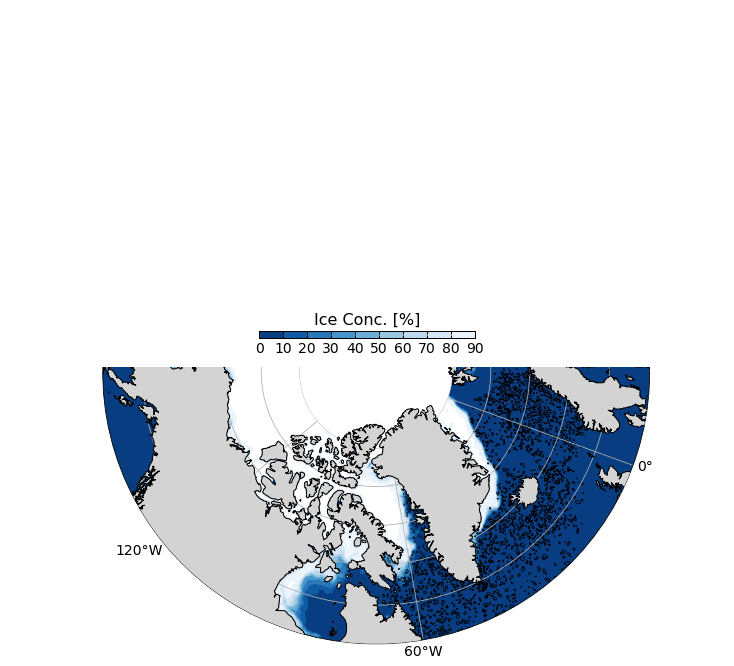

from 24/12/2024 to 10/01/2025


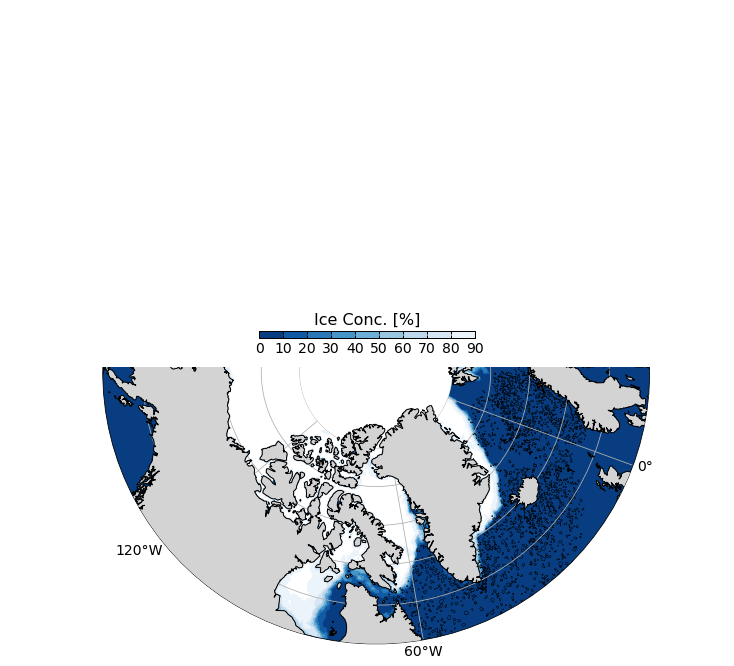

from 13/01/2025 to 02/02/2025


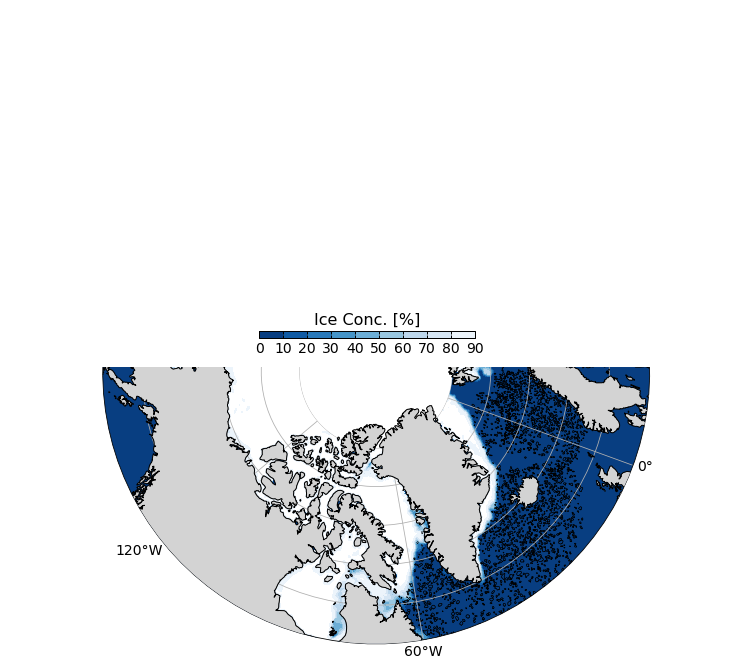

from 03/02/2025 to 24/02/2025


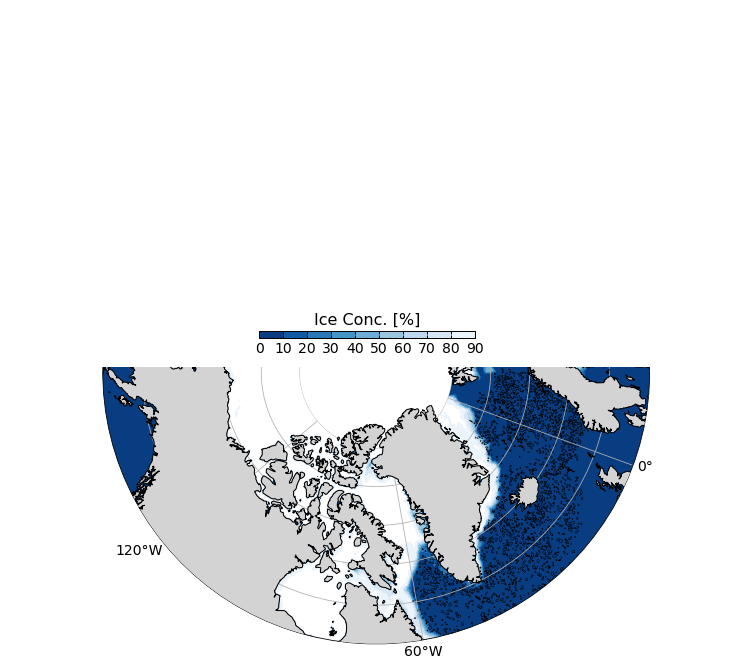

from 24/02/2025 to 16/03/2025


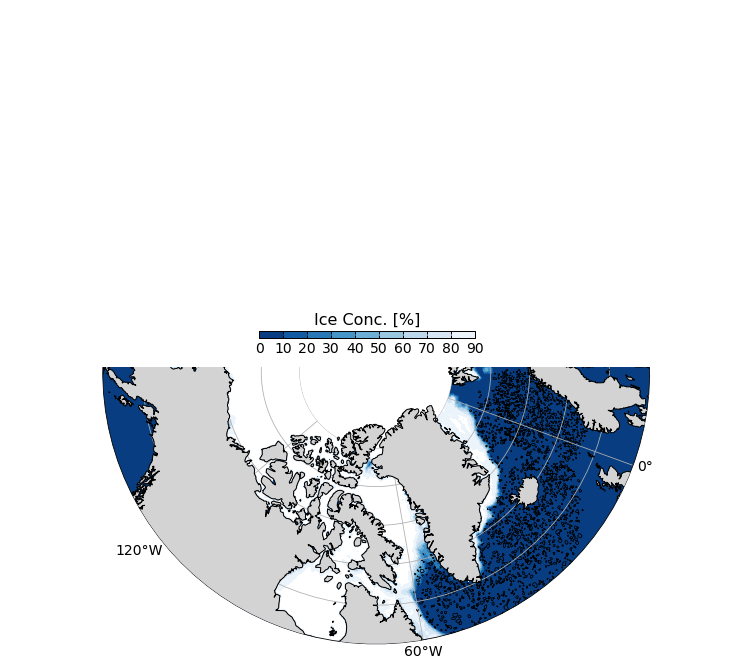

from 17/03/2025 to 06/04/2025


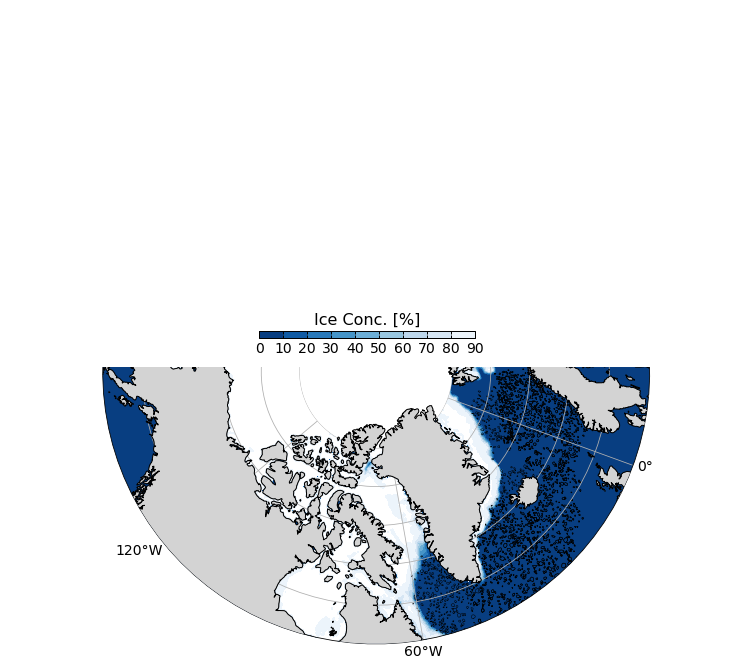

from 07/04/2025 to 27/04/2025


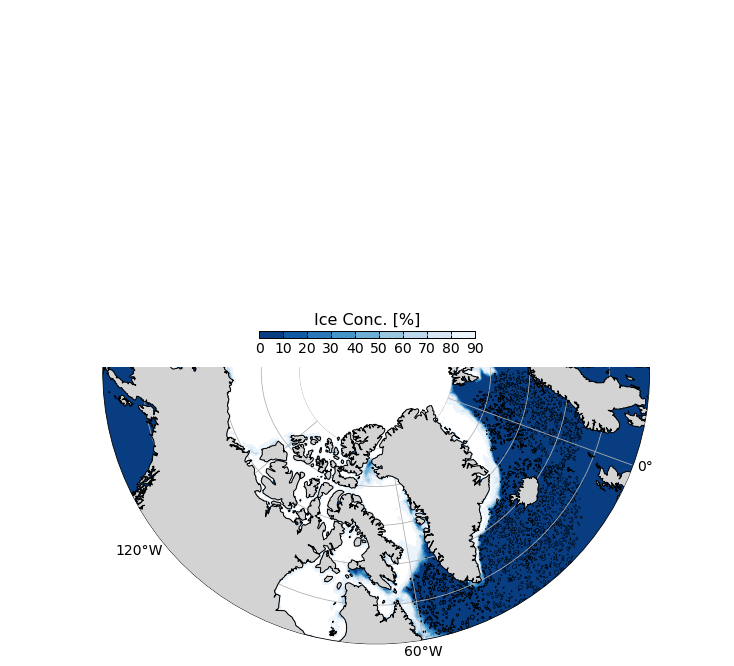

from 28/04/2025 to 01/05/2025


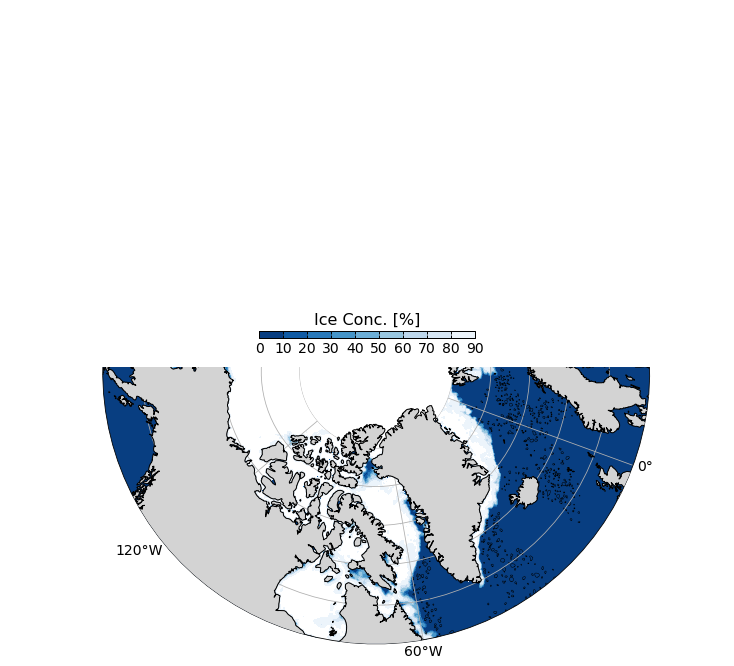

from 19/05/2025 to 08/06/2025


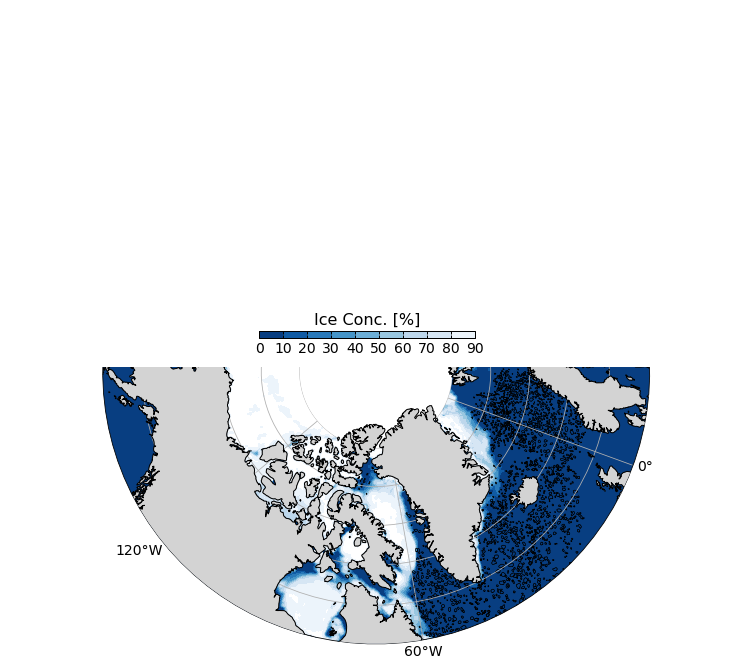

from 08/06/2025 to 29/06/2025


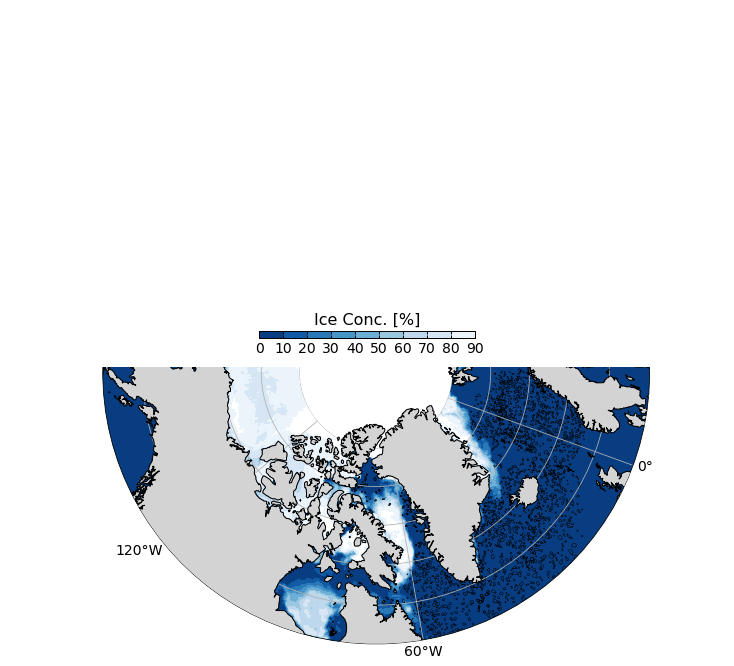

from 29/06/2025 to 20/07/2025


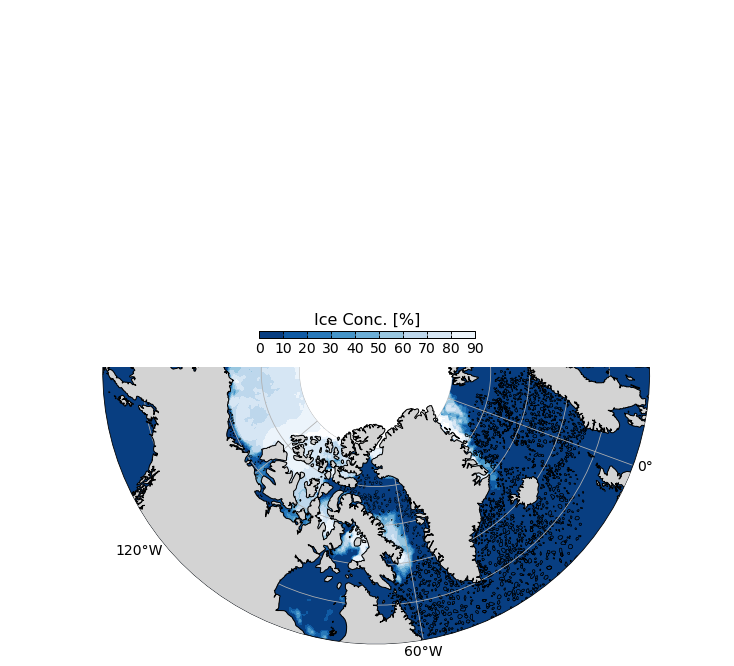

from 20/07/2025 to 09/08/2025


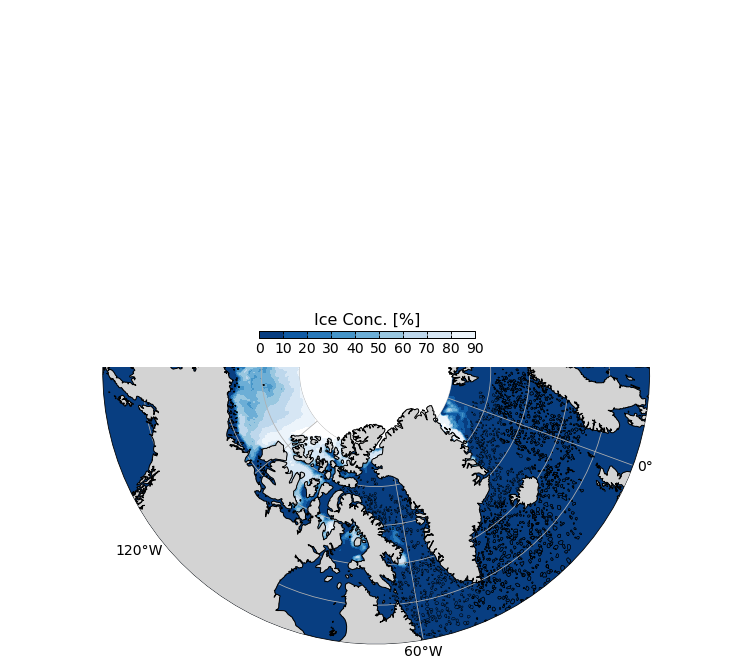

from 11/08/2025 to 30/08/2025


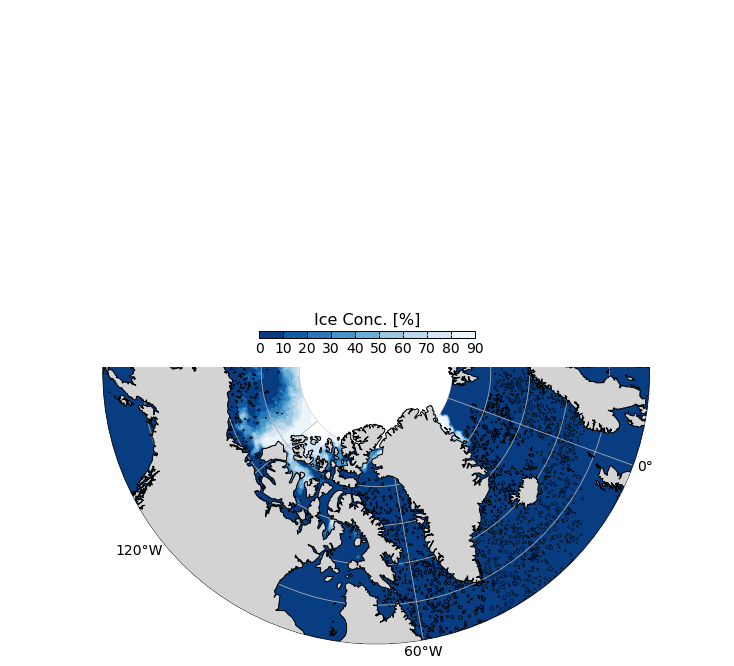

from 31/08/2025 to 20/09/2025


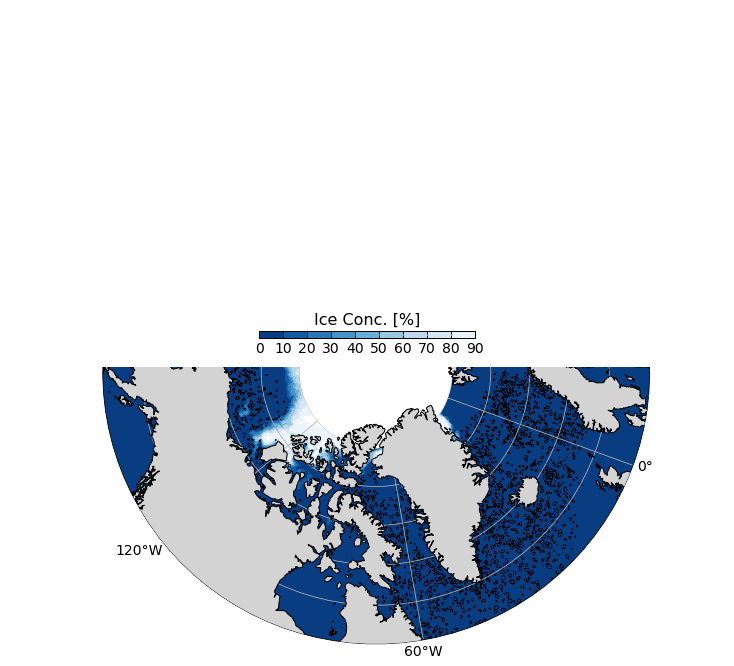

from 21/09/2025 to 11/10/2025


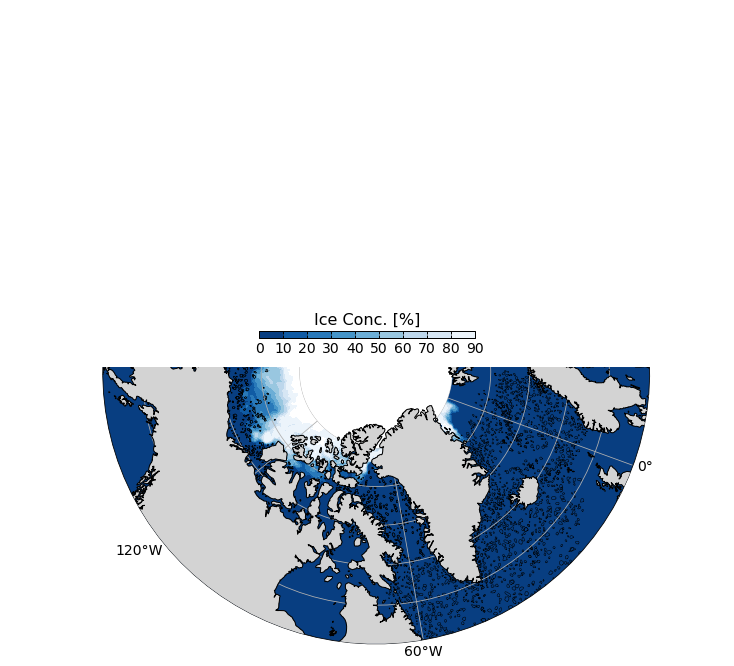

from 12/10/2025 to 01/11/2025


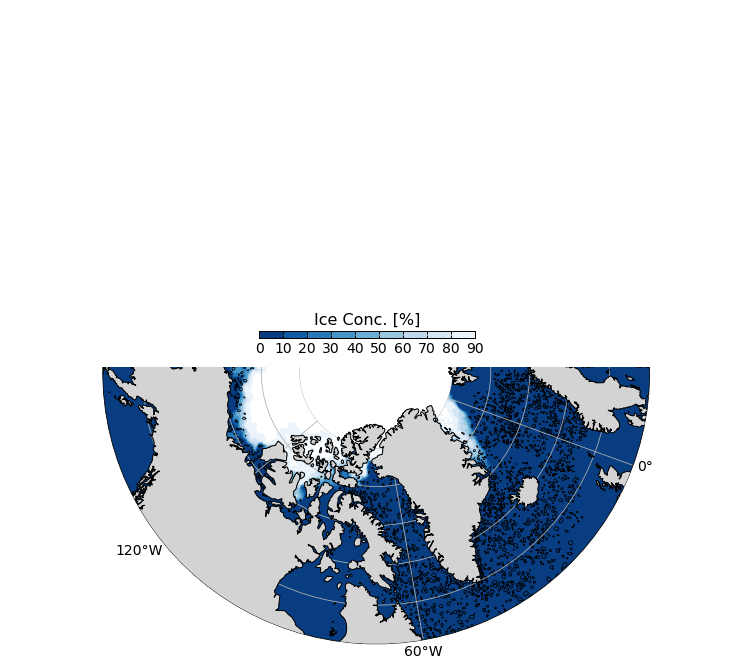

from 02/11/2025 to 22/11/2025


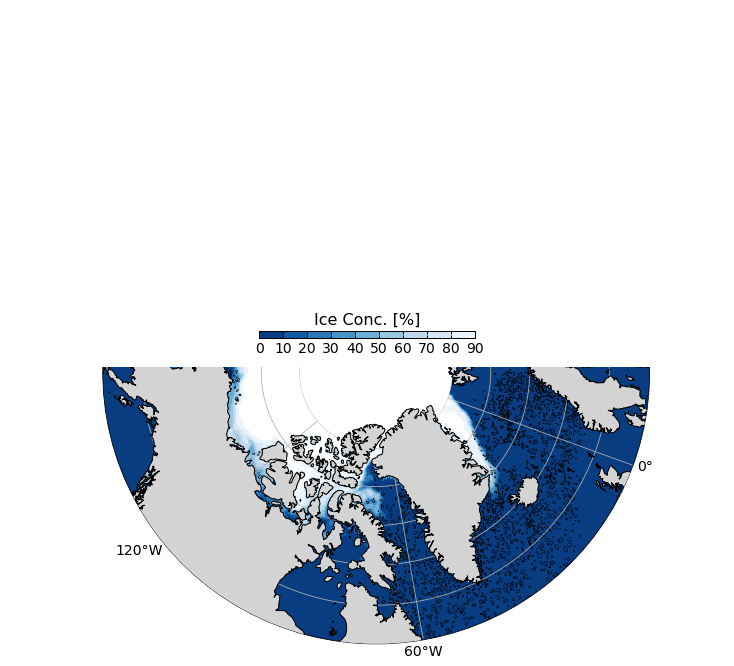

In [84]:
for icycle in range(len(cycles_avail)):
    extraction_name=extraction_names[0]
    take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]
    minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
    maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

    print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))



    fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10))

    nplot=10


    #plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topo[::nplot,::nplot],
    #            np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
    #            transform=ccrs.PlateCarree())

    '''
    plt.contour(lon_ice,lat_ice,ice_mean_per_cycle[icycle],[0,15,80,100],
                 colors='k',linestyle='-',linewidths=1,
                 transform=ccrs.PlateCarree())
    plt.contourf(lon_ice,lat_ice,ice_mean_per_cycle[icycle],[0,15,80,100],
                 colors='none',
                 hatches=['','//','////',],
                 transform=ccrs.PlateCarree())
    '''
    #plt.colorbar()

    
    #plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #         colors='k',linestyle='-',linewidths=0.5,
    #         transform=ccrs.PlateCarree())
    #plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #             colors='none',
    #             hatches=['','//',],
    #             transform=ccrs.PlateCarree())

    toplot=np.where(n_cycles_ice_covered==0,0,ice_mean_per_cycle[icycle])
    pc=plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,100,10),cmap='Blues_r',
                 transform=ccrs.PlateCarree())
    #plt.colorbar()


    for extraction_name in extraction_names[:]:

        take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]

        #minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
        #meanjuld=np.nanmean(juld_all_allareas[extraction_name][take_cycle]) #the middle of the cycle
        #maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

        #print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

        for ieddy in range(len(lon_all_allareas[extraction_name])):
            
            if take_cycle[ieddy]==False:continue

            #if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
            #    continue

            
            if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue
            


            #if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
            #elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'  
            thiscol='k' 

            plt.plot(contour_lon_all_allareas[extraction_name][ieddy]-360,
                        contour_lat_all_allareas[extraction_name][ieddy],
                        '-',c=thiscol,lw=0.5,
                        transform=ccrs.PlateCarree())


            #plt.plot(lon_all_allareas[extraction_name][ieddy]-360,
            #         lat_all_allareas[extraction_name][ieddy],
            #         '.',c=thiscol,
            #          transform=ccrs.PlateCarree())



    '''
    cbar_ax         = fig.add_axes( [0.35,0.85,0.13,0.015] )
    cbar            = fig.colorbar( pc , cax=cbar_ax,extend='both',orientation='horizontal',ticks=np.arange(0,25,5))
    #plt.title( r'[]',fontsize=16,x=1 )
    cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.xaxis.set_ticks_position('both')
    cbar.outline.set_linewidth(1) 
    plt.subplots_adjust(wspace=0.05) '''

    #for izone in range(len(pt_poly_all)):
    #    plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=1,zorder=10,
    #            transform=ccrs.PlateCarree())

    cut_the_map()

    cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
    cbar            = fig.colorbar( pc , cax=cbar_ax,extend='both',orientation='horizontal')#,ticks=np.arange(0,22,5))
    plt.title( r'Ice Conc. [%]',fontsize=16,x=0.5 )
    cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.xaxis.set_ticks_position('both')
    cbar.outline.set_linewidth(1) 
    cbar_ax.set_zorder(1e6)




    plt.subplots_adjust(wspace=0.05) 
    
    plt.savefig(path_figs+str(icycle).zfill(3)+'allwice.png',dpi=300)
    plt.show()

### Do zooms :

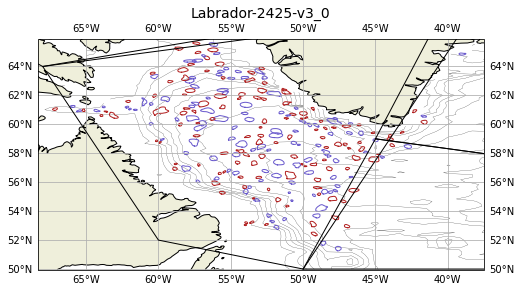

In [220]:
# Check the Norwegian at the coast : strange
extraction_name=extraction_names[0]

icycle=0

take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]


fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([np.nanmin(lon_all_allareas[extraction_name]), 
               np.nanmax(lon_all_allareas[extraction_name]), 
               np.nanmin(lat_all_allareas[extraction_name]),
               np.nanmax(lat_all_allareas[extraction_name])], 
              crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.COASTLINE)

plt.title(extraction_name,fontsize=14)

plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topo[::nplot,::nplot],
                np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
                transform=ccrs.PlateCarree())


#minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
#meanjuld=np.nanmean(juld_all_allareas[extraction_name][take_cycle]) #the middle of the cycle
#maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

#print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

for ieddy in range(len(lon_all_allareas[extraction_name])):

    if take_cycle[ieddy]==False:continue

    if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
        
        continue

    if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue



    if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
    elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'    

    plt.plot(contour_lon_all_allareas[extraction_name][ieddy],
                contour_lat_all_allareas[extraction_name][ieddy],
                '-',c=thiscol,lw=1,
                transform=ccrs.PlateCarree())


for izone in range(len(pt_poly_all)):
    plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=1,zorder=10,
      transform=ccrs.PlateCarree())
    
    
ax.gridlines(draw_labels=True, rotate_labels=False,
                      x_inline=False, y_inline=False, linestyle='-', alpha=1)
    
    
# --- Set font size for the labels ---
#gl.xlabel_style = {'size': 14}   # longitude labels
#gl.ylabel_style = {'size': 14}   # latitude labels


plt.show()

# Now compute the hotspots and the stats !!

In [221]:
Ro_all_allareas={}
for extraction_name in extraction_names[:]:        
    #compute Ro
    omeg=7.2921e-5
    f_all_ok=2*omeg*np.sin(np.deg2rad(lat_all_allareas[extraction_name]))
    Ro_all_ok=v_all_allareas[extraction_name]/f_all_ok/(r_all_allareas[extraction_name]*1e3)
    Ro_all_allareas[extraction_name]=Ro_all_ok

In [244]:
def count_boxes(boxs_lon,boxs_lat,ALL_LON_drifters,ALL_LAT_drifters):

    boxs_drifters_nb,tmp=np.meshgrid(boxs_lon,boxs_lat)
    boxs_drifters_nb[:,:]=0
    for ilon in range (len(boxs_lon)-1):
        for ilat in range (len(boxs_lat)-1):
            #test for coloc floats
            test1=ALL_LON_drifters>boxs_lon[ilon]
            test2=ALL_LON_drifters<boxs_lon[ilon+1]
            test3=ALL_LAT_drifters>boxs_lat[ilat]
            test4=ALL_LAT_drifters<boxs_lat[ilat+1]
            choice=test1&test2&test3&test4
            LON_inbox=ALL_LON_drifters[choice]
            LAT_inbox=ALL_LAT_drifters[choice]
            boxs_drifters_nb[ilat,ilon]=len(LON_inbox)
            #print(np.nanmax(ALL_LAT_drifters))
    return boxs_drifters_nb


def stat_boxes(boxs_lon,boxs_lat,ALL_LON_drifters,ALL_LAT_drifters,VAR):

    avg,tmp=np.meshgrid(boxs_lon,boxs_lat)
    avg[:,:]=0
    std,tmp=np.meshgrid(boxs_lon,boxs_lat)
    std[:,:]=0
    med,tmp=np.meshgrid(boxs_lon,boxs_lat)
    med[:,:]=0
    for ilon in range (len(boxs_lon)-1):
        for ilat in range (len(boxs_lat)-1):
            #test for coloc floats
            test1=ALL_LON_drifters>boxs_lon[ilon]
            test2=ALL_LON_drifters<boxs_lon[ilon+1]
            test3=ALL_LAT_drifters>boxs_lat[ilat]
            test4=ALL_LAT_drifters<boxs_lat[ilat+1]
            choice=test1&test2&test3&test4

            
            #try:
            avg[ilat,ilon]=np.nanmean(np.array(VAR[choice], copy=True))
            std[ilat,ilon]=np.nanstd(np.array(VAR[choice], copy=True))
            med[ilat,ilon]=np.nanmedian(np.array(VAR[choice], copy=True))
            #except:
            #    pass
                
                
    return avg,std,med

In [223]:
dbox=1

boxs_stats={}

for extraction_name in extraction_names:


    take1=ice_all_allareas[extraction_name]<max_ice_conc
    take2=depth_all_allareas[extraction_name]<min_depth 
    take3=~np.isnan(depth_all_allareas[extraction_name])

    take=take1&take2&take3



    boxs_stats[extraction_name]={}

    
    lon1,lon2=np.nanmin(lon_all_allareas[extraction_name]),np.nanmax(lon_all_allareas[extraction_name])
    lat1,lat2=np.nanmin(lat_all_allareas[extraction_name]),np.nanmax(lat_all_allareas[extraction_name])
    boxs_lon=np.arange(lon1,lon2+dbox,dbox)
    boxs_lat=np.arange(lat1,lat2+dbox,dbox)
    boxs_llon,boxs_llat=np.meshgrid(boxs_lon,boxs_lat)

    boxs_stats[extraction_name]['boxs_llon'],boxs_stats[extraction_name]['boxs_llat']=\
        np.copy(boxs_llon),np.copy(boxs_llat)



    boxs_stats[extraction_name]['count']={}
    pols=[-1,1]
    for pol in pols:
        
        tmp_all=[]
        for icycle in range(len(cycles_avail)):

            take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]
        
        
            tmp=count_boxes(boxs_lon,boxs_lat,
                                 lon_all_allareas[extraction_name][take&take_cycle][pol_all_allareas[extraction_name][take&take_cycle]==pol],
                                 lat_all_allareas[extraction_name][take&take_cycle][pol_all_allareas[extraction_name][take&take_cycle]==pol])
        
            tmp_all.append(tmp)
            
        boxs_stats[extraction_name]['count'][str(pol)]=np.array(tmp_all)   

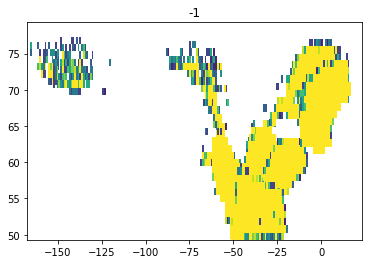

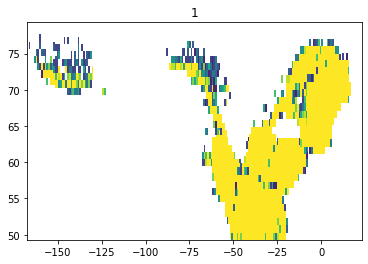

In [224]:


for pol in pols:
    #plt.title('total '+str(pol)+'= {}'.format(np.sum(boxs_stats[extraction_name]['count'][str(pol)])))
    plt.title(pol)
    for extraction_name in extraction_names: 
        
        tmpplot=np.nansum(boxs_stats[extraction_name]['count'][str(pol)],axis=0)
        plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],boxs_stats[extraction_name]['boxs_llat'],
                       np.where(tmpplot==0,np.nan,tmpplot),
                       vmin=0,vmax=10)

    
    #plt.colorbar()
    plt.show()

In [245]:
varss=['radius','Ro','v','a']

for extraction_name in extraction_names:
    
    take1=ice_all_allareas[extraction_name]<max_ice_conc
    take2=depth_all_allareas[extraction_name]<min_depth 
    take3=~np.isnan(depth_all_allareas[extraction_name])

    take=take1&take2&take3

    for var in varss:
        print(var)
        boxs_stats[extraction_name][var]={}
        for pol in pols:
            polkey=str(pol)
            print(polkey)
            boxs_stats[extraction_name][var][polkey]={}

            if var=='radius':
                boxs_stats[extraction_name][var][polkey]['avg'],boxs_stats[extraction_name][var][polkey]['std'],boxs_stats[extraction_name][var][polkey]['med']=\
                                       stat_boxes(boxs_stats[extraction_name]['boxs_llon'][0],boxs_stats[extraction_name]['boxs_llat'][:,0],
                                       lon_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       lat_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       r_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol])

            if var=='Ro':
                boxs_stats[extraction_name][var][polkey]['avg'],boxs_stats[extraction_name][var][polkey]['std'],boxs_stats[extraction_name][var][polkey]['med']=\
                                       stat_boxes(boxs_stats[extraction_name]['boxs_llon'][0],boxs_stats[extraction_name]['boxs_llat'][:,0],
                                       lon_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       lat_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       Ro_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol])
            if var=='v':
                boxs_stats[extraction_name][var][polkey]['avg'],boxs_stats[extraction_name][var][polkey]['std'],boxs_stats[extraction_name][var][polkey]['med']=\
                                       stat_boxes(boxs_stats[extraction_name]['boxs_llon'][0],boxs_stats[extraction_name]['boxs_llat'][:,0],
                                       lon_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       lat_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       v_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol])
            if var=='a':
                boxs_stats[extraction_name][var][polkey]['avg'],boxs_stats[extraction_name][var][polkey]['std'],boxs_stats[extraction_name][var][polkey]['med']=\
                                       stat_boxes(boxs_stats[extraction_name]['boxs_llon'][0],boxs_stats[extraction_name]['boxs_llat'][:,0],
                                       lon_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       lat_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol],\
                                       a_all_allareas[extraction_name][take][pol_all_allareas[extraction_name][take]==pol])


radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1
radius
-1
1
Ro
-1
1
v
-1
1
a
-1
1


-1


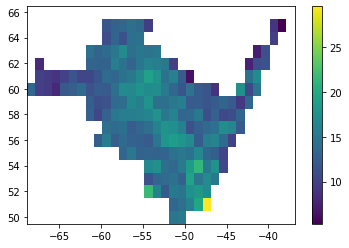

1


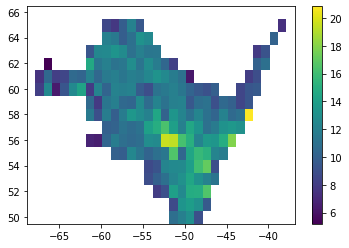

In [226]:
extraction_name=extraction_names[0]

for pol in pols:
    polkey=str(pol)
    print(pol)
    toplot=boxs_stats[extraction_name]['radius'][polkey]['avg']
    toplot=np.where(toplot==0,np.nan,toplot)
    plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],boxs_stats[extraction_name]['boxs_llat'],toplot,shading='nearest')
    plt.colorbar()
    plt.show()

In [227]:
# Compute the average number of cycle each bin is covered by ice

var='ice'


for extraction_name in extraction_names:
    
    boxs_stats[extraction_name][var]={}
    boxs_stats[extraction_name][var]['avg'],boxs_stats[extraction_name][var]['std'],boxs_stats[extraction_name][var]['med']=\
                                       stat_boxes(boxs_stats[extraction_name]['boxs_llon'][0],boxs_stats[extraction_name]['boxs_llat'][:,0],
                                       np.ravel(lon_ice),np.ravel(lat_ice),np.ravel(n_cycles_ice_covered))


# Plot Big map

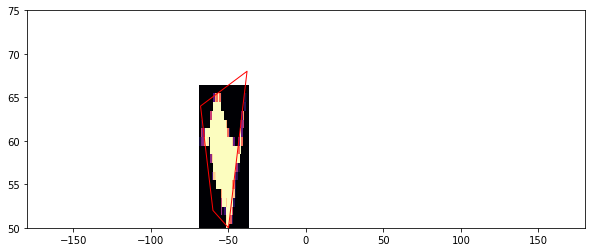

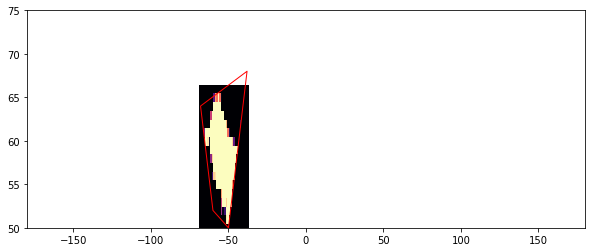

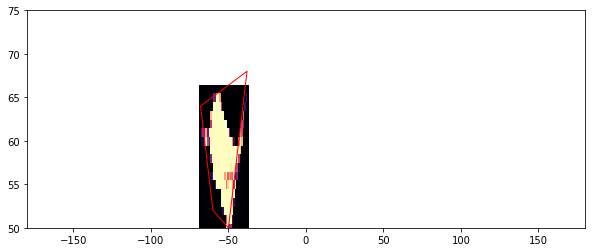

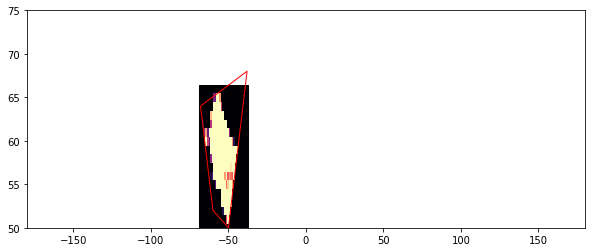

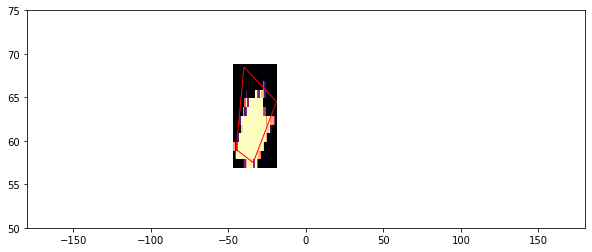

...

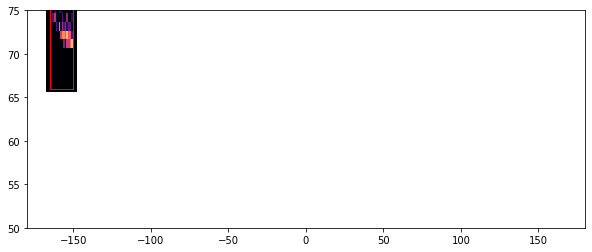

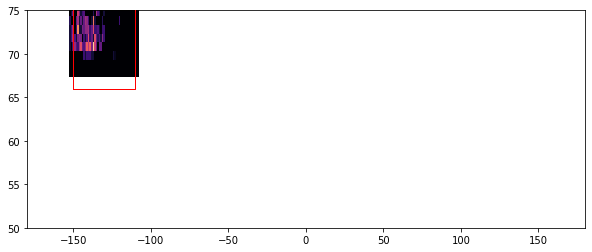

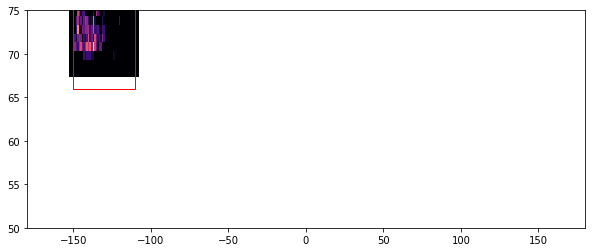

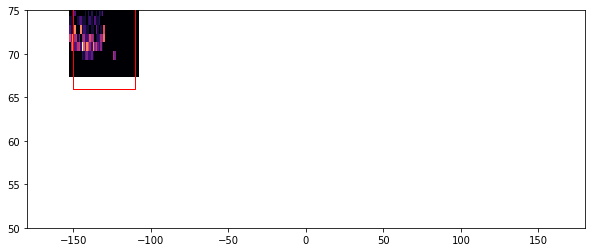

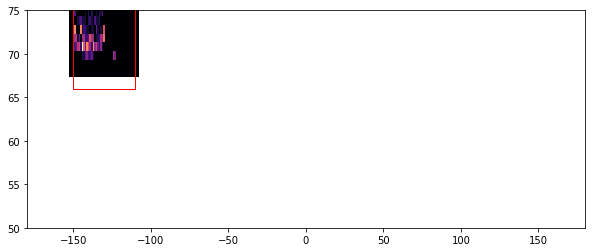

In [229]:
izones_ok={}

izones_ok['Irminger-2425-v3_0']=0
izones_ok['Labrador-2425-v3_0']=1
izones_ok['Greenland-2425-v3_0']=2
izones_ok['Baffin-2425-v3_0']=3
izones_ok['Norwegian-2425-v3_0']=4
izones_ok['Iceland-2425-v3_0']=5
izones_ok['NA-2425-v3_0']=6
izones_ok['Pacific3bis-2425-v3_0']=7
izones_ok['Pacific4-2425-v3_0']=8

for izone in range(len(extraction_names)):
    extraction_name=extraction_names[izone]
    boxs_stats[extraction_name]['count_sum']={}

    for pol in pols:

        

        pt_poly=pt_poly_all[izones_ok[extraction_name]]
        lontmp=boxs_stats[extraction_name]['boxs_llon']
        lattmp=boxs_stats[extraction_name]['boxs_llat']

        tmp=np.copy(np.nansum(boxs_stats[extraction_name]['count'][str(pol)],axis=0)) #the array to correct
        
        
        fig=plt.figure(figsize=(10,4))
        ax=plt.subplot(111)
        
        plt.pcolormesh(lontmp,lattmp,tmp,
                           vmin=0,vmax=20,cmap='magma')
        
        plt.plot(pt_poly[0],pt_poly[1],'-r',markersize=5,lw=1,zorder=10,)
        ax.set_xlim(-180,180)
        ax.set_ylim(50,75)
        plt.show()





        #correct, remove wht's outside the box !

        
        

        #extract only the part of the track within the polygon
        from shapely.geometry import Point, Polygon
        poly = Polygon(np.column_stack((pt_poly[0], pt_poly[1])))
        
        
        for ilo in range(lontmp.shape[1]):
            for ila in range(lontmp.shape[0]):
                test=poly.contains(Point(lontmp[ila,ilo], lattmp[ila,ilo]))
                if test==False:
                    tmp[ila,ilo]=0


        fig=plt.figure(figsize=(10,4))
        ax=plt.subplot(111)
        
        plt.pcolormesh(lontmp,lattmp,tmp,
                           vmin=0,vmax=20,cmap='magma')
        
        plt.plot(pt_poly[0],pt_poly[1],'-r',markersize=5,lw=1,zorder=10,)
        ax.set_xlim(-180,180)
        ax.set_ylim(50,75)
        plt.show()



        boxs_stats[extraction_name]['count_sum'][str(pol)]=np.copy(tmp)
for extraction_name in extraction_names:
    boxs_stats[extraction_name]['count_sum']['both']= np.sum([boxs_stats[extraction_name]['count_sum'][str(i)] for i in [1,-1]],axis=0)



In [230]:
# do an interpolation over the full area

lon1,lon2=-165,20
lat1,lat2=50,80
boxs_lon=np.arange(lon1,lon2+dbox,dbox)
boxs_lat=np.arange(lat1,lat2+dbox/2,dbox/2)
boxs_llon,boxs_llat=np.meshgrid(boxs_lon,boxs_lat)

boxs_stats['all']={}

boxs_stats['all']['count']={}

for pol in [-1,1]:

    
    
    
    
    data_to_i=np.concatenate([np.ravel(np.nansum(boxs_stats[i]['count'][str(pol)],axis=0)) for i in extraction_names])
    mask=~(data_to_i==0)
    
    
    x_to_i=np.concatenate([np.ravel(boxs_stats[i]['boxs_llon']) for i in extraction_names])[mask]
    y_to_i=np.concatenate([np.ravel(boxs_stats[i]['boxs_llat']) for i in extraction_names])[mask]
    data_to_i=data_to_i[mask]
    
    
    boxs_stats['all']['count'][str(pol)]=griddata((x_to_i,y_to_i), data_to_i, (boxs_llon,boxs_llat), method='linear')

    
boxs_stats['all']['count']['both']= np.sum([boxs_stats['all']['count'][str(i)] for i in [1,-1]],axis=0)
    
    
    




In [231]:
lontmp=boxs_llon
lattmp=boxs_llat
whereok=np.full(lontmp.shape,False)

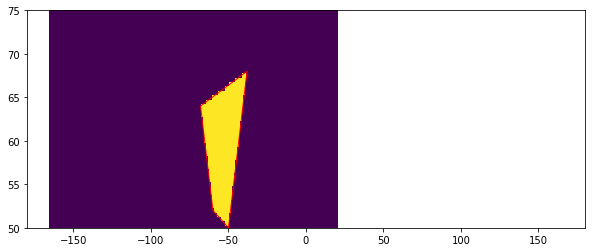

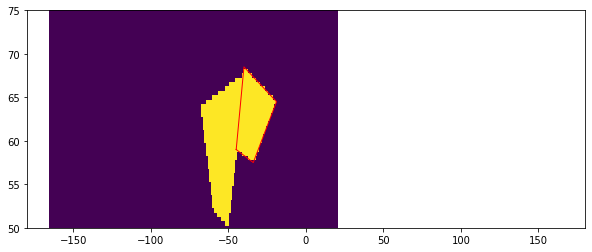

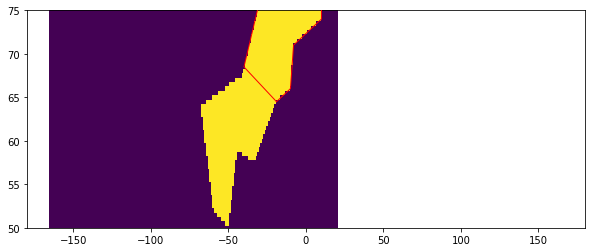

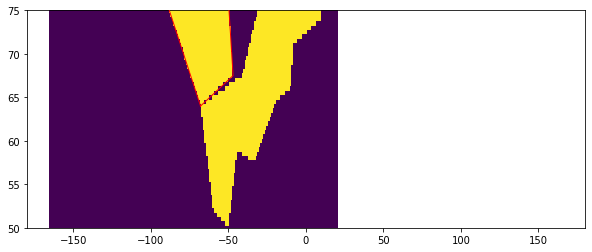

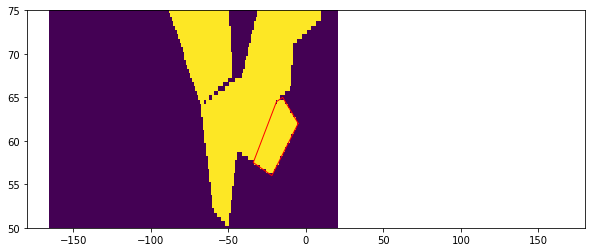

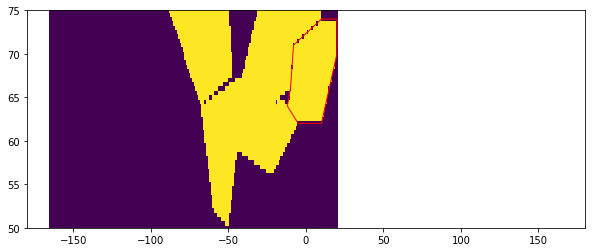

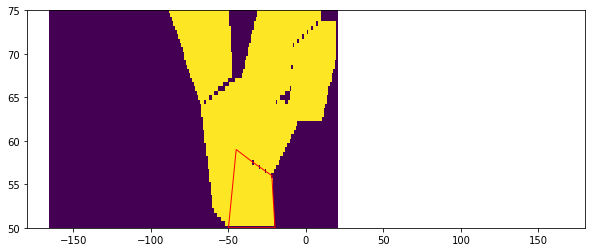

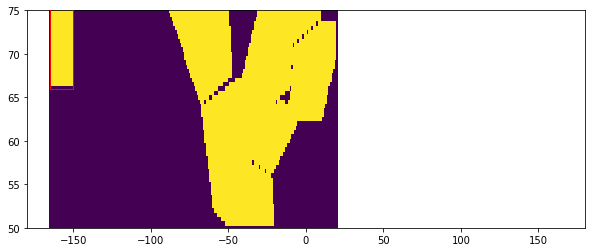

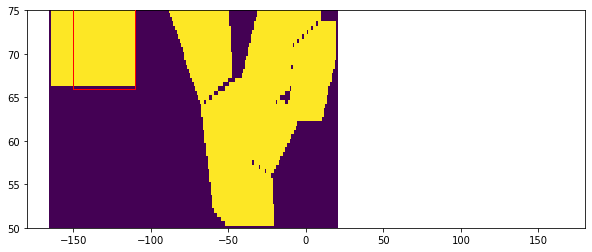

In [232]:
for izone in range(len(extraction_names)):
    extraction_name=extraction_names[izone]
    pt_poly=pt_poly_all[izones_ok[extraction_name]]


        
        

    #extract only the part of the track within the polygon
    from shapely.geometry import Point, Polygon
    poly = Polygon(np.column_stack((pt_poly[0], pt_poly[1])))


    for ilo in range(lontmp.shape[1]):
        for ila in range(lontmp.shape[0]):
            test=poly.contains(Point(lontmp[ila,ilo], lattmp[ila,ilo]))
            if test:
                whereok[ila,ilo]=test


    fig=plt.figure(figsize=(10,4))
    ax=plt.subplot(111)

    plt.pcolormesh(lontmp,lattmp,whereok)

    plt.plot(pt_poly[0],pt_poly[1],'-r',markersize=5,lw=1,zorder=10,)
    ax.set_xlim(-180,180)
    ax.set_ylim(50,75)
    plt.show()


In [233]:
#interpolate the ice on the 'all' domain

boxs_stats['all']['ice']={}



    
    

data_to_i=np.concatenate([np.ravel(boxs_stats[i]['ice']['avg']) for i in extraction_names])
mask=~(data_to_i==0)
x_to_i=np.concatenate([np.ravel(boxs_stats[i]['boxs_llon']) for i in extraction_names])[mask]
y_to_i=np.concatenate([np.ravel(boxs_stats[i]['boxs_llat']) for i in extraction_names])[mask]
data_to_i=data_to_i[mask]


boxs_stats['all']['ice']=griddata((x_to_i,y_to_i), data_to_i, (boxs_llon,boxs_llat), method='linear')

    

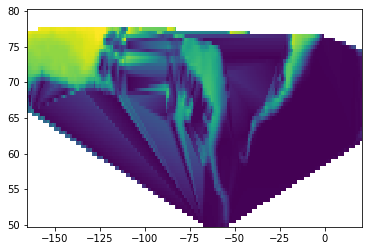

In [234]:
plt.pcolormesh(boxs_llon,boxs_llat,boxs_stats['all']['ice'])

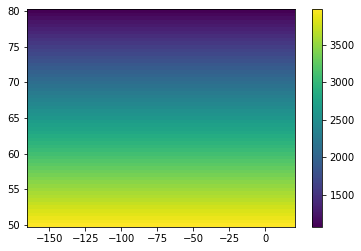

In [235]:

R = 6371.0  # Earth radius in km
dlon = np.radians(np.gradient(boxs_llon, axis=1))
dlat = np.radians(np.gradient(boxs_llat, axis=0))

lat_rad = np.radians(boxs_llat)
dx = R * np.cos(lat_rad) * dlon
dy = R * dlat
area = dx * dy

plt.pcolormesh(boxs_llon,boxs_llat,area)
plt.colorbar()
plt.show()


areas={}

for extraction_name in extraction_names:

    R = 6371.0  # Earth radius in km
    dlon = np.radians(np.gradient(boxs_stats[extraction_name]['boxs_llon'], axis=1))
    dlat = np.radians(np.gradient(boxs_stats[extraction_name]['boxs_llat'], axis=0))
    
    lat_rad = np.radians(boxs_stats[extraction_name]['boxs_llat'])
    dx = R * np.cos(lat_rad) * dlon
    dy = R * dlat
    areas[extraction_name] = dx * dy

In [236]:

    
varss=['radius','Ro','v']
for var in varss:
    boxs_stats['all'][var]={}
    for pol in pols:
        polkey=str(pol)
        print(polkey)
        boxs_stats['all'][var][polkey]={}
        
        
        

        data_to_i=np.concatenate([np.ravel(np.nansum(boxs_stats[i]['count'][str(pol)],axis=0)) for i in extraction_names])
        mask=~(data_to_i==0)

        
        data_to_i=np.concatenate([np.ravel(boxs_stats[i][var][str(pol)]['avg']) for i in extraction_names])
        #just for the mask !!
        
        x_to_i=np.concatenate([np.ravel(boxs_stats[i]['boxs_llon']) for i in extraction_names])[mask]
        y_to_i=np.concatenate([np.ravel(boxs_stats[i]['boxs_llat']) for i in extraction_names])[mask]        
        data_to_i=data_to_i[mask]
        
        
        
        boxs_stats['all'][var][str(pol)]['avg']=griddata((x_to_i,y_to_i), data_to_i, (boxs_llon,boxs_llat), method='linear')


-1


KeyError: 'radius'

In [237]:
#plt.figure(figsize=(10,10))
#plt.scatter(x_to_i,y_to_i,c=data_to_i,s=15)

### Number of eddies

eddy density is number of eddies in 1°x1° per cycle per km2

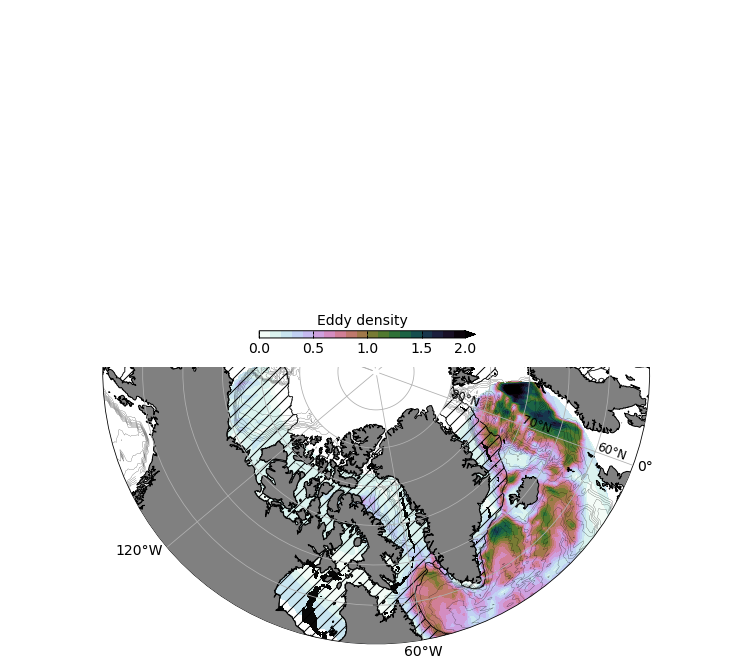

In [238]:
fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10))



nplot=1
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topo[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#

toplot=np.where(n_cycles_ice_covered<18,np.nan,n_cycles_ice_covered)
plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,19,1),cmap='binary',
             transform=ccrs.PlateCarree()) #en noir tt le temps couvert de glace


plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
             colors='k',linestyle='-',linewidths=0.5,
             transform=ccrs.PlateCarree())
plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
             colors='none',
             hatches=['','//',],
             transform=ccrs.PlateCarree()) #en hachuré la SIZ

fact=1e3
toplot=boxs_stats['all']['count']['both']/len(cycles_avail)/area*fact
pc=plt.contourf(boxs_llon,boxs_llat,toplot,np.arange(0,2,0.1),cmap='cubehelix_r',#'afmhot_r',
             transform=ccrs.PlateCarree(),zorder=0,extend='max')#,norm = matplotlib.colors.LogNorm(0.0001,1))




cut_the_map()

cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='both',orientation='horizontal',ticks=np.arange(0,2.5,0.5))
plt.title( r'Eddy density',fontsize=14,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
cbar_ax.set_zorder(1e6)




plt.subplots_adjust(wspace=0.05) 

#plt.savefig(path_figs+str(icycle).zfill(3)+'allwice.png',dpi=300)
plt.show()

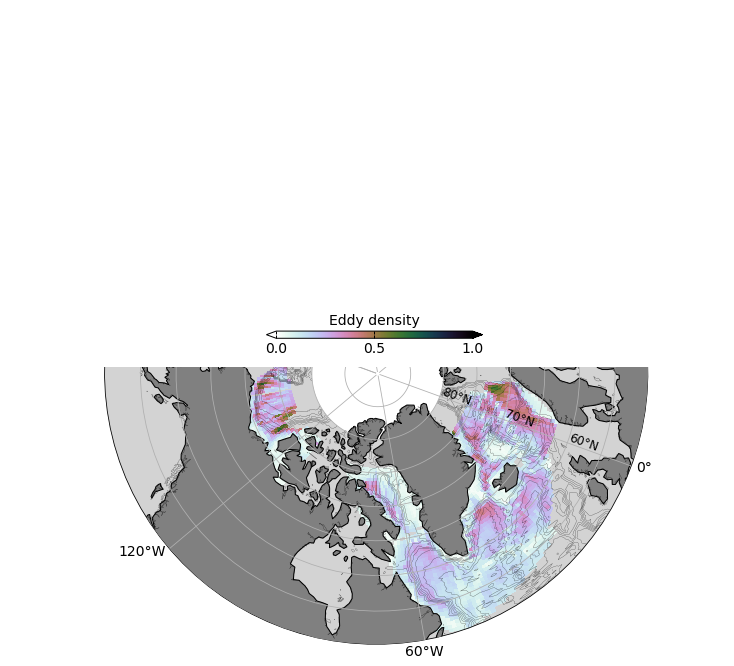

In [239]:
fig,ax=make_curved_map_north(lat_min=50,central_longitude=-70,figsize=(10, 10),facecol='lightgray')



nplot=1
topotoplot=np.where(lattopo>77,np.nan,topo)
topotoplot=np.where((lontopo<-110)&(lattopo<65),np.nan,topo)
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topotoplot[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#

#toplot=np.where(n_cycles_ice_covered<18,np.nan,n_cycles_ice_covered)
#plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,19,1),cmap='binary',
#             transform=ccrs.PlateCarree()) #en noir tt le temps couvert de glace


#plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
#             colors='k',linestyle='-',linewidths=0.5,
#             transform=ccrs.PlateCarree())
#plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
#             colors='none',
#             hatches=['','//',],
#             transform=ccrs.PlateCarree()) #en hachuré la SIZ

fact=1e3
toplot=boxs_stats['all']['count']['both']/len(cycles_avail)/area*fact
#pc=plt.contourf(boxs_llon,boxs_llat,toplot,np.arange(0,2,0.1),cmap='cubehelix_r',#'afmhot_r',
#             transform=ccrs.PlateCarree(),zorder=0,extend='max')#,norm = matplotlib.colors.LogNorm(0.0001,1))

fact_ice=len(cycles_avail)/(len(cycles_avail)-boxs_stats['all']['ice']) #1 if never covered by ice, increases when ice :
fact_ice=np.where(fact_ice>15,np.nan,fact_ice)
toplot=boxs_stats['all']['count']['both']/len(cycles_avail)/area*fact_ice
toplot=np.where(toplot==0,np.nan,toplot)
toplot=toplot*fact
toplot=toplot/np.nanmax(toplot)/1.5
toplot=np.where(whereok,toplot,np.nan)

#pc=plt.contourf(boxs_llon,boxs_llat,toplot,np.arange(0,1.1,0.1),cmap='cubehelix_r',#'afmhot_r',
#             transform=ccrs.PlateCarree(),zorder=0,extend='max')#,norm = matplotlib.colors.LogNorm(0.0001,1))
pc=plt.pcolormesh(boxs_llon,boxs_llat,toplot,vmin=0,vmax=1,cmap='cubehelix_r',#'afmhot_r',
             transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))



cut_the_map()

cbar_ax         = fig.add_axes( [0.36,0.55,0.3,0.01] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='both',orientation='horizontal',ticks=np.arange(0,2.5,0.5))
plt.title( r'Eddy density',fontsize=14,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
cbar_ax.set_zorder(1e6)




plt.subplots_adjust(wspace=0.05) 

plt.savefig('hotspots_north_fact_ice-v3-2425.png',dpi=300)
plt.show()

from 08/05/2024 to 28/05/2024


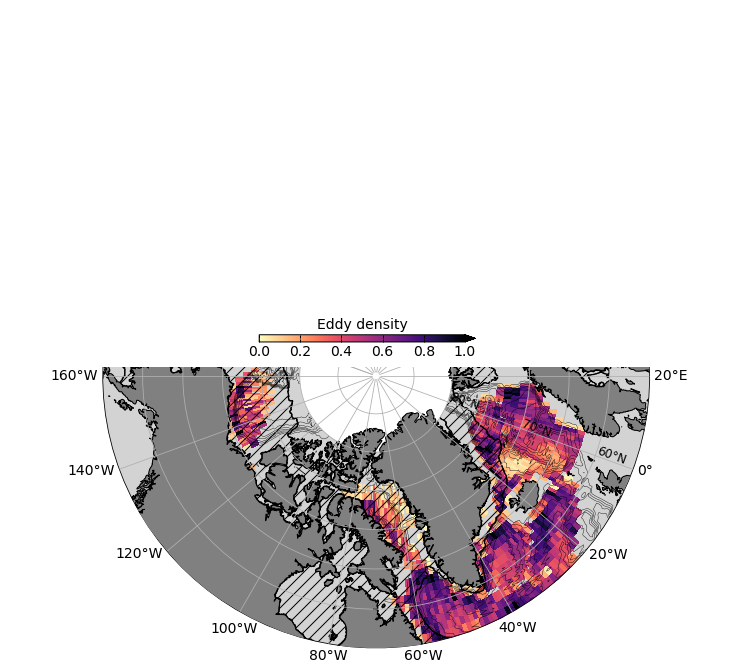

In [282]:
# one version with detection during a cycle

icycle=9
extraction_name=extraction_names[0]
take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]
minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='lightgray')



nplot=1
topotoplot=np.where(lattopo>77,np.nan,topo)
topotoplot=np.where((lontopo<-110)&(lattopo<65),np.nan,topo)
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topotoplot[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.4,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#



#plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
#             colors='w',linestyle='-',linewidths=1,
#             transform=ccrs.PlateCarree())


plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
             colors='k',linestyle='-',linewidths=1,
             transform=ccrs.PlateCarree())
plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
             colors='none',
             hatches=['','//',],
             transform=ccrs.PlateCarree()) #en hachuré la SIZ


fact=1e3

for extraction_name in extraction_names[:]:
    
    #the eddy density
    fact_ice=len(cycles_avail)/(len(cycles_avail)-boxs_stats[extraction_name]['ice']['avg']) #1 if never covered by ice, increases when ice :
    fact_ice=np.where(fact_ice>10,np.nan,fact_ice)
    toplot=boxs_stats[extraction_name]['count_sum']['both']/areas[extraction_name]*fact_ice
    toplot=np.where(toplot==0,np.nan,toplot)
    toplot=toplot*fact
    toplot=toplot/np.nanmax(toplot)/1
    
    #toplot=boxs_stats[extraction_name]['count_sum']['both']/len(cycles_avail)/areas[extraction_name]*fact #v2
    #toplot=np.where(toplot==0,np.nan,toplot)
    
    
    
    pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                boxs_stats[extraction_name]['boxs_llat'],
                toplot,vmin=0,vmax=1,cmap='magma_r',
                transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))
    ##pc=plt.contourf(boxs_stats[extraction_name]['boxs_llon'],
    #           boxs_stats[extraction_name]['boxs_llat'],
    #            toplot,np.arange(0,1,0.1),cmap='cubehelix_r',
    #            transform=ccrs.PlateCarree(),zorder=0,extend='max')#,norm = matplotlib.colors.LogNorm(0.0001,1))


cut_the_map()

cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=np.arange(0,1.2,0.2))
plt.title( r'Eddy density',fontsize=14,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
cbar_ax.set_zorder(1e6)




plt.subplots_adjust(wspace=0.05) 

plt.savefig('hotspots_north_fact_ice_withSIZ-v3-2425.png',dpi=300)

plt.show()






from 08/05/2024 to 28/05/2024


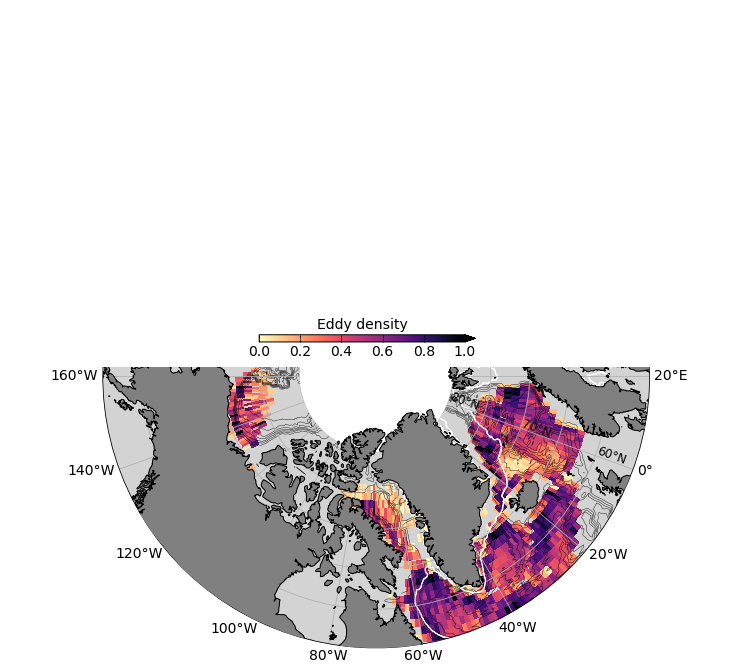

In [418]:
# one version with detection during a cycle

icycle=9
extraction_name=extraction_names[0]
take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]
minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='lightgray')



nplot=1
topotoplot=np.where(lattopo>77,np.nan,topo)
topotoplot=np.where((lontopo<-110)&(lattopo<65),np.nan,topo)
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topotoplot[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.4,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#


toplot=np.where(seasonal_ice_covered_zone_mask,1,0)
toplot=np.where(lon_ice<-61,np.nan,toplot)
plt.contour(lon_ice,lat_ice,toplot,[0,0.5,1],
             colors='w',linestyle='-',linewidths=1,
             transform=ccrs.PlateCarree())


fact=1e3

for extraction_name in extraction_names[:]:
    
    #the eddy density
    fact_ice=len(cycles_avail)/(len(cycles_avail)-boxs_stats[extraction_name]['ice']['avg']) #1 if never covered by ice, increases when ice :
    fact_ice=np.where(fact_ice>10,np.nan,fact_ice)
    toplot=boxs_stats[extraction_name]['count_sum']['both']/areas[extraction_name]*fact_ice
    toplot=np.where(toplot==0,np.nan,toplot)
    toplot=toplot*fact
    toplot=toplot/np.nanmax(toplot)/1
    
    #toplot=boxs_stats[extraction_name]['count_sum']['both']/len(cycles_avail)/areas[extraction_name]*fact #v2
    #toplot=np.where(toplot==0,np.nan,toplot)
    
    
    
    pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                boxs_stats[extraction_name]['boxs_llat'],
                toplot,vmin=0,vmax=1,cmap='magma_r',
                transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))
    ##pc=plt.contourf(boxs_stats[extraction_name]['boxs_llon'],
    #           boxs_stats[extraction_name]['boxs_llat'],
    #            toplot,np.arange(0,1,0.1),cmap='cubehelix_r',
    #            transform=ccrs.PlateCarree(),zorder=0,extend='max')#,norm = matplotlib.colors.LogNorm(0.0001,1))


cut_the_map()

cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=np.arange(0,1.2,0.2))
plt.title( r'Eddy density',fontsize=14,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
cbar_ax.set_zorder(1e6)




plt.subplots_adjust(wspace=0.05) 

plt.savefig('hotspots_north_fact_ice-v3.png',dpi=300)

plt.show()






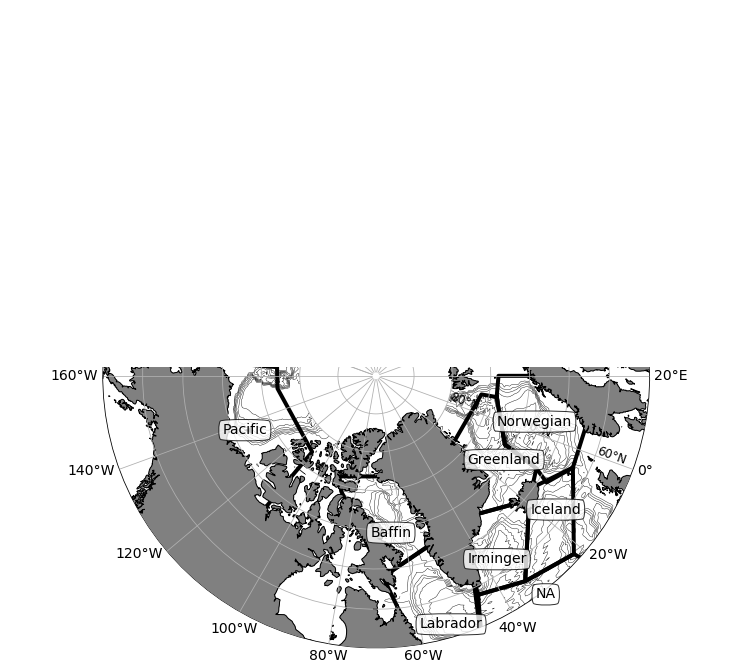

In [416]:
# one version with detection during a cycle

fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='w')



nplot=1
topotoplot=np.where(lattopo>77,np.nan,topo)
topotoplot=np.where((lontopo<-110)&(lattopo<65),np.nan,topo)
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topotoplot[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.4,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#




for izone in range(len(extraction_names)-2):
    extraction_name=extraction_names[izone]
    pt_poly=pt_poly_all[izones_ok[extraction_name]]
    plt.plot(pt_poly[0],pt_poly[1],'-k',markersize=5,lw=4,zorder=10,
             transform=ccrs.PlateCarree())
    
    x0=np.nanmean(pt_poly[0])
    y0=np.nanmean(pt_poly[1])
    t=ax.annotate(extraction_name[:-10],
            xytext=(x0,y0),
            xy=(x0,y0), 
             transform=ccrs.PlateCarree(),
            textcoords='data', #to set the position using the data we plot
            va="center", 
            ha="center",
            fontsize=14,
            zorder=10000000,
            color='k',
            bbox=dict(boxstyle="round4", fc="w",alpha=0.8), #the style of the bow around the text
            arrowprops=dict(arrowstyle="-|>",color='k') #the properties of the arrow
             )
    
    
extraction_name='Pacific-2425-v3_0'
#Pacific3bis
pt_poly=np.array([[-110,-110,-165,-165],[66,77,77,66]])


plt.plot(pt_poly[0],pt_poly[1],'-k',markersize=5,lw=4,zorder=10,
             transform=ccrs.PlateCarree())
    
x0=np.nanmean(pt_poly[0])
y0=np.nanmean(pt_poly[1])
t=ax.annotate(extraction_name[:-10],
        xytext=(x0,y0),
        xy=(x0,y0), 
         transform=ccrs.PlateCarree(),
        textcoords='data', #to set the position using the data we plot
        va="center", 
        ha="center",
        fontsize=14,
        zorder=10000000,
        color='k',
        bbox=dict(boxstyle="round4", fc="w",alpha=0.8), #the style of the bow around the text
        arrowprops=dict(arrowstyle="-|>",color='k') #the properties of the arrow
         )

cut_the_map()



plt.subplots_adjust(wspace=0.05) 

plt.savefig('areas-north.png',dpi=300)

plt.show()







from 08/05/2024 to 28/05/2024


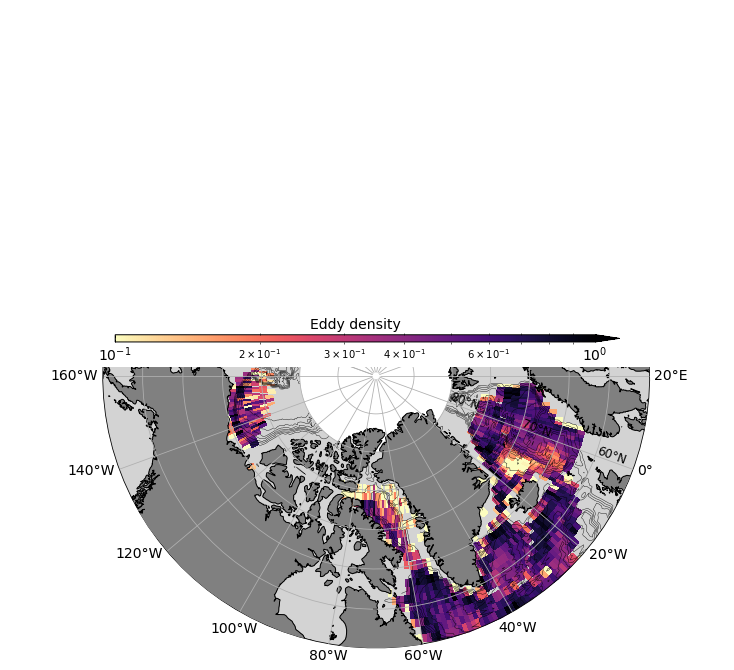

In [298]:
# one version with detection during a cycle

icycle=9
extraction_name=extraction_names[0]
take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]
minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='lightgray')



nplot=1
topotoplot=np.where(lattopo>77,np.nan,topo)
topotoplot=np.where((lontopo<-110)&(lattopo<65),np.nan,topo)
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topotoplot[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.4,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#


fact=1e3

for extraction_name in extraction_names[:]:
    
    #the eddy density
    fact_ice=len(cycles_avail)/(len(cycles_avail)-boxs_stats[extraction_name]['ice']['avg']) #1 if never covered by ice, increases when ice :
    fact_ice=np.where(fact_ice>10,np.nan,fact_ice)
    toplot=boxs_stats[extraction_name]['count_sum']['both']/areas[extraction_name]*fact_ice
    toplot=np.where(toplot==0,np.nan,toplot)
    toplot=toplot*fact
    toplot=toplot/np.nanmax(toplot)/1
    
    #toplot=boxs_stats[extraction_name]['count_sum']['both']/len(cycles_avail)/areas[extraction_name]*fact #v2
    #toplot=np.where(toplot==0,np.nan,toplot)
    
    
    
    pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                boxs_stats[extraction_name]['boxs_llat'],
                (toplot),cmap='magma_r',
                transform=ccrs.PlateCarree(),zorder=0,norm = matplotlib.colors.LogNorm(0.1,1))
    ##pc=plt.contourf(boxs_stats[extraction_name]['boxs_llon'],
    #           boxs_stats[extraction_name]['boxs_llat'],
    #            toplot,np.arange(0,1,0.1),cmap='cubehelix_r',
    #            transform=ccrs.PlateCarree(),zorder=0,extend='max')#,norm = matplotlib.colors.LogNorm(0.0001,1))


cut_the_map()

cbar_ax         = fig.add_axes( [0.15,0.55,0.7,0.01] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=[0.1,1.])
plt.title( r'Eddy density',fontsize=14,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
cbar_ax.set_zorder(1e6)




plt.subplots_adjust(wspace=0.05) 

plt.savefig('hotspots_north_log_fact_ice-v3-2425.png',dpi=300)

plt.show()






from 08/05/2024 to 28/05/2024


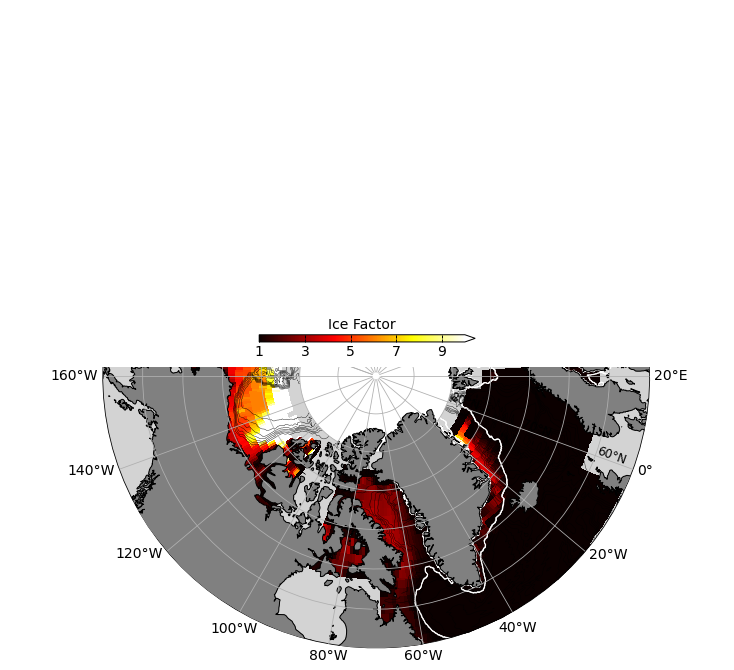

In [310]:
# one version with detection during a cycle

icycle=9
extraction_name=extraction_names[0]
take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]
minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='lightgray')



nplot=1
topotoplot=np.where(lattopo>77,np.nan,topo)
topotoplot=np.where((lontopo<-110)&(lattopo<65),np.nan,topo)
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topotoplot[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.4,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#


toplot=np.where(seasonal_ice_covered_zone_mask,1,0)
toplot=np.where(lon_ice<-61,np.nan,toplot)
plt.contour(lon_ice,lat_ice,toplot,[0,0.5,1],
             colors='w',linestyle='-',linewidths=1,
             transform=ccrs.PlateCarree())
fact=1e3

for extraction_name in extraction_names[:]:
    
    #the eddy density
    fact_ice=len(cycles_avail)/(len(cycles_avail)-boxs_stats[extraction_name]['ice']['avg']) #1 if never covered by ice, increases when ice :
    #fact_ice=np.where(fact_ice>10,np.nan,fact_ice)
    toplot=fact_ice
    toplot=np.where(boxs_stats[extraction_name]['boxs_llat']>78,np.nan,toplot)
    
    pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                boxs_stats[extraction_name]['boxs_llat'],
                toplot,vmin=1,vmax=10,cmap='hot',
                transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))
    ##pc=plt.contourf(boxs_stats[extraction_name]['boxs_llon'],
    #           boxs_stats[extraction_name]['boxs_llat'],
    #            toplot,np.arange(0,1,0.1),cmap='cubehelix_r',
    #            transform=ccrs.PlateCarree(),zorder=0,extend='max')#,norm = matplotlib.colors.LogNorm(0.0001,1))


cut_the_map()

cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=np.arange(1,12,2))
plt.title( r'Ice Factor',fontsize=14,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
cbar_ax.set_zorder(1e6)




plt.subplots_adjust(wspace=0.05) 

plt.savefig('fact_ice-v3-2425.png',dpi=300)

plt.show()






### Do a zoom for one area with nice detection showing the SWOT tracks

In [311]:
# ------------------------------------------------------------
# Custom curved Cartopy map with adjustable geographic window
# Source adapted from Rutger Kassies (StackOverflow, CC BY-SA 4.0)
# ------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

def make_curved_map2(
    lon_min=-45, lon_max=-5,
    lat_min=45, lat_max=70,
    projection_center=(-25, 58),
    projection_type='lambert',
    n_points=50,
    figsize=(12,12),lafont=14,
):
    """
    Create a Cartopy map with a curved boundary following meridians/parallels.

    Parameters
    ----------
    lon_min, lon_max : float
        Longitude range of the window.
    lat_min, lat_max : float
        Latitude range of the window.
    projection_center : tuple (lon_0, lat_0)
        Central longitude and latitude of the projection.
    projection_type : str
        'lambert' (Lambert Conformal) or 'ortho' (Orthographic).
    n_points : int
        Number of interpolation points for curved edges.
    figsize : tuple
        Figure size in inches.

    Returns
    -------
    fig, ax : Matplotlib figure and axis handles.
    """

    # --- Choose projection ---
    lon_0, lat_0 = projection_center
    if projection_type == 'lambert':
        proj = ccrs.LambertConformal(central_longitude=lon_0, central_latitude=lat_0)
    elif projection_type == 'ortho':
        proj = ccrs.Orthographic(central_longitude=lon_0, central_latitude=lat_0)
    else:
        raise ValueError("projection_type must be 'lambert' or 'ortho'")

    # --- Build curved boundary path following meridians and parallels ---
    top = list(zip(np.linspace(lon_min, lon_max, n_points), np.full(n_points, lat_max)))
    right = list(zip(np.full(n_points, lon_max), np.linspace(lat_max, lat_min, n_points)))
    bottom = list(zip(np.linspace(lon_max, lon_min, n_points), np.full(n_points, lat_min)))
    left = list(zip(np.full(n_points, lon_min), np.linspace(lat_min, lat_max, n_points)))
    boundary_path = mpath.Path(top + right + bottom + left)

    # --- Create figure and axes ---
    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)

    # Set the curved boundary and extent
    ax.set_boundary(boundary_path, transform=ccrs.PlateCarree())
    ax.set_extent((lon_min, lon_max, lat_min, lat_max))

    # --- Add some features ---
    ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='k', zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale('10m'), linewidth=0.1, zorder=2)#50mmedium 10m high
    
    
    gl = ax.gridlines(draw_labels=True, rotate_labels=False,
                      x_inline=False, y_inline=False, linestyle='-', alpha=1)
    
    
    # --- Set font size for the labels ---
    gl.xlabel_style = {'size': lafont}   # longitude labels
    gl.ylabel_style = {'size': lafont}   # latitude labels
    
    gl.top_labels = False
    gl.right_labels = False

    return fig, ax





In [312]:
extraction_name='Irminger-2425-v3_0'
path_root='/Users/cdemarez/Documents/5_SECTION19/CODE/SWOT/SWOT_TOOLS/'

path_data=path_root+'Download_ur_swot_data_v'+str(version_dwnld_code)+'/'+extraction_name+'/'
print('load SWOT grids and data')
nc=Dataset(path_data+'ssha_filtered_extracted.nc')
#print(nc.variables.keys())
SSH_all=nc['VAR'][:]
juld=nc['juld'][:]
cycle=nc['cycle'][:]
passnb_var=nc['pass_number'][:]
lon,lat=nc['lon_swath'][:],nc['lat_swath'][:]
nc.close()


icycle=14
take_cycle=cycle==cycles_avail[icycle]
ipasses=np.arange(len(juld))[take_cycle]
print(ipasses)

minjuld=np.nanmin(juld[ipasses])
meanjuld=np.nanmean(juld[ipasses]) #the middle of the cycle
maxjuld=np.nanmax(juld[ipasses])

load SWOT grids and data
[613 614 615 616 617 618 619 620 621 622 623 624 625 626 627 628 629 630
 631 632 633 634 635 636 637 638 639 640 641 642 643 644 645 646 647 648
 649 650 651 652 653 654 655 656 657 658 660]


from 20/08/2024 to 10/09/2024


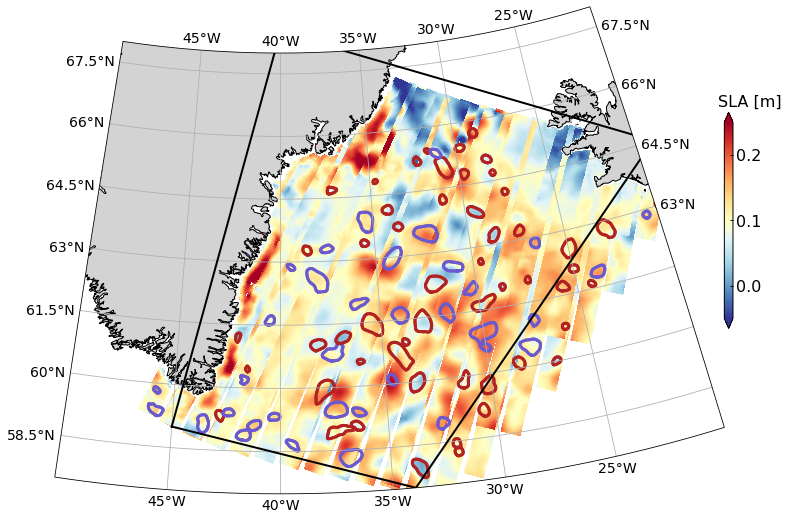

In [314]:
# one version with detection during a cycle

take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]

fig, ax = make_curved_map2(
    lon_min=-50, lon_max=-20,
    lat_min=57.5, lat_max=68,
    projection_center=(-40, 58),
    projection_type='ortho',)


whichdirection=-1
print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

for ipass in ipasses[:]:
        
    #if juld[ipass]<meanjuld:continue
    #if juld[ipass]>meanjuld:continue
    

    X,Y,SSH=lon[ipass],lat[ipass],SSH_all[ipass]
    mask=~X.mask
    X,Y,SSH=X.data[mask],Y.data[mask],SSH.data[mask]
    X=X.reshape(int(X.shape[0]/69),69)
    Y=Y.reshape(int(Y.shape[0]/69),69)
    SSH=SSH.reshape(int(SSH.shape[0]/69),69)
    tmp_direction=np.nanmean(np.sign(Y[0]-Y[-1]))
    if tmp_direction!=whichdirection:continue

    pc=plt.pcolormesh(X,Y,SSH,cmap='RdYlBu_r',vmin=-.05,vmax=.25,
                    transform=ccrs.PlateCarree())
    tmpmask=np.where(np.isnan(SSH),1,np.nan)
    plt.plot(np.nanmean(X,axis=1),np.nanmean(Y,axis=1),'--k',lw=0.5)



    for ieddy in range(len(lon_all_allareas[extraction_name])):

        if ipass_all_allareas[extraction_name][ieddy]!=ipass:continue

        if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
            continue

        if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue
        if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
        elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'    

        plt.plot(contour_lon_all_allareas[extraction_name][ieddy],
                    contour_lat_all_allareas[extraction_name][ieddy],
                    '-',c=thiscol,lw=3,
                    transform=ccrs.PlateCarree())

izone=0
plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=2,zorder=10,
        transform=ccrs.PlateCarree())

cbar_ax         = fig.add_axes( [0.9,0.5,0.01,0.25] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='both',orientation='vertical',ticks=np.arange(-0,0.5,0.1))
plt.title( r'SLA [m]',fontsize=16,x=3 )
cbar.ax.tick_params(labelsize=16,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
plt.subplots_adjust(wspace=0.05)



plt.subplots_adjust(bottom=0.25,top=0.95)
plt.savefig('example_detections-'+extraction_name+'.png',dpi=500,bbox_inches='tight')
plt.show()




In [246]:
extraction_name='Baffin-2425-v3_0'


path_data=path_root+'Download_ur_swot_data_v'+str(version_dwnld_code)+'/'+extraction_name+'/'
print('load SWOT grids and data')
nc=Dataset(path_data+'ssha_filtered_extracted.nc')
#print(nc.variables.keys())
SSH_all=nc['VAR'][:]
juld=nc['juld'][:]
cycle=nc['cycle'][:]
passnb_var=nc['pass_number'][:]
lon,lat=nc['lon_swath'][:],nc['lat_swath'][:]
nc.close()


icycle=10
take_cycle=cycle==cycles_avail[icycle]
ipasses=np.arange(len(juld))[take_cycle]
print(ipasses)

minjuld=np.nanmin(juld[ipasses])
meanjuld=np.nanmean(juld[ipasses]) #the middle of the cycle
maxjuld=np.nanmax(juld[ipasses])

load SWOT grids and data
[391 392 393 394 395 396 397 398 399 400 401 402 403 404 405 406 407 408
 409 410 411 412 413 414 415 416 417 418 419 420 421 422 423 424 425 426
 427 428 429 430 431 432 433 434 435 436 437 438 439 440 441 442 443 444
 445 446 447 448 449 450 451 452 453 454 455 456 457 458 459 460 461 462
 463 464 465]


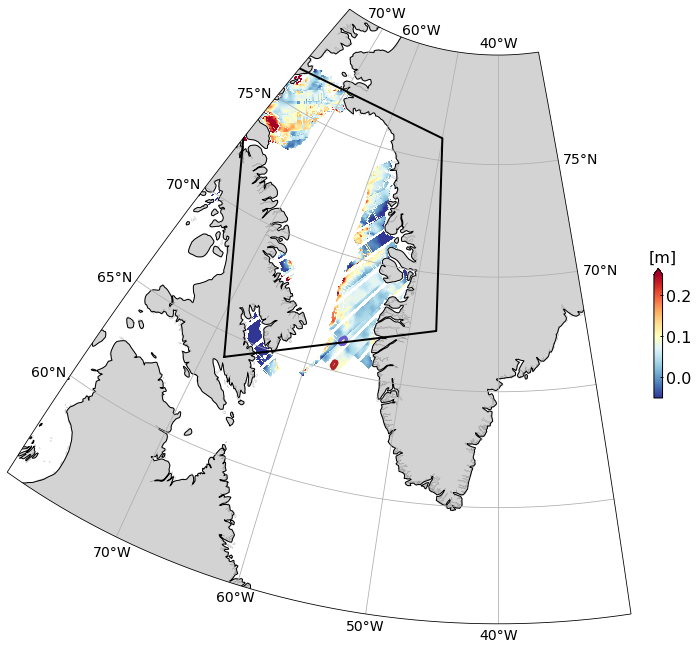

In [247]:
# one version with detection during a cycle

take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]



fig, ax = make_curved_map2(
    lon_min=-80, lon_max=-30,
    lat_min=55, lat_max=80,
    projection_center=(-40, 58),
    projection_type='ortho',)


whichdirection=-1
for ipass in ipasses[:]:
        
    if juld[ipass]<meanjuld:continue
    #if juld[ipass]>meanjuld:continue
    #print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

    #if juld[ipass]<meanjuld:continue


    X,Y,SSH=lon[ipass],lat[ipass],SSH_all[ipass]
    mask=~X.mask
    X,Y,SSH=X.data[mask],Y.data[mask],SSH.data[mask]
    X=X.reshape(int(X.shape[0]/69),69)
    Y=Y.reshape(int(Y.shape[0]/69),69)
    SSH=SSH.reshape(int(SSH.shape[0]/69),69)
    tmp_direction=np.nanmean(np.sign(Y[0]-Y[-1]))
    if tmp_direction!=whichdirection:continue

    pc=plt.pcolormesh(X,Y,SSH,cmap='RdYlBu_r',vmin=-.05,vmax=.25,
                    transform=ccrs.PlateCarree())
    tmpmask=np.where(np.isnan(SSH),1,np.nan)
    plt.plot(np.nanmean(X,axis=1),np.nanmean(Y,axis=1),'--k',lw=0.5)



    for ieddy in range(len(lon_all_allareas[extraction_name])):

        if ipass_all_allareas[extraction_name][ieddy]!=ipass:continue

        if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
            continue

        if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue
        if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
        elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'    

        plt.plot(contour_lon_all_allareas[extraction_name][ieddy],
                    contour_lat_all_allareas[extraction_name][ieddy],
                    '-',c=thiscol,lw=3,
                    transform=ccrs.PlateCarree())

#plot also the other detection from this cycle
'''
whichdirection=1
for ipass in ipasses[:]:
        
    if juld[ipass]>meanjuld:continue
    if tmp_direction!=whichdirection:continue

    for ieddy in range(len(lon_all_allareas[extraction_name])):

        if ipass_all_allareas[extraction_name][ieddy]!=ipass:continue

        if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
            continue

        if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue
        if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
        elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'    

        plt.plot(contour_lon_all_allareas[extraction_name][ieddy],
                    contour_lat_all_allareas[extraction_name][ieddy],
                    '-',c=thiscol,lw=1,
                    transform=ccrs.PlateCarree())'''




izone=izones_ok[extraction_name]
plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=2,zorder=10,
        transform=ccrs.PlateCarree())

cbar_ax         = fig.add_axes( [0.9,0.5,0.01,0.15] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='vertical',ticks=np.arange(-0,0.5,0.1))
plt.title( r'[m]',fontsize=16,x=1 )
cbar.ax.tick_params(labelsize=16,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
plt.subplots_adjust(wspace=0.05)



plt.subplots_adjust(bottom=0.25,top=0.95)
plt.savefig('example_detections-'+extraction_name+'.png',dpi=500,bbox_inches='tight')
plt.show()




In [248]:
extraction_name='Norwegian-2425-v3_0'


path_data=path_root+'Download_ur_swot_data_v'+str(version_dwnld_code)+'/'+extraction_name+'/'
print('load SWOT grids and data')
nc=Dataset(path_data+'ssha_filtered_extracted.nc')
#print(nc.variables.keys())
SSH_all=nc['VAR'][:]
juld=nc['juld'][:]
cycle=nc['cycle'][:]
passnb_var=nc['pass_number'][:]
lon,lat=nc['lon_swath'][:],nc['lat_swath'][:]
nc.close()


icycle=10
take_cycle=cycle==cycles_avail[icycle]
ipasses=np.arange(len(juld))[take_cycle]
print(ipasses)

minjuld=np.nanmin(juld[ipasses])
meanjuld=np.nanmean(juld[ipasses]) #the middle of the cycle
maxjuld=np.nanmax(juld[ipasses])

load SWOT grids and data
[690 691 692 693 694 695 696 697 698 699 700 701 702 703 704 705 706 707
 708 709 710 711 712 713 714 715 716 717 718 719 720 721 722 723 724 725
 726 727 728 729 730 731 732 733 734 735 736 737 738 739 740 741 742 743
 744 745 746 747 748 749 750 751 752 753 754 755 756 757 758 759]


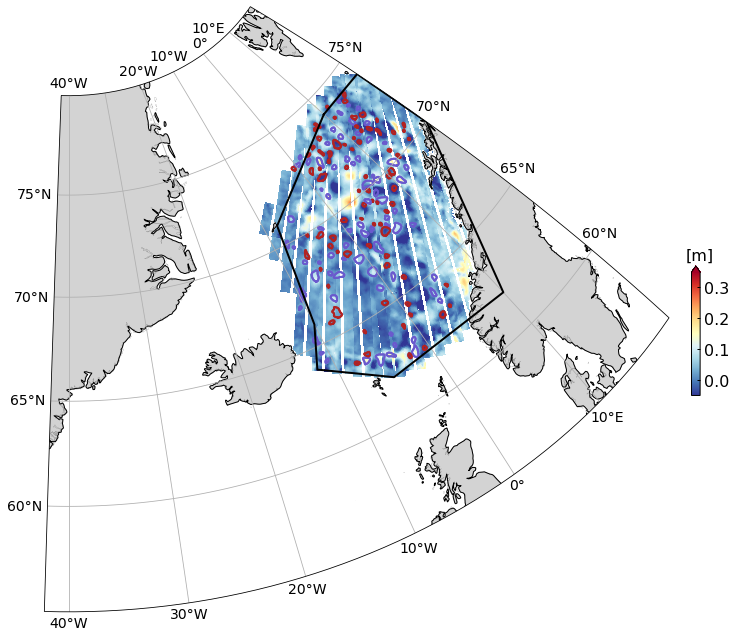

In [249]:
# one version with detection during a cycle

take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]



fig, ax = make_curved_map2(
    lon_min=-42, lon_max=20,
    lat_min=55, lat_max=80,
    projection_center=(-40, 58),
    projection_type='ortho',)


whichdirection=-1
for ipass in ipasses[:]:
        
    #if juld[ipass]<meanjuld:continue
    if juld[ipass]>meanjuld:continue
    #print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

    #if juld[ipass]<meanjuld:continue


    X,Y,SSH=lon[ipass],lat[ipass],SSH_all[ipass]
    mask=~X.mask
    X,Y,SSH=X.data[mask],Y.data[mask],SSH.data[mask]
    X=X.reshape(int(X.shape[0]/69),69)
    Y=Y.reshape(int(Y.shape[0]/69),69)
    SSH=SSH.reshape(int(SSH.shape[0]/69),69)
    tmp_direction=np.nanmean(np.sign(Y[0]-Y[-1]))
    if tmp_direction!=whichdirection:continue

    pc=plt.pcolormesh(X,Y,SSH,cmap='RdYlBu_r',vmin=-.05,vmax=.35,
                    transform=ccrs.PlateCarree())
    tmpmask=np.where(np.isnan(SSH),1,np.nan)
    plt.plot(np.nanmean(X,axis=1),np.nanmean(Y,axis=1),'--k',lw=0.5)



    for ieddy in range(len(lon_all_allareas[extraction_name])):

        if ipass_all_allareas[extraction_name][ieddy]!=ipass:continue

        if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
            continue

        if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue
        if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
        elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'    

        plt.plot(contour_lon_all_allareas[extraction_name][ieddy],
                    contour_lat_all_allareas[extraction_name][ieddy],
                    '-',c=thiscol,lw=2,
                    transform=ccrs.PlateCarree())

#plot also the other detection from this cycle
'''
whichdirection=1
for ipass in ipasses[:]:
        
    if juld[ipass]>meanjuld:continue
    if tmp_direction!=whichdirection:continue

    for ieddy in range(len(lon_all_allareas[extraction_name])):

        if ipass_all_allareas[extraction_name][ieddy]!=ipass:continue

        if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
            continue

        if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue
        if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
        elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'    

        plt.plot(contour_lon_all_allareas[extraction_name][ieddy],
                    contour_lat_all_allareas[extraction_name][ieddy],
                    '-',c=thiscol,lw=1,
                    transform=ccrs.PlateCarree())'''




izone=izones_ok[extraction_name]
plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=2,zorder=10,
        transform=ccrs.PlateCarree())

cbar_ax         = fig.add_axes( [0.9,0.5,0.01,0.15] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='vertical',ticks=np.arange(-0,0.5,0.1))
plt.title( r'[m]',fontsize=16,x=1 )
cbar.ax.tick_params(labelsize=16,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
plt.subplots_adjust(wspace=0.05)



plt.subplots_adjust(bottom=0.25,top=0.95)
plt.savefig('example_detections-'+extraction_name+'.png',dpi=500,bbox_inches='tight')
plt.show()




# Plot parameters map !

In [ ]:
# one version with detection during a cycle

icycle=9
extraction_name=extraction_names[0]
take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]
minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

fig, ax = make_curved_map(
    lon_min=-80, lon_max=20,
    lat_min=50, lat_max=80,
    projection_center=(-40, 58),
    projection_type='ortho',)

nplot=10
plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topo[::nplot,::nplot],
            np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
            transform=ccrs.PlateCarree())#

toplot=np.where(n_cycles_ice_covered<18,np.nan,n_cycles_ice_covered)
plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,19,1),cmap='binary',
             transform=ccrs.PlateCarree()) #en noir tt le temps couvert de glace


plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
             colors='k',linestyle='-',linewidths=0.5,
             transform=ccrs.PlateCarree())
#plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
#             colors='none',
#             hatches=['','//',],
#             transform=ccrs.PlateCarree()) #en hachuré la SIZ

fact=1e3

for extraction_name in extraction_names[:]:
    toplot=boxs_stats[extraction_name]['count_sum']['both']/len(cycles_avail)/areas[extraction_name]*fact #v2
    toplot=np.where(toplot==0,np.nan,toplot)
    pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                boxs_stats[extraction_name]['boxs_llat'],
                toplot,vmin=0,vmax=1,cmap='cubehelix_r',
                transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))




for extraction_name in extraction_names[:]:

    take_cycle=cycle_all_allareas[extraction_name]==cycles_avail[icycle]

    #minjuld=np.nanmin(juld_all_allareas[extraction_name][take_cycle])
    #meanjuld=np.nanmean(juld_all_allareas[extraction_name][take_cycle]) #the middle of the cycle
    #maxjuld=np.nanmax(juld_all_allareas[extraction_name][take_cycle])

    #print('from '+OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")+' to '+OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y"))

    for ieddy in range(len(lon_all_allareas[extraction_name])):

        if take_cycle[ieddy]==False:continue

        if depth_all_allareas[extraction_name][ieddy]>min_depth or np.isnan(depth_all_allareas[extraction_name][ieddy]):
            continue

        if ice_all_allareas[extraction_name][ieddy]>max_ice_conc:continue



        if pol_all_allareas[extraction_name][ieddy]==-1:thiscol='slateblue'
        elif pol_all_allareas[extraction_name][ieddy]==+1:thiscol='firebrick'    

        plt.plot(contour_lon_all_allareas[extraction_name][ieddy]-360,
                    contour_lat_all_allareas[extraction_name][ieddy],
                    '-',c=thiscol,lw=0.5,
                    transform=ccrs.PlateCarree())


        #plt.plot(lon_all_allareas[extraction_name][ieddy]-360,
        #         lat_all_allareas[extraction_name][ieddy],
        #         '.',c=thiscol,
        #          transform=ccrs.PlateCarree())



cbar_ax         = fig.add_axes( [0.35,0.95,0.1,0.015] )
cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=np.arange(0,2.5,0.5))
plt.title( r'Eddy density',fontsize=14,x=0.5 )
cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
cbar.ax.xaxis.set_label_position('top')
cbar.ax.xaxis.set_ticks_position('both')
cbar.outline.set_linewidth(1) 
plt.subplots_adjust(wspace=0.05) 

#for izone in range(len(pt_poly_all)):
#    plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=1,zorder=10,
#            transform=ccrs.PlateCarree())

plt.subplots_adjust(bottom=0.25,top=0.95)

plt.savefig('hotspots_north_plusdetections.png',dpi=500,bbox_inches='tight')

plt.show()






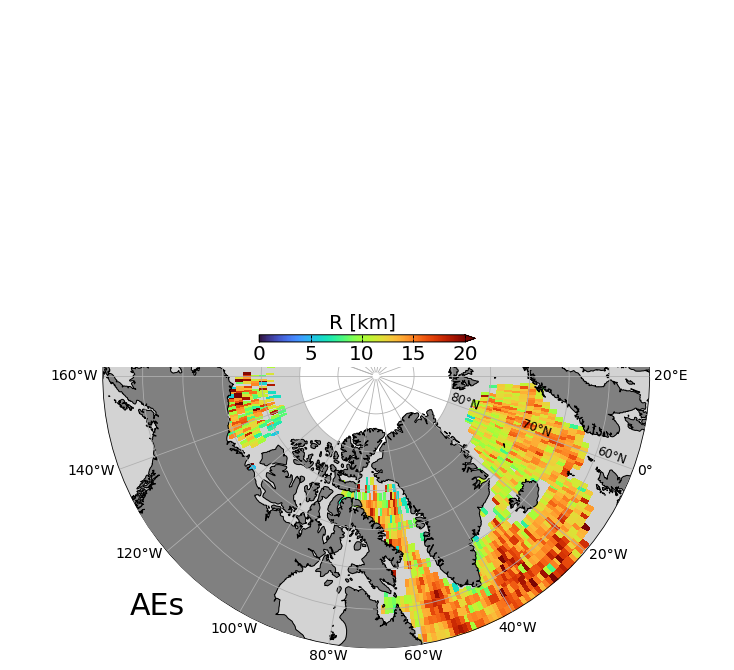

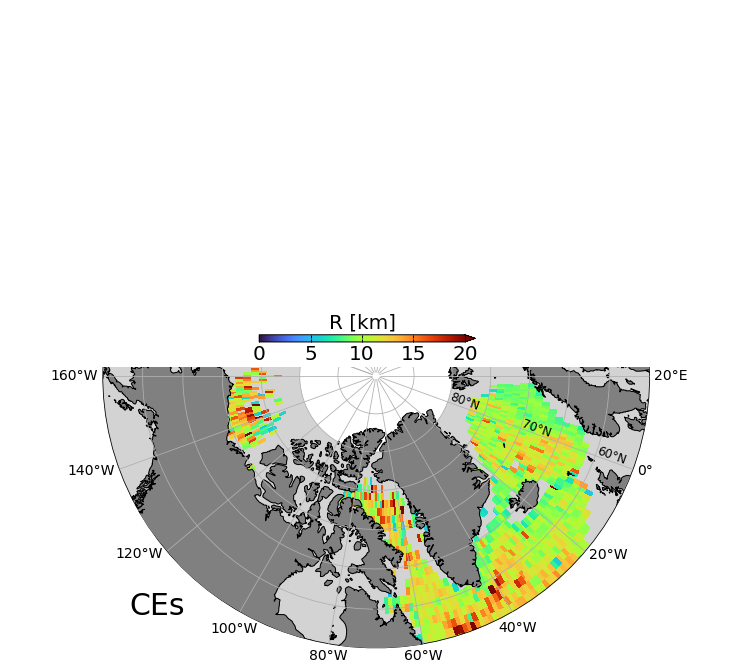

In [315]:
for pol in pols:


    fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='lightgray')



    nplot=10
    #plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topo[::nplot,::nplot],
    #            np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
    #           transform=ccrs.PlateCarree())#

    #toplot=np.where(n_cycles_ice_covered<18,np.nan,n_cycles_ice_covered)
    #plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,19,1),cmap='binary',
    #             transform=ccrs.PlateCarree()) #en noir tt le temps couvert de glace


    #plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #             colors='k',linestyle='-',linewidths=0.5,
    #             transform=ccrs.PlateCarree())
    #plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #             colors='none',
    #             hatches=['','//',],
    #             transform=ccrs.PlateCarree()) #en hachuré la SIZ


    mask4plot=boxs_stats['all']['count']['both']/len(cycles_avail)<0.5
    #toplot=boxs_stats['all']['radius'][str(pol)]['avg']
    #toplot=np.where(mask4plot,np.nan,toplot)
    #pc=plt.contourf(boxs_llon,boxs_llat,toplot,np.arange(0,25,1),cmap='turbo',
    #             transform=ccrs.PlateCarree(),zorder=0,extend='max')
    
    
    for extraction_name in extraction_names[:]:
        toplot=boxs_stats[extraction_name]['radius'][str(pol)]['avg']
        toplot=np.where(toplot<5,np.nan,toplot)
        
        
        
        
        pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                    boxs_stats[extraction_name]['boxs_llat'],
                    toplot,vmin=0,vmax=20,cmap='turbo',
                    transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))

        #pc=plt.contourf(boxs_stats[extraction_name]['boxs_llon'],
        #                boxs_stats[extraction_name]['boxs_llat'],
        #                toplot,np.arange(0,25,1),cmap='turbo',
        #         transform=ccrs.PlateCarree(),zorder=0,extend='max')


    if pol==-1:labpol='AEs'
    elif pol==1:labpol='CEs'
        
    plt.title(labpol,fontsize=30,y=0.05,x=0.1)
        
        


    cut_the_map()
    cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
    cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=np.arange(0,25,5))
    plt.title( r'R [km]',fontsize=20,x=0.5 )# for '+labpol
    cbar.ax.tick_params(labelsize=20,direction='in',width=1,size=3)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.xaxis.set_ticks_position('both')
    cbar.outline.set_linewidth(1) 
    cbar_ax.set_zorder(1e6)

    #for izone in range(len(pt_poly_all)):
    #    plt.plot(pt_poly_all[izone][0],pt_poly_all[izone][1],'-k',markersize=5,lw=1,zorder=10,
    #            transform=ccrs.PlateCarree())

    #plt.subplots_adjust(bottom=0.25,top=0.90)
    
    plt.savefig('R_north'+labpol+'.png',dpi=500,bbox_inches='tight')

    plt.show()

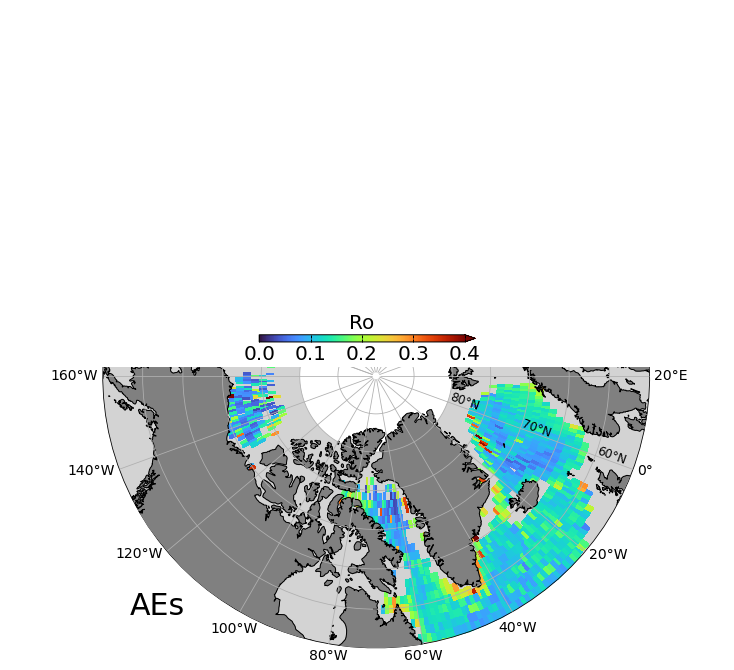

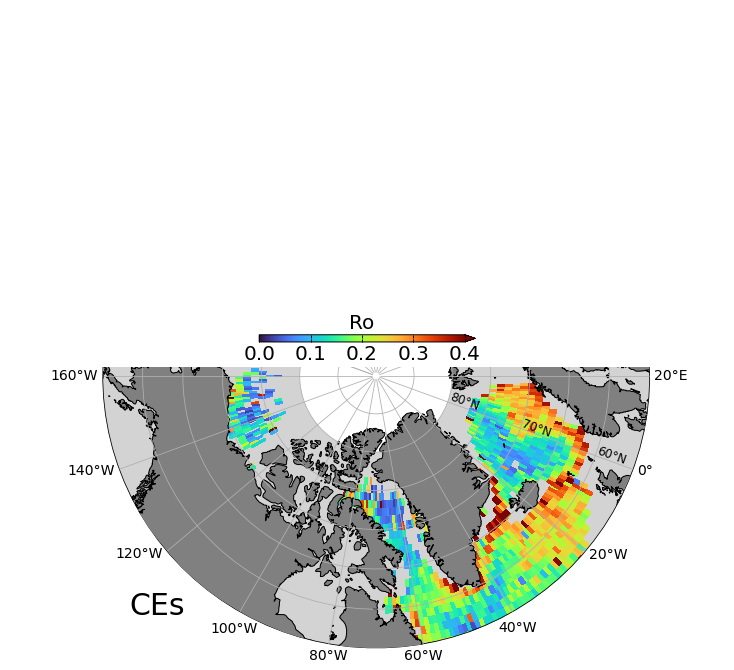

In [319]:
for pol in pols:


    fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='lightgray')


    #nplot=10
    #plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topo[::nplot,::nplot],
    #            np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
    #            transform=ccrs.PlateCarree())#

    ##toplot=np.where(n_cycles_ice_covered<18,np.nan,n_cycles_ice_covered)
    #plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,19,1),cmap='binary',
    #             transform=ccrs.PlateCarree()) #en noir tt le temps couvert de glace


    #plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #             colors='k',linestyle='-',linewidths=0.5,
    #             transform=ccrs.PlateCarree())
    #plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #             colors='none',
    #             hatches=['','//',],
    #             transform=ccrs.PlateCarree()) #en hachuré la SIZ


    #mask4plot=boxs_stats['all']['count']['both']/len(cycles_avail)<0.5
    
    #toplot=boxs_stats['all']['Ro'][str(pol)]['avg']
    #toplot=np.where(mask4plot,np.nan,toplot)
    
    
    for extraction_name in extraction_names[:]:
        toplot=boxs_stats[extraction_name]['Ro'][str(pol)]['avg']
        toplot=np.where(toplot<0.01,np.nan,toplot)
        
        
        
        
        pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                    boxs_stats[extraction_name]['boxs_llat'],
                    toplot,vmin=0,vmax=0.4,cmap='turbo',
                    transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))

    
    
    #pc=plt.contourf(boxs_llon,boxs_llat,toplot,np.arange(0,0.55,0.05),cmap='turbo',
    #             transform=ccrs.PlateCarree(),zorder=0,extend='max')


    if pol==-1:labpol='AEs'
    elif pol==1:labpol='CEs'
        
    plt.title(labpol,fontsize=30,y=0.05,x=0.1)
            
        
    cut_the_map()
    cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
    cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=np.arange(0,0.6,0.1))
    plt.title( r'Ro',fontsize=20,x=0.5 )# for '+labpol
    cbar.ax.tick_params(labelsize=20,direction='in',width=1,size=3)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.xaxis.set_ticks_position('both')
    cbar.outline.set_linewidth(1) 
    cbar_ax.set_zorder(1e6)


    
    plt.savefig('Ro_north'+labpol+'.png',dpi=500,bbox_inches='tight')

    plt.show()

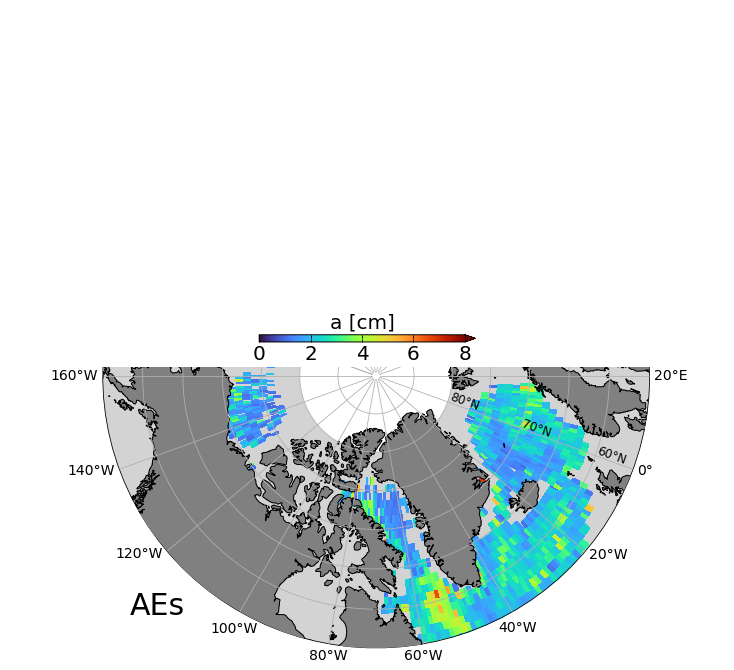

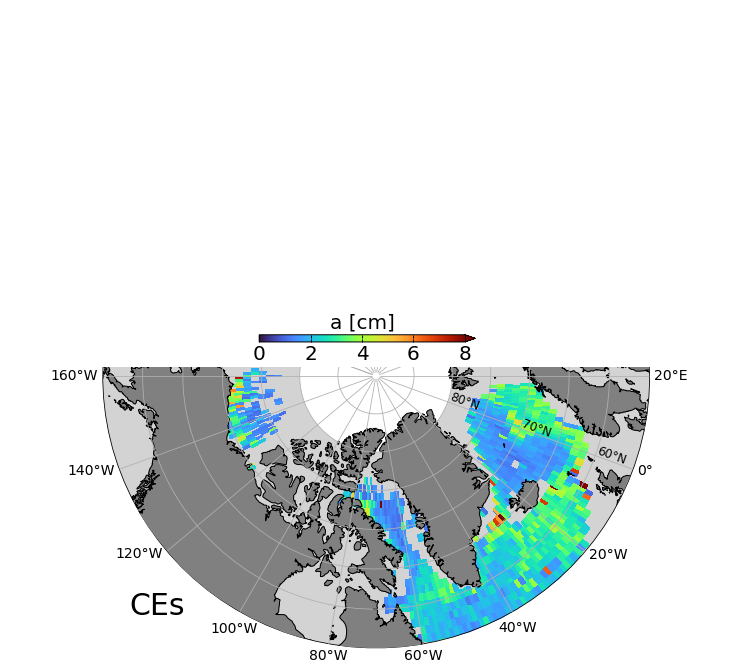

In [321]:
for pol in pols:


    fig,ax=make_curved_map_north(lat_min=55,central_longitude=-70,figsize=(10, 10),facecol='lightgray')


    #nplot=10
    #plt.contour(lontopo[::nplot,::nplot],lattopo[::nplot,::nplot],topo[::nplot,::nplot],
    #            np.arange(-4000,100,500),colors='k',linewidths=0.2,linestyles='-',zorder=1,
    #            transform=ccrs.PlateCarree())#

    ##toplot=np.where(n_cycles_ice_covered<18,np.nan,n_cycles_ice_covered)
    #plt.contourf(lon_ice,lat_ice,toplot,np.arange(0,19,1),cmap='binary',
    #             transform=ccrs.PlateCarree()) #en noir tt le temps couvert de glace


    #plt.contour(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #             colors='k',linestyle='-',linewidths=0.5,
    #             transform=ccrs.PlateCarree())
    #plt.contourf(lon_ice,lat_ice,np.where(seasonal_ice_covered_zone_mask,1,0),[0,0.5,1],
    #             colors='none',
    #             hatches=['','//',],
    #             transform=ccrs.PlateCarree()) #en hachuré la SIZ


    #mask4plot=boxs_stats['all']['count']['both']/len(cycles_avail)<0.5
    
    #toplot=boxs_stats['all']['Ro'][str(pol)]['avg']
    #toplot=np.where(mask4plot,np.nan,toplot)
    
    
    for extraction_name in extraction_names[:]:
        toplot=boxs_stats[extraction_name]['a'][str(pol)]['avg']*100
        toplot=np.where(toplot<1,np.nan,toplot)
        
        
        
        
        pc=plt.pcolormesh(boxs_stats[extraction_name]['boxs_llon'],
                    boxs_stats[extraction_name]['boxs_llat'],
                    toplot,vmin=0,vmax=8,cmap='turbo',
                    transform=ccrs.PlateCarree(),zorder=0)#,norm = matplotlib.colors.LogNorm(0.0001,1))

    
    
    #pc=plt.contourf(boxs_llon,boxs_llat,toplot,np.arange(0,0.55,0.05),cmap='turbo',
    #             transform=ccrs.PlateCarree(),zorder=0,extend='max')


    if pol==-1:labpol='AEs'
    elif pol==1:labpol='CEs'
        
    plt.title(labpol,fontsize=30,y=0.05,x=0.1)
            
        
    cut_the_map()
    cbar_ax         = fig.add_axes( [0.35,0.55,0.3,0.01] )
    cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',orientation='horizontal',ticks=np.arange(0,10,2))
    plt.title( r'a [cm]',fontsize=20,x=0.5 )# for '+labpol
    cbar.ax.tick_params(labelsize=20,direction='in',width=1,size=3)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.xaxis.set_ticks_position('both')
    cbar.outline.set_linewidth(1) 
    cbar_ax.set_zorder(1e6)


    
    plt.savefig('a_north'+labpol+'.png',dpi=500,bbox_inches='tight')

    plt.show()

# Do cycle count, per areas to see how it evolves over time !

In [326]:
minjuld=np.nanmin(juld_all_ok)
maxjuld=np.nanmax(juld_all_ok)

In [325]:
OrdinalToDatetime(int(minjuld-1721424.5)).strftime("%d/%m/%Y")

'02/11/2023'

In [327]:
OrdinalToDatetime(int(maxjuld-1721424.5)).strftime("%d/%m/%Y")

'21/11/2025'

In [403]:
max_ice_conc

15

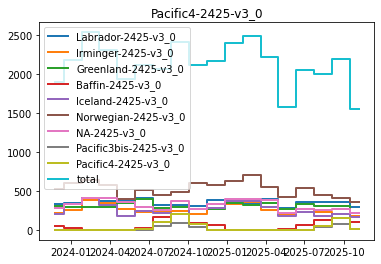

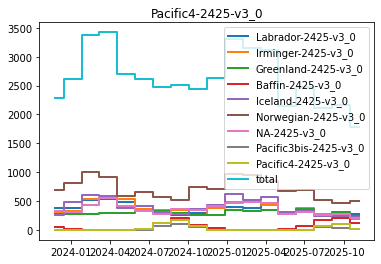

In [380]:
#juld_all_SIZ=[]


dw=42
bin_edges=np.arange(minjuld,maxjuld+dw,dw)
bin_centers=0.5*(bin_edges[1:]+bin_edges[:-1])

hist_number={}
for pol in [-1,1]:
    
    itmp=0
    hist_number[str(pol)]={}
    
    

    for extraction_name in extraction_names:


        take1=ice_all_allareas[extraction_name]<max_ice_conc
        take2=depth_all_allareas[extraction_name]<min_depth 
        take3=~np.isnan(depth_all_allareas[extraction_name])
        #take_SIZ=in_SIZ_all_allareas[extraction_name]
        take_pol=pol_all_allareas[extraction_name]==pol
        take=take1&take2&take3&take_pol



        hist, _ = np.histogram(juld_all_allareas[extraction_name][take],bin_edges)
        datetmp=np.array([OrdinalToDatetime(int(i-1721424.5)) for i in bin_centers])
        plt.step(datetmp,hist,
                                 where='mid',
                                 linewidth=2,
                                 label=extraction_name)
        
        hist_number[str(pol)][extraction_name]=np.copy(hist)
        if itmp==0:
            hist_number[str(pol)]['all']=np.copy(hist)
        else:
            hist_number[str(pol)]['all']+=hist
            
        itmp+=1


    plt.step(datetmp,hist_number[str(pol)]['all'],
                                 where='mid',
                                 linewidth=2,
                                 label='total')
    plt.title(extraction_name)
    plt.legend()



    plt.show()

In [381]:
for pol in [-1,1]:
    hist_number[str(pol)]['Pacific-2425-v3_0']=hist_number[str(pol)]['Pacific4-2425-v3_0']+hist_number[str(pol)]['Pacific3bis-2425-v3_0']
    
    
extraction_names_tmp=extraction_names[:-2]+['Pacific-2425-v3_0']

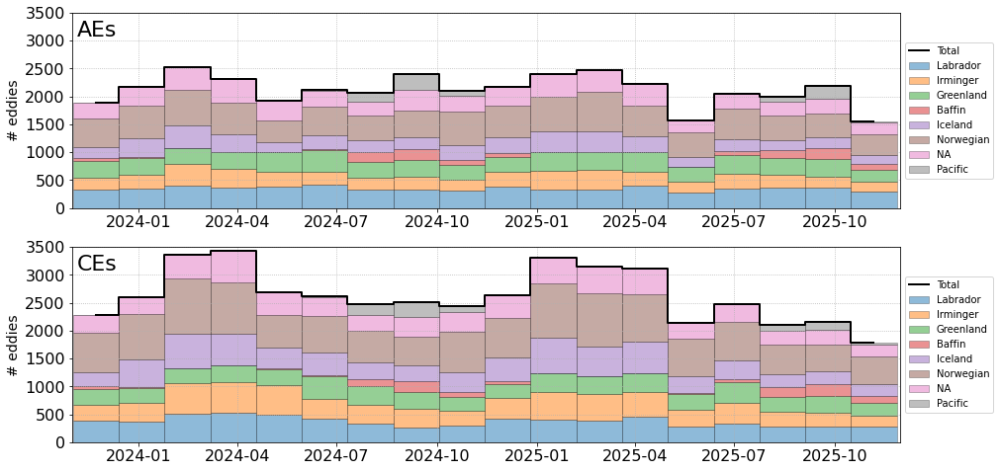

In [401]:
colors = plt.get_cmap("tab10").colors  # 10 couleurs sobres et distinctes

#import seaborn as sns; colors =sns.color_palette("deep")

plt.figure(figsize=(15,8))
itmp=0
for pol in pols:
    ax=plt.subplot(2,1,1+itmp)
    
    bott=0
    
    itmp2=0
    
    plt.step(datetmp,hist_number[str(pol)]['all'],c='k',
                                 where='mid',
                                 linewidth=2,
                                 label='Total')
    for extraction_name in extraction_names_tmp[:]:
        datetmp=np.array([OrdinalToDatetime(int(i-1721424.5)) for i in bin_centers])

        histtmp=hist_number[str(pol)][extraction_name]


        plt.bar(datetmp,histtmp,width=dw,bottom=bott,label=extraction_name[:-10],
                color=colors[itmp2],
                ec='k',lw=0.5,alpha=0.5)

        bott+=histtmp
        
        itmp2+=1

    
    
    
    ax.set_xlim(datetime.datetime(2023,11,1),datetime.datetime(2025,11,30))
    ax.set_ylim(0,3500)
    #plt.xticks([datetime.datetime(2024,i,15) for i in [3,6,9,12]],['Mar.','Jun.','Sep.','Dec.'],fontsize=16)
    plt.xticks(fontsize=16)
    
    plt.yticks(fontsize=16)

    #if itmp==0:
        
    plt.ylabel('# eddies',fontsize=14)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
        
    if pol==-1:labpol='AEs'
    elif pol==1:labpol='CEs'
    plt.title(labpol+'',fontsize=22,y=0.85,x=0.03)
    
    plt.grid(ls=':')
    itmp+=1
    
plt.subplots_adjust(hspace=0.2)
plt.savefig('hist_north.png',dpi=500,bbox_inches='tight')

plt.show()

# Plot analysis of SIZ eddies

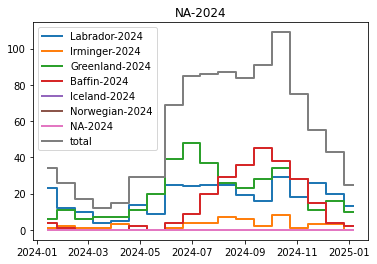

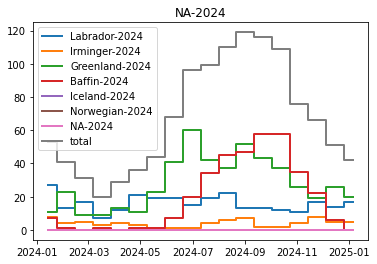

In [75]:
#juld_all_SIZ=[]


dw=21
bin_edges=np.arange(2460313.5,2460313.5+365+dw,dw)
bin_centers=0.5*(bin_edges[1:]+bin_edges[:-1])

hist_SIZ={}
for pol in [-1,1]:
    
    itmp=0
    hist_SIZ[str(pol)]={}
    
    

    for extraction_name in extraction_names:


        take1=ice_all_allareas[extraction_name]<max_ice_conc
        take2=depth_all_allareas[extraction_name]<min_depth 
        take3=~np.isnan(depth_all_allareas[extraction_name])
        take_SIZ=in_SIZ_all_allareas[extraction_name]
        take_pol=pol_all_allareas[extraction_name]==pol
        take=take1&take2&take3&take_SIZ&take_pol



        hist, _ = np.histogram(juld_all_allareas[extraction_name][take],bin_edges)
        datetmp=np.array([OrdinalToDatetime(int(i-1721424.5)) for i in bin_centers])
        plt.step(datetmp,hist,
                                 where='mid',
                                 linewidth=2,
                                 label=extraction_name)
        
        hist_SIZ[str(pol)][extraction_name]=np.copy(hist)
        if itmp==0:
            hist_SIZ[str(pol)]['all']=np.copy(hist)
        else:
            hist_SIZ[str(pol)]['all']+=hist
            
        itmp+=1


    plt.step(datetmp,hist_SIZ[str(pol)]['all'],
                                 where='mid',
                                 linewidth=2,
                                 label='total')
    plt.title(extraction_name)
    plt.legend()



    plt.show()

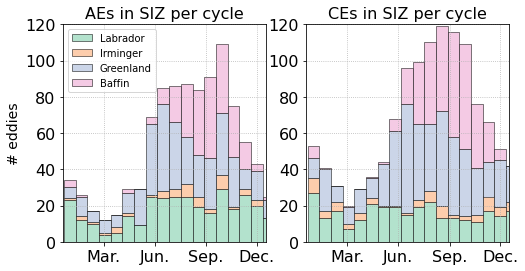

In [81]:
colors = plt.get_cmap("Pastel2").colors  # 10 couleurs sobres et distinctes

#import seaborn as sns; colors =sns.color_palette("deep")

plt.figure(figsize=(8,4))
itmp=0
for pol in pols:
    ax=plt.subplot(1,2,1+itmp)
    
    bott=0
    
    itmp2=0
    for extraction_name in extraction_names[:4]:
        datetmp=np.array([OrdinalToDatetime(int(i-1721424.5)) for i in bin_centers])

        histtmp=hist_SIZ[str(pol)][extraction_name]


        plt.bar(datetmp,histtmp,width=21,bottom=bott,label=extraction_name[:-5],
                color=colors[itmp2],
                ec='k',lw=0.5,alpha=1)

        bott+=histtmp
        
        itmp2+=1

        
    ax.set_xlim(datetime.datetime(2024,1,1),datetime.datetime(2024,12,31))
    ax.set_ylim(0,120)
    plt.xticks([datetime.datetime(2024,i,15) for i in [3,6,9,12]],['Mar.','Jun.','Sep.','Dec.'],fontsize=16)
    plt.yticks(fontsize=16)

    if itmp==0:
        
        plt.ylabel('# eddies',fontsize=14)
        plt.legend()
        
    if pol==-1:labpol='AEs'
    elif pol==1:labpol='CEs'
    plt.title(labpol+' in SIZ per cycle',fontsize=16)
    
    plt.grid(ls=':')
    itmp+=1
    
plt.savefig('hists_SIZ_north.png',dpi=500,bbox_inches='tight')

plt.show()

In [82]:
import matplotlib as mpl
print(mpl.rcParams['font.family'])

['sans-serif']


## La peut etre changer de diags, et regarder l'amplitude

In [169]:
boxs_r=np.arange(-30,32,2)
boxs_a=np.arange(-0.2,0.2,0.01)
boxs_aa,boxs_rr=np.meshgrid(boxs_a,boxs_r)

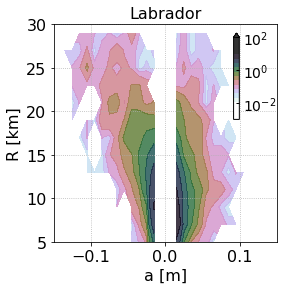

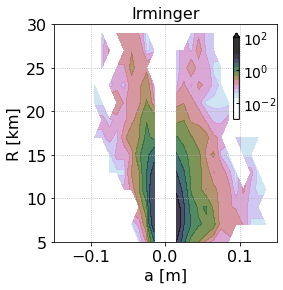

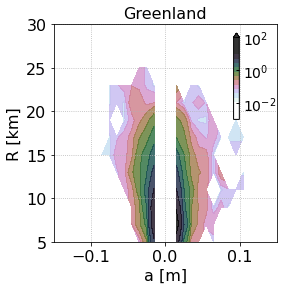

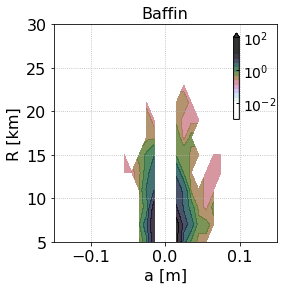

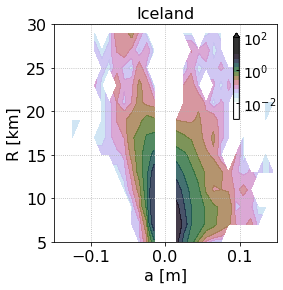

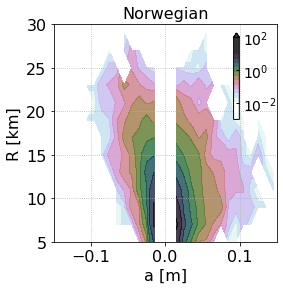

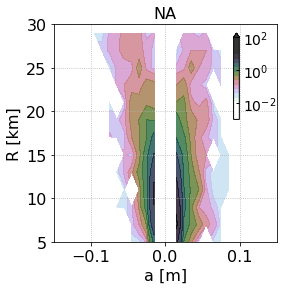

In [193]:
for extraction_name in extraction_names:


    take1=ice_all_allareas[extraction_name]<max_ice_conc
    take2=depth_all_allareas[extraction_name]<min_depth 
    take3=~np.isnan(depth_all_allareas[extraction_name])
    take_SIZ=in_SIZ_all_allareas[extraction_name]
    take_pol=pol_all_allareas[extraction_name]==pol
    take=take1&take2&take3#&take_SIZ#&take_pol
    tmp1 = a_all_allareas[extraction_name][take]*pol_all_allareas[extraction_name][take]
    tmp2= r_all_allareas[extraction_name][take]
    hist2d_tmp=count_boxes(boxs_a,boxs_r,tmp1,tmp2)
    
    
    take=take1&take2&take3&take_SIZ#&take_pol
    tmp1 = a_all_allareas[extraction_name][take]*pol_all_allareas[extraction_name][take]
    tmp2= r_all_allareas[extraction_name][take]
    hist2d_tmp2=count_boxes(boxs_a,boxs_r,tmp1,tmp2)
    
    #plt.plot(tmp1,tmp2,'o')
    #plt.show()
    
    
    
    
    fig=plt.figure(figsize=(4,4))
    ax=plt.subplot(111)
    plt.title(extraction_name[:-5],fontsize=16)
    
    tmpplot=hist2d_tmp/np.nansum(hist2d_tmp)*100
    
    #pc=plt.pcolormesh(boxs_a,boxs_r+1,tmpplot,shading='nearest',cmap='cubehelix_r',alpha=0.8,norm = matplotlib.colors.LogNorm(0.01,10))
    pc=plt.contourf(boxs_a+0.005,boxs_r+1,tmpplot,np.logspace(-3,2,20),cmap='cubehelix_r',
                    alpha=0.8,norm = matplotlib.colors.LogNorm(0.01,10),extend='max')
      
    #plt.contour(boxs_a,boxs_r+1,tmpplot,[0.1],linewidths=0.5,colors='k',linestyle='--')
    
    
    
    #tmpplot=hist2d_tmp2/np.nansum(hist2d_tmp2)*100
    #plt.contour(boxs_a,boxs_r+1,tmpplot,[0.1],linewidths=1,colors='k',linestyle='-')
    
    plt.grid(ls=':')
    ax.set_xlim(-0.15,0.15)
    ax.set_ylim(5,30)
    plt.xticks([-0.1,0,0.1],fontsize=16)
    plt.yticks(fontsize=16)
    plt.xlabel('a [m]',fontsize=16)  
    plt.ylabel('R [km]',fontsize=16)
    cbar_ax         = fig.add_axes( [0.75,0.55,0.02,0.3] )
    cbar            = fig.colorbar( pc , cax=cbar_ax,extend='max',
                                   orientation='vertical',ticks=[0.01,1,100])
    #plt.title( r'% of eddies',fontsize=16,x=0.5 )# for '+labpol
    cbar.ax.tick_params(labelsize=14,direction='in',width=1,size=3)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.xaxis.set_ticks_position('both')
    cbar.outline.set_linewidth(1) 
    plt.subplots_adjust(wspace=0.05) 
    
    plt.savefig('hists_2d_Ra-'+extraction_name+'.png',dpi=500,bbox_inches='tight')
    
    plt.show()

NameError: name 'hist2d_tmp' is not defined

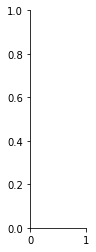

In [80]:
fig=plt.figure(figsize=(1,4))
ax=plt.subplot(111)
ax.spines['right'].set_linewidth(0)
ax.spines['top'].set_linewidth(0)
plt.barh(boxs_r+1,np.nansum(hist2d_tmp,axis=1),height=2,
        color='grey',alpha=0.5,ec='k',lw=1,)
ax.set_ylim(-30,30)
plt.grid(ls=':')
plt.xticks([0,200],fontsize=16)
plt.yticks([-30,-20,-10,0,10,20,30],['','','','','','','',],fontsize=16)

plt.savefig('hists_2d_cumul_north.png',dpi=500,bbox_inches='tight')

plt.show()